# Explore merging ranks by weighted avg

In [1]:
import os
from random import randint
from itertools import combinations
from scipy.stats import binom, geom, spearmanr, pearsonr
import numpy as np
import pandas as pd
pd.options.display.max_rows = 40

from ete3 import Tree

from itertools import combinations, product
from collections import Counter

In [2]:
# import matplotlib
import matplotlib.pyplot as plt
import matplotlib.patches as mplpatches
%matplotlib inline

plt.rcParams['figure.dpi'] = 300
plt.rcParams['agg.path.chunksize'] = 10000



In [3]:
# import plotnine

from plotnine import \
    ggplot, aes, theme, themes, element_blank, element_line, element_text, mapping, \
    geom_point, geom_jitter, geom_line, geom_bar, geom_boxplot, geom_violin, geom_histogram, \
    ggtitle, xlab, ylab, geom_vline, geom_hline, geom_abline, geom_col, geom_tile, geom_smooth, \
    scale_x_discrete, scale_y_discrete, scale_x_continuous, scale_y_continuous, \
    scale_color_discrete, scale_fill_manual, scale_fill_hue, scale_fill_gradient, scale_color_manual, scale_color_hue,  scale_color_gradient2, \
    geom_rect, \
    guides, after_stat, \
    xlim, ylim
from plotnine.options import figure_size
from mizani.formatters import percent_format

# plotnine theme
def theme_tufte_func(base_size=19, base_family="sans", rotate=True, figure_size=None):
    ''' Plotnine plotting theme. '''
    thm = themes.theme_bw(base_size=base_size, base_family = base_family) + \
        theme(
            legend_background = element_blank(),
            legend_key = element_blank(),
            panel_background = element_blank(),
            panel_border = element_blank(),
            strip_background = element_blank(),
            plot_background = element_blank(),
            panel_grid = element_blank(),
            axis_line = element_line(colour = "black", size = 1),
            axis_text_y = element_text(colour = "black")
        )

    if rotate:
        thm += theme(axis_text_x=element_text(rotation=45, hjust=1))
    if figure_size is not None:
        thm += theme(figure_size=figure_size)
    return thm


In [4]:
def dist_tree_calc(filename1):
    ''' Calculate tree distance. '''
    tree1= Tree(filename1,format=1)
    # print('Tree from', filename1, 'len:', len(tree1))
    dist_tree={}
    samples = [i.name for i in tree1.get_leaves()]
    num_sample = len(samples)
    for i in range(num_sample):
        tax_i = samples[i]
        for j in range(i+1,num_sample):
            tax_j = samples[j]
            dist_tree[(min(tax_i, tax_j)+".fa", max(tax_i, tax_j)+".fa")] = tree1.get_distance(tax_i, tax_j, topology_only=False)
    # print('num samples:', num_sample)
    # print('xxx:', num_sample * (num_sample-1)/2)
    # print('tree len:', len(dist_tree))
    return dist_tree



In [5]:
def yield_file_lines(path):
    ''' Read file from path line-by-line. '''
    with open(path, 'r') as in_file:
        for line in in_file:
            yield line.strip()

In [6]:
def calc_corr(l1, l2, pearson=False, prnt=False):
    if pearson:
        corr, pval = pearsonr(l1, l2)
    else:
        corr, pval = spearmanr(l1, l2)
    if prnt:
        print("Correlation coefficient:", corr)
        print("p-value:", pval)
    return corr, pval

# get tree distances

In [7]:
l = []

tree_path = '/Users/stephenhwang/Documents/projects/langmead_lab/MEM-ANI/data/cyano/o__Cyanobacteriales.nwk'

tree1 = Tree(tree_path, format=1)

dist_tree = dist_tree_calc(tree_path)
species_pair_list = list(dist_tree.keys())
dist_tree_list = [dist_tree[pair] for pair in species_pair_list]
for pair, dist in list(zip(species_pair_list, dist_tree_list)):
    l.append([*pair ,dist])


names = set()
for g1, g2, d in l:
    g1 = g1.rstrip('.fa')
    g2 = g2.rstrip('.fa')
    names.add(g1)
    names.add(g2)


tree_dict = {_:{_:0 for _ in names} for _ in names}

for g1, g2, d in l:
    d = float(d)
    g1 = g1.rstrip('.fa')
    g2 = g2.rstrip('.fa')
    tree_dict[g1][g2] = d
    tree_dict[g2][g1] = d

len(tree_dict)

585

In [8]:
# parse data into dfs

dir_path = '/Users/stephenhwang/Documents/projects/langmead_lab/MEM-ANI/data/cyano/dashing_full_genomes'

# Get list of files in directory
files = [f for f in os.listdir(dir_path) if os.path.isfile(os.path.join(dir_path, f))]

# Create a dictionary to store dataframes
dashing_dfs = {}

# Read each file into a dataframe
for file in files:
    file_path = os.path.join(dir_path, file)
    try:
        # Assuming the files are tab-separated. Adjust sep parameter if needed
        df = pd.read_csv(file_path, sep='\t', header=None)
        dashing_dfs[file] = df
        print(f"Successfully read {file}")
    except Exception as e:
        print(f"Error reading {file}: {str(e)}")

# Print summary of loaded dataframes
print(f"\nLoaded {len(dashing_dfs)} files")
for file, df in dashing_dfs.items():
    print(f"{file}: {df.shape}")


Error reading distance_k33.txt: No columns to parse from file
Successfully read distance_k27.txt
Successfully read distance_k8.txt
Successfully read sizes_k16.txt
Successfully read sizes_k8.txt
Successfully read sizes_k9.txt
Successfully read sizes_k17.txt
Successfully read distance_k9.txt
Successfully read distance_k26.txt
Successfully read distance_k32.txt
Successfully read distance_k18.txt
Successfully read distance_k24.txt
Successfully read distance_k30.txt
Successfully read sizes_k15.txt
Successfully read sizes_k29.txt
Successfully read sizes_k28.txt
Successfully read sizes_k14.txt
Successfully read distance_k31.txt
Successfully read distance_k25.txt
Successfully read distance_k19.txt
Successfully read distance_k21.txt
Successfully read sizes_k10.txt
Successfully read sizes_k11.txt
Successfully read distance_k20.txt
Successfully read distance_k22.txt
Successfully read sizes_k13.txt
Successfully read sizes_k12.txt
Successfully read distance_k23.txt
Successfully read distance_k12.tx

In [9]:
# Filter for just the distance_k files and sort them by k value
distance_files = sorted([f for f in dashing_dfs.keys() if f.startswith('distance_k')],
                       key=lambda x: int(x.replace('distance_k', '').replace('.txt', '')))

# Create list of pairs and their distances
pairs = []
k_values = {}

# Process first file to get genome names and create pairs
first_df = dashing_dfs[distance_files[0]]
genomes = first_df.iloc[0, 1:].tolist()  # Get genome names from first row
print(genomes)

# Clean genome names by removing 'genomes_ncbi/'
genomes = [g.replace('genomes_ncbi/', '') for g in genomes]

# Create all pairs of genomes (upper triangle only)
for i in range(len(genomes)):
    for j in range(i+1, len(genomes)):
        # Sort lexicographically and join with '_'
        pair = '_'.join(sorted([genomes[i], genomes[j]]))
        pairs.append(pair)

# Initialize dataframe with pairs as index
merged_df = pd.DataFrame(index=pairs)


['genomes_ncbi/GCF_009725235.1', 'genomes_ncbi/GCF_001456025.1', 'genomes_ncbi/GCA_019977735.1', 'genomes_ncbi/GCF_000346485.2', 'genomes_ncbi/GCF_002368415.1', 'genomes_ncbi/GCA_000331305.1', 'genomes_ncbi/GCF_003991905.1', 'genomes_ncbi/GCF_010692555.1', 'genomes_ncbi/GCF_014132355.1', 'genomes_ncbi/GCF_014698065.1', 'genomes_ncbi/GCF_010672455.1', 'genomes_ncbi/GCA_019359035.1', 'genomes_ncbi/GCF_020521235.1', 'genomes_ncbi/GCF_010672085.1', 'genomes_ncbi/GCA_016903675.1', 'genomes_ncbi/GCF_010672385.1', 'genomes_ncbi/GCF_002813575.1', 'genomes_ncbi/GCF_025860405.1', 'genomes_ncbi/GCF_010672525.1', 'genomes_ncbi/GCA_001904745.1', 'genomes_ncbi/GCF_002368195.1', 'genomes_ncbi/GCF_000760695.4', 'genomes_ncbi/GCF_010671925.1', 'genomes_ncbi/GCF_020829645.1', 'genomes_ncbi/GCF_013393905.1', 'genomes_ncbi/GCA_003326215.1', 'genomes_ncbi/GCF_002368435.1', 'genomes_ncbi/GCA_937127375.1', 'genomes_ncbi/GCF_002368235.1', 'genomes_ncbi/GCF_001767235.1', 'genomes_ncbi/GCA_030064795.1', 'genome

In [10]:
merged_df

""
GCF_001456025.1_GCF_009725235.1
GCA_019977735.1_GCF_009725235.1
GCF_000346485.2_GCF_009725235.1
GCF_002368415.1_GCF_009725235.1
GCA_000331305.1_GCF_009725235.1
...
GCA_003566215.1_GCF_020885515.1
GCA_003566215.1_GCF_000025125.1
GCA_937930495.1_GCF_020885515.1
GCA_937930495.1_GCF_000025125.1


In [11]:

# Add data from each distance file
for file in distance_files:
    k = int(file.replace('distance_k', '').replace('.txt', ''))
    df = dashing_dfs[file]

    # Extract distances for each pair
    distances = []
    for i in range(len(genomes)):
        for j in range(i+1, len(genomes)):
            distances.append(df.iloc[i+1, j+1])

    # Add as new column
    merged_df[f'k_{k}'] = distances

# Clean up the index name
merged_df.index.name = 'genome_pair'


# Add metadat columns to merged_df
genome_pairs = []
genomes_1s = []
genomes_2s = []
tree_distances = []

for index in merged_df.index:
    # Split the genome pair
    genome1 = "_".join(index.split("_", 2)[:2])
    genome2 = "_".join(index.split("_", 2)[2:])

    # Get distance from tree_dict
    distance = tree_dict[genome1][genome2]

    genome_pairs.append(index)
    genomes_1s.append(genome1)
    genomes_2s.append(genome2)
    tree_distances.append(distance)

# Add tree_distance column to merged_df
merged_df['genome_pair'] = genome_pairs
merged_df['genome_1'] = genomes_1s
merged_df['genome_2'] = genomes_2s
merged_df['tree_distance'] = tree_distances

print(f"Final dataframe shape: {merged_df.shape}")
merged_df

Final dataframe shape: (170820, 32)


,k_5,k_6,k_7,k_8,k_9,k_10,k_11,k_12,k_13,k_14,...,k_27,k_28,k_29,k_30,k_31,k_32,genome_pair,genome_1,genome_2,tree_distance
genome_pair,,,,,,,,,,,,,,,,,,,,,
GCF_001456025.1_GCF_009725235.1,1,1,0.999756,0.99775,0.989385,0.956329,0.798061,0.4954,0.237984,0.0951809,...,0.000242521,0.000210623,0.000183202,0.000159225,0.000141635,0.000126187,GCF_001456025.1_GCF_009725235.1,GCF_001456025.1,GCF_009725235.1,0.287721
GCA_019977735.1_GCF_009725235.1,1,1,0.999634,0.995165,0.982674,0.948753,0.828564,0.540586,0.261353,0.102802,...,0.000392926,0.00034706,0.00030663,0.000270172,0.000242652,0.000218445,GCA_019977735.1_GCF_009725235.1,GCA_019977735.1,GCF_009725235.1,0.297530
GCF_000346485.2_GCF_009725235.1,1,1,1,0.998723,0.992234,0.974727,0.887962,0.616936,0.343919,0.191153,...,0.0408043,0.0383221,0.0359772,0.0337576,0.0317891,0.0299255,GCF_000346485.2_GCF_009725235.1,GCF_000346485.2,GCF_009725235.1,0.043150
GCF_002368415.1_GCF_009725235.1,1,1,0.999634,0.995256,0.983387,0.952673,0.835975,0.54223,0.259025,0.10087,...,0.000430625,0.000381642,0.000338936,0.000300714,0.000272367,0.00024705,GCF_002368415.1_GCF_009725235.1,GCF_002368415.1,GCF_009725235.1,0.300525
GCA_000331305.1_GCF_009725235.1,1,1,0.99939,0.995255,0.983812,0.950104,0.827042,0.53338,0.25503,0.0994978,...,0.000370507,0.000327664,0.000289742,0.000255876,0.000230673,0.000208286,GCA_000331305.1_GCF_009725235.1,GCA_000331305.1,GCF_009725235.1,0.304215
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
GCA_003566215.1_GCF_020885515.1,1,1,0.999512,0.981818,0.868479,0.626301,0.376449,0.197536,0.092122,0.0381527,...,8.66706e-05,7.75343e-05,6.89523e-05,6.17547e-05,5.51108e-05,4.95743e-05,GCA_003566215.1_GCF_020885515.1,GCA_003566215.1,GCF_020885515.1,0.743940
GCA_003566215.1_GCF_000025125.1,1,1,0.999878,0.982488,0.867992,0.624365,0.374054,0.195499,0.0910283,0.0378934,...,6.56738e-05,5.86591e-05,5.2206e-05,4.65945e-05,4.15442e-05,3.73356e-05,GCA_003566215.1_GCF_000025125.1,GCA_003566215.1,GCF_000025125.1,0.747287
GCA_937930495.1_GCF_020885515.1,1,1,0.99939,0.98068,0.86972,0.622586,0.351333,0.160983,0.0628605,0.0220243,...,8.70012e-05,7.79112e-05,7.00334e-05,6.30643e-05,5.76108e-05,5.30662e-05,GCA_937930495.1_GCF_020885515.1,GCA_937930495.1,GCF_020885515.1,0.619976


In [12]:
# may have to convert
# Convert all columns except genome identifiers to float
float_cols = [col for col in merged_df.columns if col not in ['genome_pair', 'genome_1', 'genome_2']]
merged_df[float_cols] = merged_df[float_cols].astype(float)
merged_df


,k_5,k_6,k_7,k_8,k_9,k_10,k_11,k_12,k_13,k_14,...,k_27,k_28,k_29,k_30,k_31,k_32,genome_pair,genome_1,genome_2,tree_distance
genome_pair,,,,,,,,,,,,,,,,,,,,,
GCF_001456025.1_GCF_009725235.1,1.0,1.0,0.999756,0.997750,0.989385,0.956329,0.798061,0.495400,0.237984,0.095181,...,0.000243,0.000211,0.000183,0.000159,0.000142,0.000126,GCF_001456025.1_GCF_009725235.1,GCF_001456025.1,GCF_009725235.1,0.287721
GCA_019977735.1_GCF_009725235.1,1.0,1.0,0.999634,0.995165,0.982674,0.948753,0.828564,0.540586,0.261353,0.102802,...,0.000393,0.000347,0.000307,0.000270,0.000243,0.000218,GCA_019977735.1_GCF_009725235.1,GCA_019977735.1,GCF_009725235.1,0.297530
GCF_000346485.2_GCF_009725235.1,1.0,1.0,1.000000,0.998723,0.992234,0.974727,0.887962,0.616936,0.343919,0.191153,...,0.040804,0.038322,0.035977,0.033758,0.031789,0.029926,GCF_000346485.2_GCF_009725235.1,GCF_000346485.2,GCF_009725235.1,0.043150
GCF_002368415.1_GCF_009725235.1,1.0,1.0,0.999634,0.995256,0.983387,0.952673,0.835975,0.542230,0.259025,0.100870,...,0.000431,0.000382,0.000339,0.000301,0.000272,0.000247,GCF_002368415.1_GCF_009725235.1,GCF_002368415.1,GCF_009725235.1,0.300525
GCA_000331305.1_GCF_009725235.1,1.0,1.0,0.999390,0.995255,0.983812,0.950104,0.827042,0.533380,0.255030,0.099498,...,0.000371,0.000328,0.000290,0.000256,0.000231,0.000208,GCA_000331305.1_GCF_009725235.1,GCA_000331305.1,GCF_009725235.1,0.304215
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
GCA_003566215.1_GCF_020885515.1,1.0,1.0,0.999512,0.981818,0.868479,0.626301,0.376449,0.197536,0.092122,0.038153,...,0.000087,0.000078,0.000069,0.000062,0.000055,0.000050,GCA_003566215.1_GCF_020885515.1,GCA_003566215.1,GCF_020885515.1,0.743940
GCA_003566215.1_GCF_000025125.1,1.0,1.0,0.999878,0.982488,0.867992,0.624365,0.374054,0.195499,0.091028,0.037893,...,0.000066,0.000059,0.000052,0.000047,0.000042,0.000037,GCA_003566215.1_GCF_000025125.1,GCA_003566215.1,GCF_000025125.1,0.747287
GCA_937930495.1_GCF_020885515.1,1.0,1.0,0.999390,0.980680,0.869720,0.622586,0.351333,0.160983,0.062860,0.022024,...,0.000087,0.000078,0.000070,0.000063,0.000058,0.000053,GCA_937930495.1_GCF_020885515.1,GCA_937930495.1,GCF_020885515.1,0.619976


In [ ]:
# plot cyano

# NWK tree stuff

In [251]:
import matplotlib.colors as mcolors
from matplotlib.colors import ListedColormap
from ete3 import Tree, TreeStyle, TextFace, NodeStyle, faces

In [280]:
# Create a color dictionary for k values

def make_color_dict(low_k, high_k, low_color, high_color):
    """Make a dictionary of k values to colors.

    Maps k values in range [low_k, high_k] (inclusive) to interpolated colors between low_color and high_color.

    Args:
        low_k: Lowest k value
        high_k: Highest k value
        low_color: Color to use for lowest k value
        high_color: Color to use for highest k value

    Returns:
        dict: Mapping from k values to hex color strings
    """
    # Create gradient colors based on k value
    k_color = {}
    for k in range(low_k, high_k + 1):
        # Normalize k value to [0,1] range
        k_norm = (k - low_k) / (high_k - low_k)

        # Convert hex colors to RGB
        color1 = mcolors.hex2color(low_color)
        color2 = mcolors.hex2color(high_color)

        # Interpolate between colors
        rgb = [c1 * (1-k_norm) + c2 * k_norm for c1,c2 in zip(color1,color2)]

        # Convert back to hex and store in dictionary
        k_color[k] = mcolors.rgb2hex(rgb)

    assert '#FFFFFF' not in k_color.values()
    return k_color


def visualize_k_colorbar(k_color):
    """Visualize a colorbar for k values.

    Args:
        k_color: Dictionary mapping k values to hex color strings
    """
    fig, ax = plt.subplots(figsize=(12, 5))
    colors = [k_color[k] for k in sorted(k_color.keys())]
    bounds = np.arange(len(colors)+1)

    cmap = plt.cm.colors.ListedColormap(colors)
    norm = plt.cm.colors.BoundaryNorm(bounds, cmap.N)
    cb = plt.colorbar(plt.cm.ScalarMappable(norm=norm, cmap=cmap),
                     ax=ax,
                     orientation='horizontal',
                     ticks=bounds[:-1])
    cb.set_label('k value')
    cb.set_ticklabels(sorted(k_color.keys()))
    ax.set_visible(False)
    plt.show()


# shades of blue colormap
# corr_color = make_color_dict(5, 32, '#DEEBF7', '#10579F')

# viridis colormap
viridis = plt.cm.get_cmap('viridis')
k_color = {k: mcolors.rgb2hex(viridis((k - 5) / (32 - 5))) for k in range(32,4,-1)}

# visualize_k_colorbar(k_color)


/var/folders/kl/xq32rkjj6t1b1zprtt1lx1sc0000gn/T/ipykernel_38667/3485408789.py:63: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.


In [244]:
# Label each internal node with a unique name
i = 0
for node in tree1.traverse():
    if not node.is_leaf():
        node.name = f"internal_node_{i}"
        i += 1
i

584

In [245]:
def get_II_IO(gtdb_tree, leaf1_name, leaf2_name):
    ''' Get II and IO sets. '''
    all_leaves = gtdb_tree.get_leaves()
    lca = gtdb_tree.get_common_ancestor(leaf1_name, leaf2_name)
    lca_leaves = lca.get_leaves()
    lca_leaf_set = {leaf.name for leaf in lca_leaves}
    all_leaf_set = {leaf.name for leaf in all_leaves}
    II = set(map( lambda x: tuple(sorted(x)), combinations(lca_leaf_set, 2)))
    IO = set(map( lambda x: tuple(sorted(x)), combinations(all_leaf_set, 2))) - II
    return list(II), list(IO)


In [246]:
def get_correlation(pairwise_comps, k, tree_dict, merged_df):
    """Get Spearman correlation for a list of pairwise_comps."""
    distances = []
    dashing = []

    for pair in pairwise_comps:
        pair = tuple(sorted(pair))
        distances.append(tree_dict[pair[0]][pair[1]])
        dashing.append(merged_df.loc[f"{pair[0]}_{pair[1]}", f"k_{k}"])

    correlation, p_value = spearmanr(distances, dashing)
    return correlation, p_value


In [247]:
def group_best_corr(II, tree_dict, merged_df):

    # Get Correlation for k = [5, 33)
    correlations = []
    for k in range(5, 33):
        corr, pval = get_correlation(II, k, tree_dict, merged_df)
        correlations.append((k, corr))

    # Find local minima
    local_minima = []
    for i, (k, corr) in enumerate(correlations[:-1]):
        prev_corr = correlations[i-1][1]
        next_corr = correlations[i+1][1]
        if corr < prev_corr and corr < next_corr:
            local_minima.append((k, corr))
    # print("Local minima k values:")
    # for k, corr in local_minima:
    #     print(f"k={k}: Correlation coefficient: {corr}")

    # Weighted average of two local minima
    # print('\nWeighted average of two local minima:')
    best_weight, best_weighted_corr = None, None
    if len(local_minima) == 2:
        k1, corr1 = local_minima[0]
        k2, corr2 = local_minima[1]

        # get ranks
        k1_ranks = merged_df[f'k_{k1}'].rank()
        k2_ranks = merged_df[f'k_{k2}'].rank()

        # Test weights from 0 to 1 in steps of 0.05
        weighted_corrs = []
        for w in np.arange(0, 1.05, 0.05):
            w = round(w, 2)
            # Calculate weighted average ranks
            weighted_ranks = (1-w) * k1_ranks + (w) * k2_ranks
            corr, _ = calc_corr(weighted_ranks, merged_df['tree_distance'], prnt=False)
            weighted_corrs.append((w, corr))

        # Find best weighted correlation
        best_weight, best_weighted_corr = min(weighted_corrs, key=lambda x: x[1])

        # Compare with individual k correlations
        best_corr = min(corr1, corr2, best_weighted_corr)

        # print(f"k={k1}: Correlation coefficient: {corr1}")
        # print(f"k={k2}: Correlation coefficient: {corr2}")
        # print(f"Best weighted (w={best_weight:.2f}): Correlation coefficient: {best_weighted_corr}")
        # print(f"Best overall correlation: {best_corr}")

    return local_minima, (best_weight, best_weighted_corr)




def find_best_correlation(node_name, local_minima, weight_corr):
    # Find best k value and correlation from local minima
    if len(local_minima) == 0:
        print(f"{node_name}: No local minima found")
        return (None, None)
    best_k_local, min_local = min(local_minima, key=lambda x: x[1])
    min_weight = weight_corr[1]
    best_weight = weight_corr[0]

    if min_weight is None:               # there is only one local minima
        print(f"{node_name}: {min_local}; k{best_k_local}")
        return (min_local, best_k_local)
    else:                                # there are two local minima
        min_overall = min(min_local, min_weight)
        if min_overall == min_local:     # the best correlation is the local minima
            print(f"{node_name}: {min_overall}; k{best_k_local}")
            return (min_overall, best_k_local)
        else:                            # the best correlation is the weighted average
            k1 = local_minima[0][0]
            k2 = local_minima[1][0]
            print(f"{node_name}: {min_overall}; k{k1}, k{k2}, w{best_weight}")
            return (min_overall, (k1, k2, best_weight))

In [248]:

def find_corr_of_II(II, tree_dict, merged_df):

    # Get Correlation for k = [5, 33)
    correlations = []
    for k in range(5, 33):
        corr, pval = get_correlation(II, k, tree_dict, merged_df)
        correlations.append((k, corr))

    # Find local minima
    local_minima = []
    for i, (k, corr) in enumerate(correlations[:-1]):
        prev_corr = correlations[i-1][1]
        next_corr = correlations[i+1][1]
        if corr < prev_corr and corr < next_corr:
            local_minima.append((k, corr))
    # print("Local minima k values:")
    # for k, corr in local_minima:
    #     print(f"k={k}: Correlation coefficient: {corr}")

    # Weighted average of two local minima
    # print('\nWeighted average of two local minima:')
    best_weight, best_weighted_corr = None, None
    if len(local_minima) == 2:
        k1, corr1 = local_minima[0]
        k2, corr2 = local_minima[1]

        # get ranks
        k1_ranks = merged_df[f'k_{k1}'].rank()
        k2_ranks = merged_df[f'k_{k2}'].rank()

        # Test weights from 0 to 1 in steps of 0.05
        weighted_corrs = []
        for w in np.arange(0, 1.05, 0.05):
            w = round(w, 2)
            # Calculate weighted average ranks
            weighted_ranks = (1-w) * k1_ranks + (w) * k2_ranks
            corr, _ = calc_corr(weighted_ranks, merged_df['tree_distance'], prnt=False)
            weighted_corrs.append((w, corr))

        # Find best weighted correlation
        best_weight, best_weighted_corr = min(weighted_corrs, key=lambda x: x[1])

    return local_minima, (best_weight, best_weighted_corr)


# Plot tree, corrected the weighted corr to the proper subset
2/26/25

In [249]:
internal_nodes = [node for node in tree1.traverse() if not node.is_leaf()]
internal_node_to_II = {node.name: (node, list(combinations(node.get_leaf_names(), 2))) for node in internal_nodes}

node_info_dict = {i.name : {k: dict(zip(['corr', 'pval'], [[],[]])) for k in range(5, 33)} for i in internal_nodes}

for node_name, (node, II) in internal_node_to_II.items():
    # print(node_name, len(II))
    # if node_name == 'internal_node_0':
        # continue

    # subset merged_df to II rows
    merged_df_II_subset = merged_df.loc[['_'.join(sorted(genomes)) for genomes in II]]

    # sweep correlations
    correlations = []
    for k in range(5, 33):
        corr, pval = spearmanr(merged_df_II_subset[f'k_{k}'], merged_df_II_subset['tree_distance'])
        node_info_dict[node_name][k]['corr'].append(corr)
        node_info_dict[node_name][k]['pval'].append(pval)
        correlations.append((k, corr))

    # Find local minima
    local_minima_list = []
    for i, (k, corr) in enumerate(correlations[:-1]):
        prev_corr = correlations[i-1][1]
        next_corr = correlations[i+1][1]
        if corr < prev_corr and corr < next_corr:
            local_minima_list.append((k, corr))
    local_minima_list = sorted(local_minima_list, key=lambda x: x[1])      # sort by best local minima k
    node_info_dict[node_name]['local_minima'] = local_minima_list

    # Weighted average of two best local minima
    k1, k2, best_weighted_w, best_weighted_corr = None, None, None, None
    if len(local_minima_list) >= 2:
        k1 = local_minima_list[0][0]
        k2 = local_minima_list[1][0]
        k1_ranks = merged_df_II_subset[f'k_{k1}'].rank()
        k2_ranks = merged_df_II_subset[f'k_{k2}'].rank()

        # Test weights from 0 to 1 in steps of 0.05
        weighted_corrs = []
        for w in np.arange(0.05, 1.00, 0.05):
            w = round(w, 2)
            weighted_ranks = (w * k1_ranks) + ((1-w) * k2_ranks)
            corr, pval = spearmanr(weighted_ranks, merged_df_II_subset['tree_distance'])
            # corr, _ = calc_corr(weighted_ranks, merged_df_II_subset['tree_distance'], prnt=False)       # this may be the II subset
            weighted_corrs.append((w, corr))

        # Find best weighted correlation
        best_weighted_w, best_weighted_corr = min(weighted_corrs, key=lambda x: x[1])
    node_info_dict[node_name]['weighted_minima'] = (k1, k2, best_weighted_w, best_weighted_corr)


    # Best correlation
    if best_weighted_corr and best_weighted_corr < local_minima_list[0][1]:     # weighting is better
        node_info_dict[node_name]['best_corr'] = (k1, k2, best_weighted_w, best_weighted_corr)
    elif len(local_minima_list):
        node_info_dict[node_name]['best_corr'] = local_minima_list[0]
    else:
        node_info_dict[node_name]['best_corr'] = None

    # if node_name == 'internal_node_4':
        # break


/opt/homebrew/Caskroom/miniconda/base/envs/python/lib/python3.11/site-packages/scipy/stats/_stats_py.py:5445: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
/opt/homebrew/Caskroom/miniconda/base/envs/python/lib/python3.11/site-packages/scipy/stats/_stats_py.py:5445: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
/opt/homebrew/Caskroom/miniconda/base/envs/python/lib/python3.11/site-packages/scipy/stats/_stats_py.py:5445: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
/opt/homebrew/Caskroom/miniconda/base/envs/python/lib/python3.11/site-packages/scipy/stats/_stats_py.py:5445: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
/opt/homebrew/Caskroom/miniconda/base/envs/python/lib/python3.11/site-packages/scipy/stats/_stats_py.py:5445: ConstantInputWarning: An input array is constant; the correlation coeffici

In [470]:
# Create custom tree style (w annotations for k,w)
ts = TreeStyle()
ts.show_leaf_name = True  # Show leaf names
ts.mode = "r"  # r for rectangular layout; c for circular layout
ts.scale = 2000  # Scale branch lengths
ts.branch_vertical_margin = 10  # Spacing between branches
ts.show_scale = True  # Show scale bar

################################################################################
# Create colorbar for correlation values
fig, ax = plt.subplots(figsize=(12, 2))
cmap = plt.cm.YlOrRd
norm = plt.Normalize(vmin=-1, vmax=0)  # Normalize from -1 to 0 since we use -1*corr
cb = plt.colorbar(plt.cm.ScalarMappable(norm=norm, cmap=cmap),
                 ax=ax,
                 orientation='horizontal',
                 ticks=np.arange(0, -1.1, -0.1))
cb.set_label('Correlation')
cb.set_ticklabels( list(map(lambda _ : round(_, 1), np.arange(0, -1.1, -0.1)[::-1])) )
ax.set_visible(False)

# Convert colorbar to image and add as face
plt.savefig('colorbar_corr.png', bbox_inches='tight', pad_inches=0)
plt.close()
colorbar_corr = faces.ImgFace('colorbar_corr.png')
colorbar_corr.margin_top = 100
colorbar_corr.margin_bottom = 100
ts.legend.add_face(colorbar_corr, column=0)
ts.legend_position = 4  # 4 means bottom

################################################################################
# Create colorbar for k values
fig, ax = plt.subplots(figsize=(12, 2))
colors = [k_color[k] for k in sorted(k_color.keys())]
bounds = np.arange(len(colors)+1)
cmap = plt.cm.colors.ListedColormap(colors)
norm = plt.cm.colors.BoundaryNorm(bounds, cmap.N)
cb = plt.colorbar(plt.cm.ScalarMappable(norm=norm, cmap=cmap),
                 ax=ax,
                 orientation='horizontal',
                 ticks=bounds[:-1])
cb.set_label('k value')
cb.set_ticklabels(sorted(k_color.keys()))
ax.set_visible(False)

# Convert colorbar to image and add as face
plt.savefig('colorbar_k.png', bbox_inches='tight', pad_inches=0)
plt.close()
colorbar = faces.ImgFace('colorbar_k.png')
colorbar.margin_top = 100
colorbar.margin_bottom = 100
ts.legend.add_face(colorbar, column=1)  # Removed aligned=True parameter
ts.legend_position = 4  # 4 means bottom
################################################################################


def layout(node):
    # Create custom node style for each node
    nstyle = NodeStyle()
    nstyle["vt_line_width"] = 2  # Branch line width
    nstyle["hz_line_width"] = 2  # Branch line width

    if node.is_leaf() or node_info_dict[node.name]['best_corr'] is None:  # do not plot dot if node is leaf or internal node with None correlation, i.e. too few leaves
        pass
    else:  # Color internal nodes with piechart and add k value labels
        node_best_corr = node_info_dict[node.name]['best_corr']
        if len(node_best_corr) == 4:
            k1, k2, w, corr = node_best_corr
            c = [k_color[k1], k_color[k2]]
            label = f"k={k1},{k2}\nw={w}\ncorr={round(corr, 3)}"
            w = [w*100, (1-w) * 100]
        else:
            k, corr = node_best_corr
            c = [k_color[k]]
            w = [100]
            label = f"k={k}\ncorr={round(corr, 3)}"

        # Add piechart of Ks
        F = faces.PieChartFace(w,
                              colors=c,
                              width=50, height=50)
        F.border.width = None
        faces.add_face_to_node(F, node, 0, position="branch-right")

        # Add point for correlation
        C = faces.CircleFace(radius=25, color=mcolors.rgb2hex(plt.cm.YlOrRd(-1*corr)))
        faces.add_face_to_node(C, node, 0, position="branch-right")

        # Add text label
        T = faces.TextFace(label, fsize=15)
        faces.add_face_to_node(T, node, 1, position="branch-bottom")

    node.set_style(nstyle)

# Set the layout function
ts.layout_fn = layout

# Render tree with custom style
tree1.render("tree1_weight_k_pie.pdf", tree_style=ts, w=1500)

{'nodes': [[35.6863996472628,
   2527.5357396036734,
   37.39592777407779,
   2529.245267730488,
   0,
   None],
  [98.93894033941724,
   910.4011487856991,
   100.64846846623222,
   912.1106769125141,
   1,
   None],
  [162.19148103157167,
   608.1057826120185,
   163.90100915838664,
   609.8153107388334,
   2,
   None],
  [225.4440217237261,
   283.2883433076607,
   227.15354985054108,
   284.99787143447566,
   3,
   None],
  [288.6965624158805,
   154.6054499688302,
   290.4060905426955,
   156.31497809564516,
   4,
   None],
  [355.43705334517557,
   120.7354239563083,
   357.14658147199054,
   122.44495208312328,
   5,
   None],
  [418.68959403733004,
   85.90378837245298,
   420.399122164145,
   87.61331649926797,
   6,
   None],
  [524.3951886083063,
   40.9218295356337,
   526.1047167351213,
   42.63135766244868,
   7,
   None],
  [565.4896804847483,
   8.975022665778669,
   567.1992086115633,
   10.684550792593654,
   8,
   None],
  [572.5071908736362,
   4.273820317037462,
  

## Explore corr and k values across tree depth

In [ ]:
# to delete
node_to_descendants_more_than_5_local_minima = {}

for node_name, local_minima in node_to_corr_pie.items():
    if len(local_minima) >= 5:
        print(node_name, local_minima)
        # Find the node in the tree, and get all descendants
        for n in tree1.traverse():
            if n.name == node_name:
                node = n
                break
        descendants = [n.name for n in node.get_descendants() if n.is_leaf()]
        all_pairs = list(combinations(descendants, 2))
        node_to_descendants_more_than_5_local_minima[node_name] = all_pairs

In [436]:

# Create empty dataframe with internal nodes as rows
node_info_df = pd.DataFrame(index=node_info_dict.keys(), columns=['k', 'corr', 'dist_from_root', 'depth_from_root'])
# node_info_df = pd.DataFrame(index=node_info_dict.keys(), columns=['k', 'corr', 'dist_from_root'])

# Fill dataframe with info for each node
for node_name, info in node_info_dict.items():
    # Find node in tree1 by traversing and matching name
    for n in tree1.traverse():
        if n.name == node_name:
            node = n
            break
    info = info['best_corr']
    if not info:
        pass
    elif len(info) == 4:
        k, k_, w, corr = info
    elif len(info) == 2:
        k, corr = info
    node_info_df.loc[node_name, 'k'] = int(k)
    node_info_df.loc[node_name, 'corr'] = corr
    node_info_df.loc[node_name, 'dist_from_root'] = node.get_distance(tree1)
    node_info_df.loc[node_name, 'depth_from_root'] = len(node.get_ancestors())

node_info_df

,k,corr,dist_from_root,depth_from_root
internal_node_0,20,-0.810281,0.0,0
internal_node_1,14,-0.726204,0.01207,1
internal_node_2,20,-0.857503,0.015685,1
internal_node_3,14,-0.756667,0.024919,2
internal_node_4,10,-0.645647,0.061235,2
...,...,...,...,...
internal_node_579,9,-0.5,0.272231,23
internal_node_580,9,-0.5,0.267004,23
internal_node_581,9,-0.5,0.266624,23
internal_node_582,9,-0.5,0.266569,23


In [437]:
node_info_df['dist_from_root'] = node_info_df['dist_from_root'].astype(float)
node_info_df['depth_from_root'] = node_info_df['depth_from_root'].astype(int)
node_info_df['corr'] = node_info_df['corr'].astype(float)
node_info_df['k'] = node_info_df['k'].astype(int)

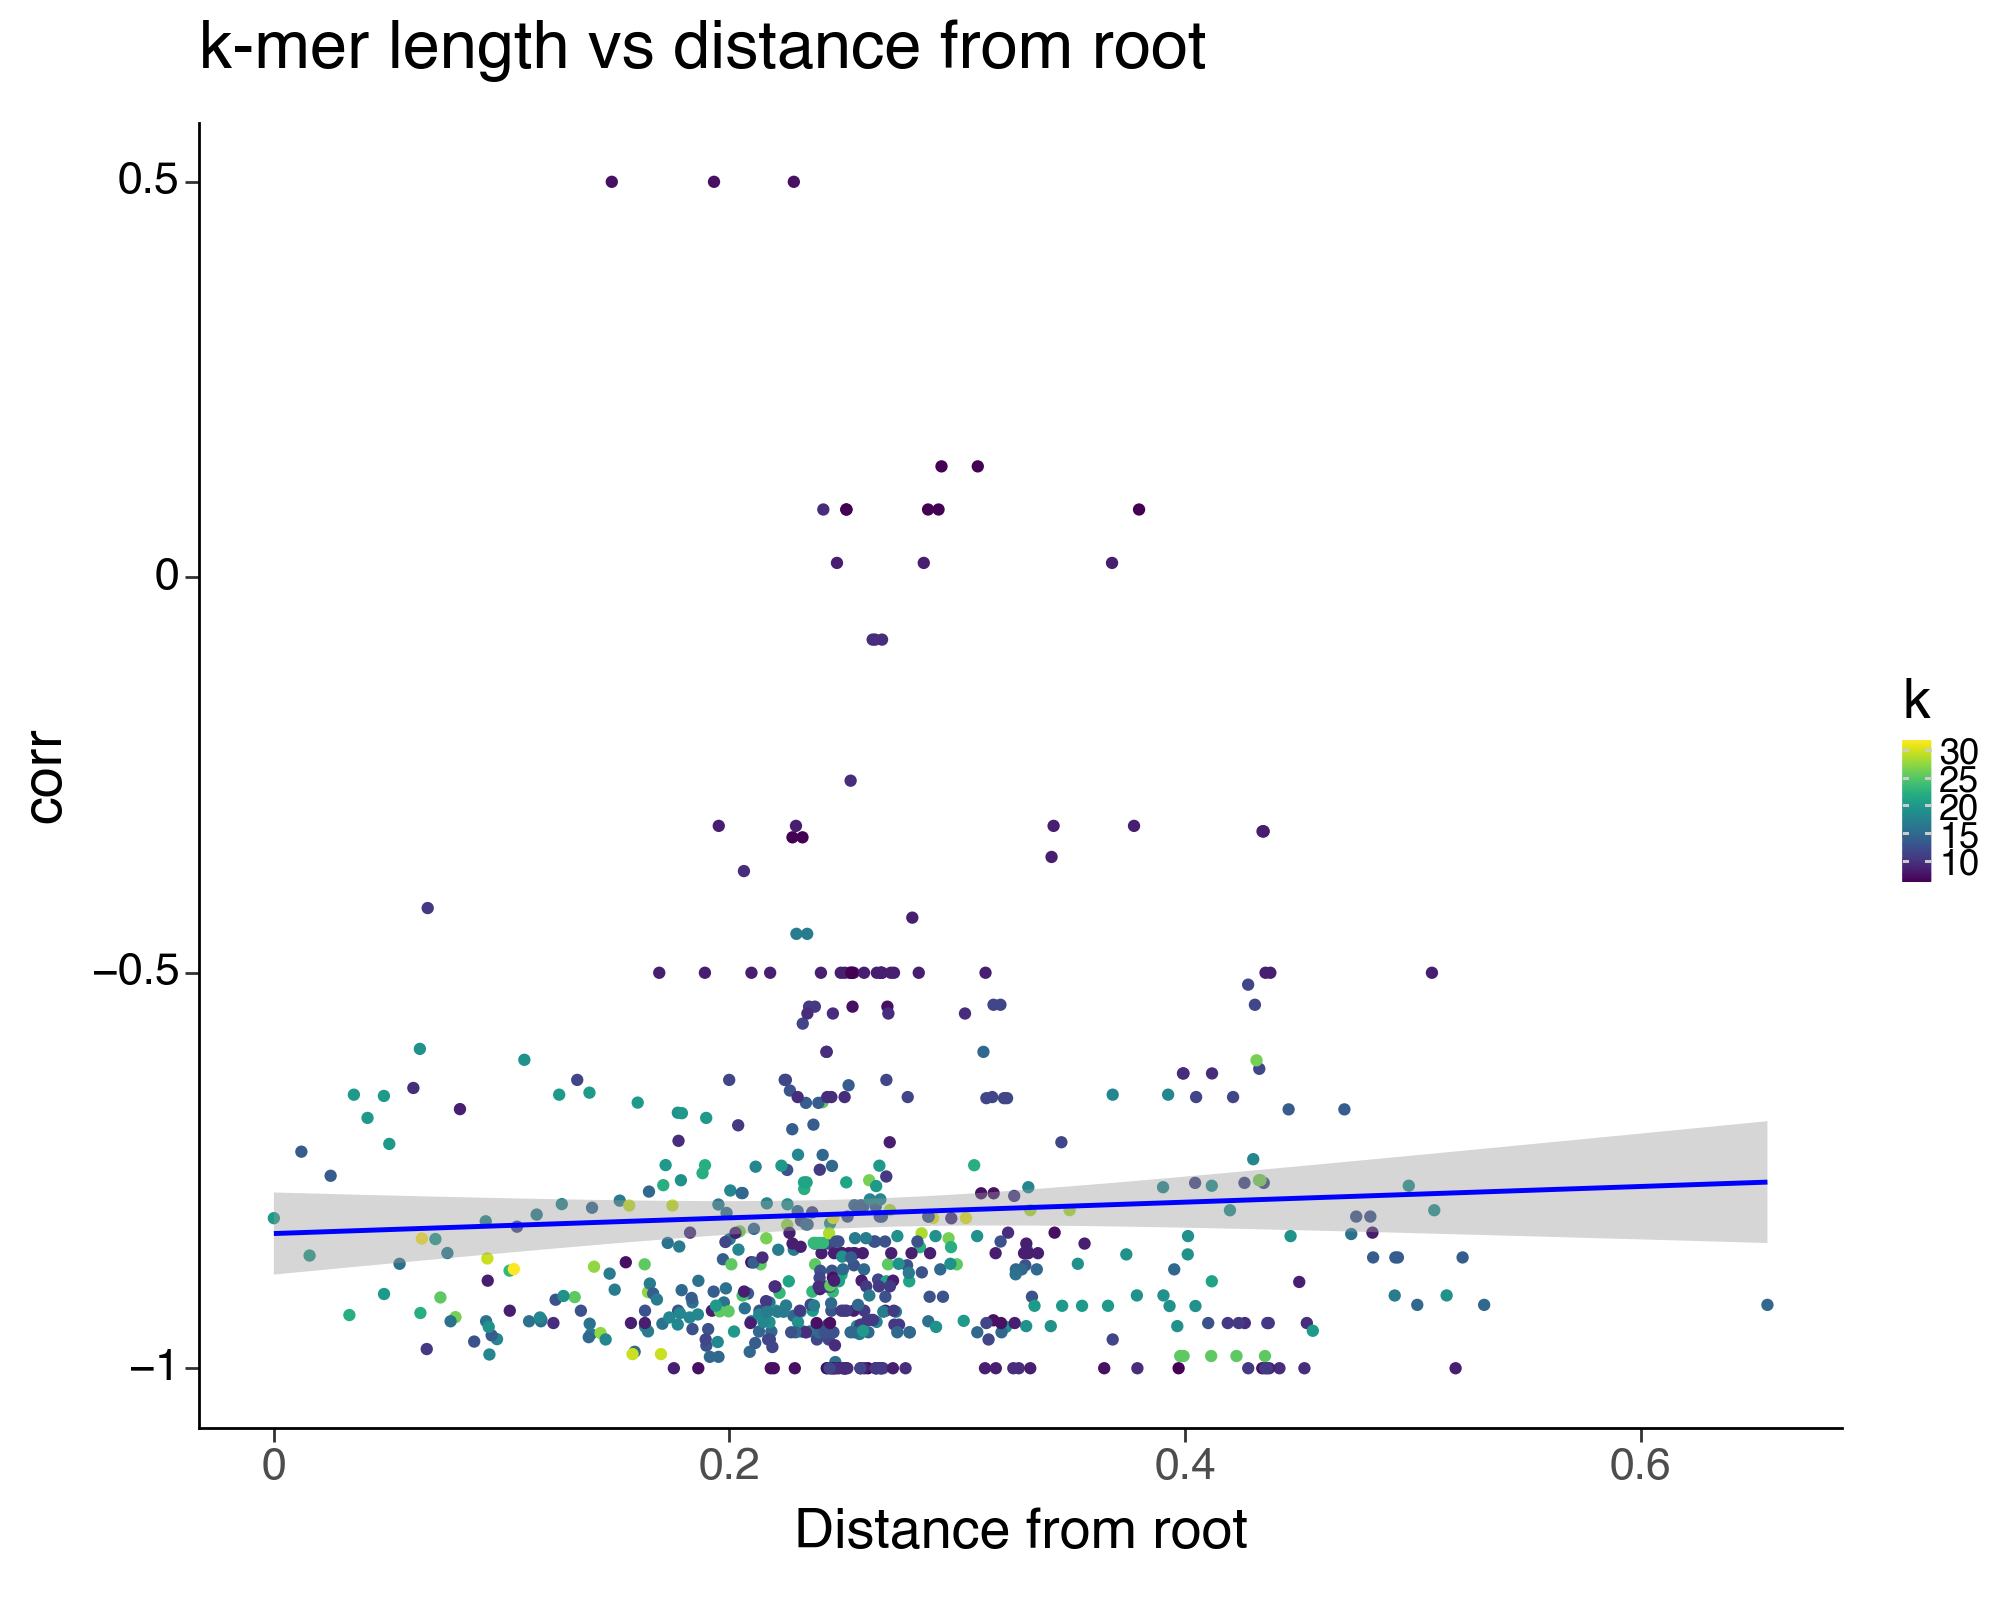

<Figure Size: (1000 x 800)>

In [656]:

(
    ggplot(node_info_df, aes(x='dist_from_root', y='corr', color='k')) +
    # ggplot(node_info_df, aes(x='dist_from_root', y='corr')) +
    geom_point() +
    geom_smooth(method='lm', color='blue') +
    ggtitle("corr vs distance from root") +
    xlab("Distance from root") +
    ylab("corr") +
    theme_tufte_func(base_size=20, rotate=False, figure_size=(10,8)) +
    theme(legend_key_size=7, legend_text=element_text(size=13))
)


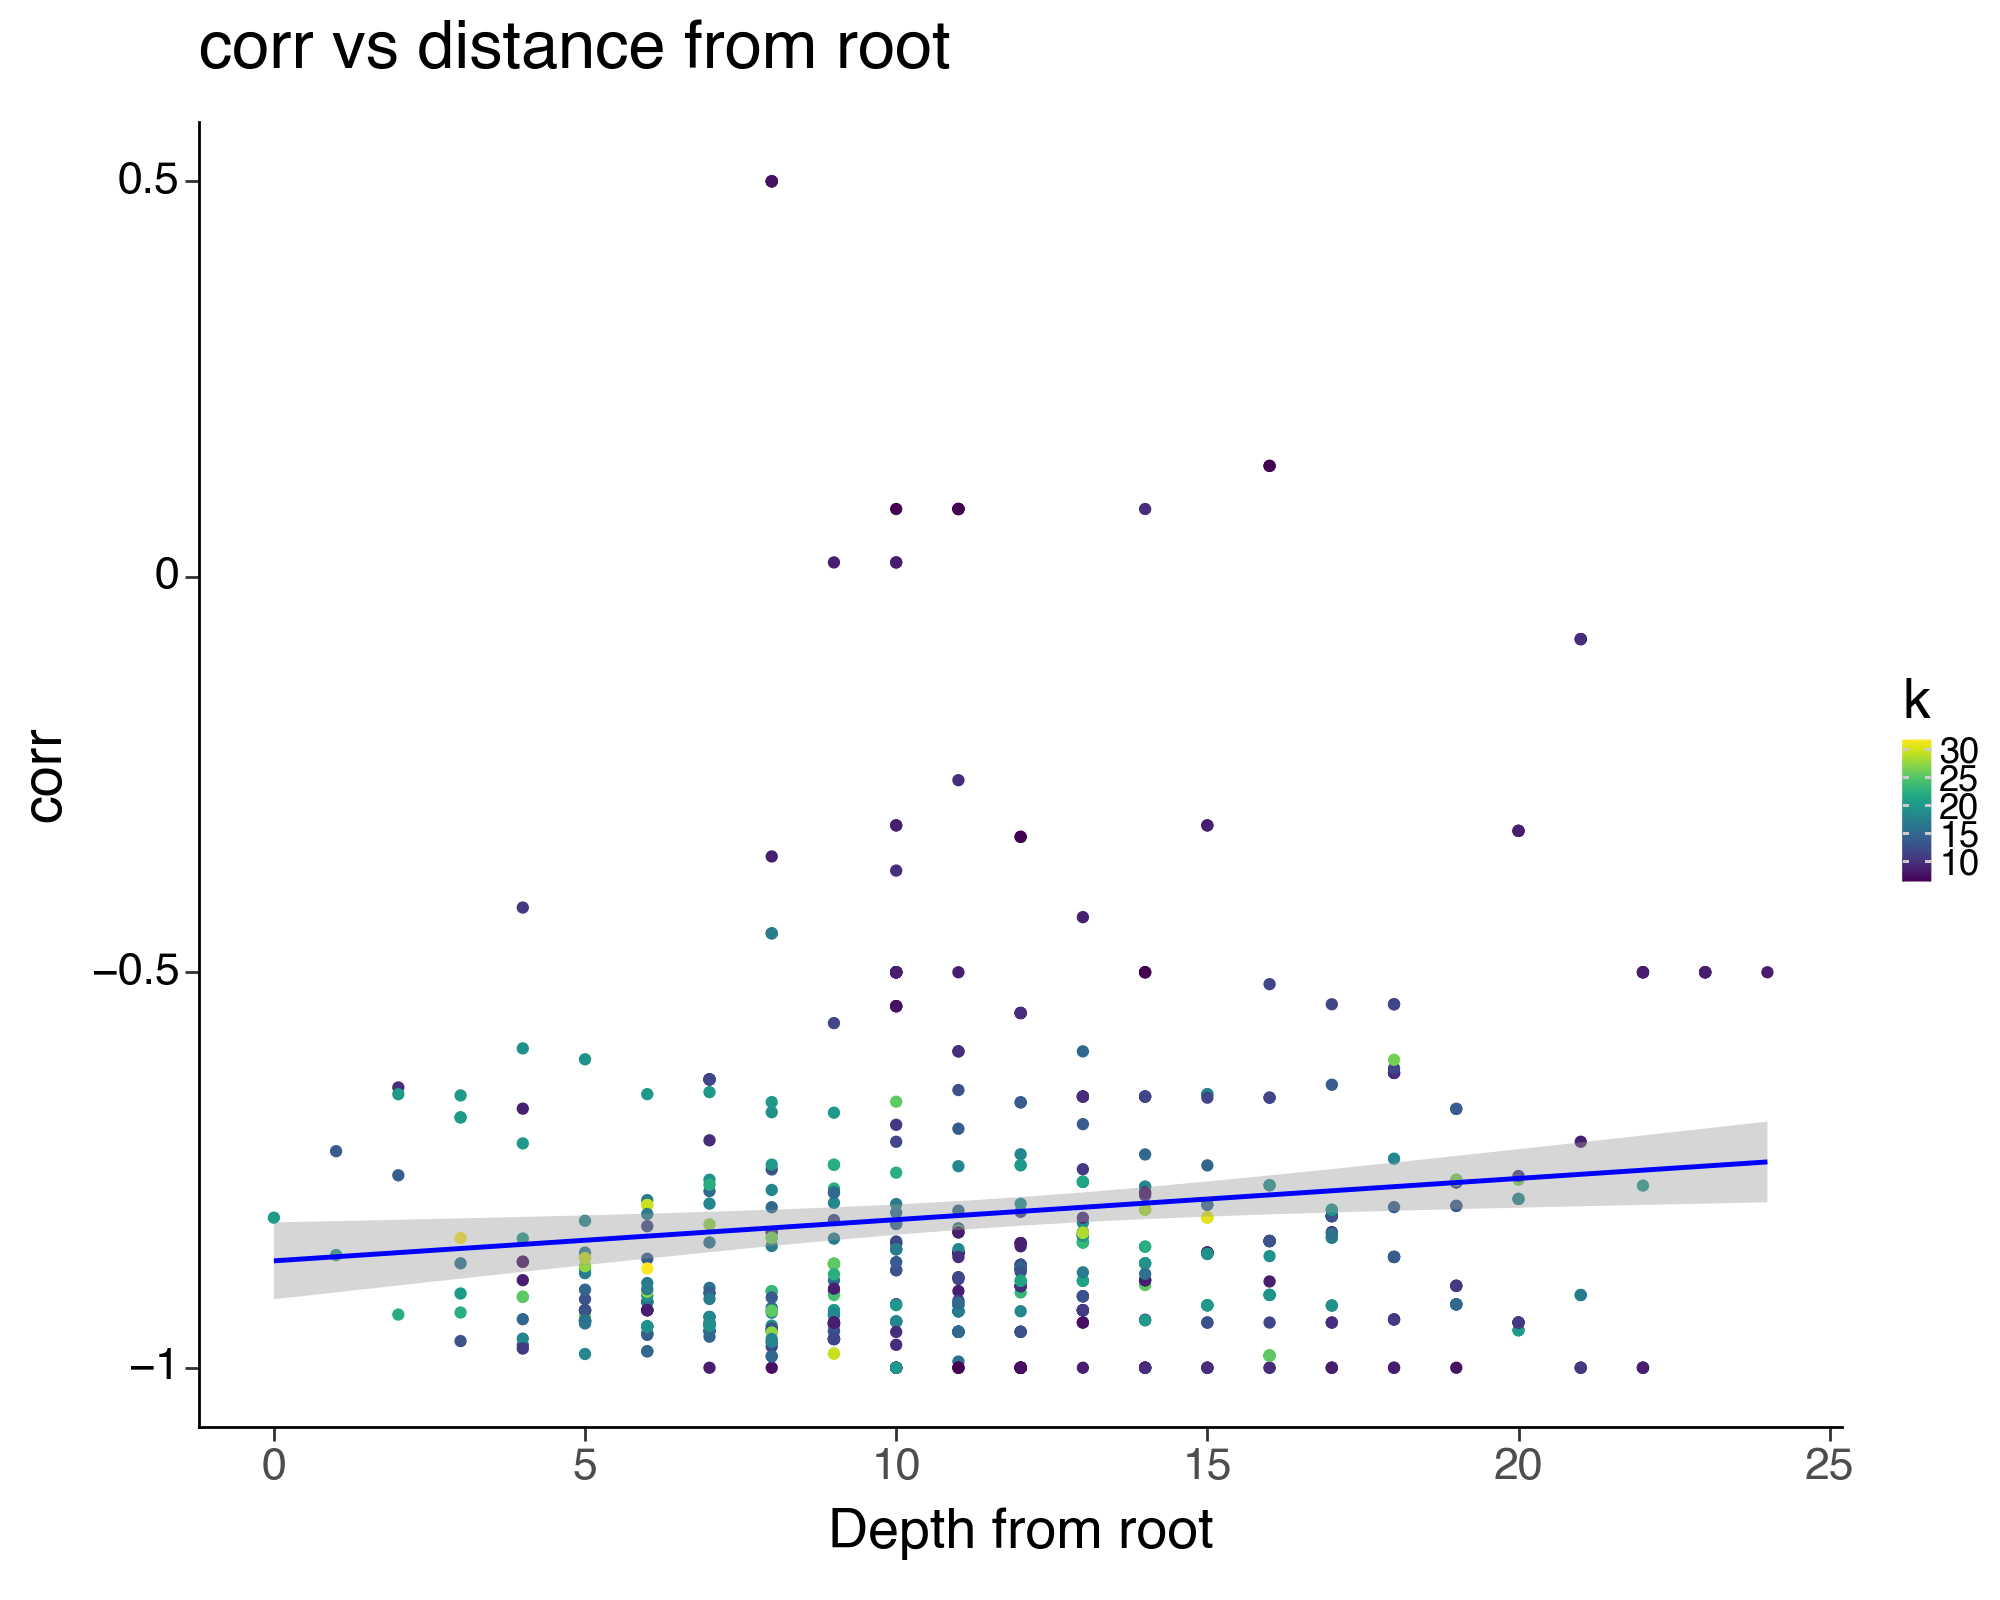

<Figure Size: (1000 x 800)>

In [657]:

(
    ggplot(node_info_df, aes(x='depth_from_root', y='corr', color='k')) +
    geom_point() +
    geom_smooth(method='lm', color='blue') +
    ggtitle("corr vs distance from root") +
    xlab("Depth from root") +
    ylab("corr") +
    theme_tufte_func(base_size=20, rotate=False, figure_size=(10,8)) +
    theme(legend_key_size=7, legend_text=element_text(size=13))
)


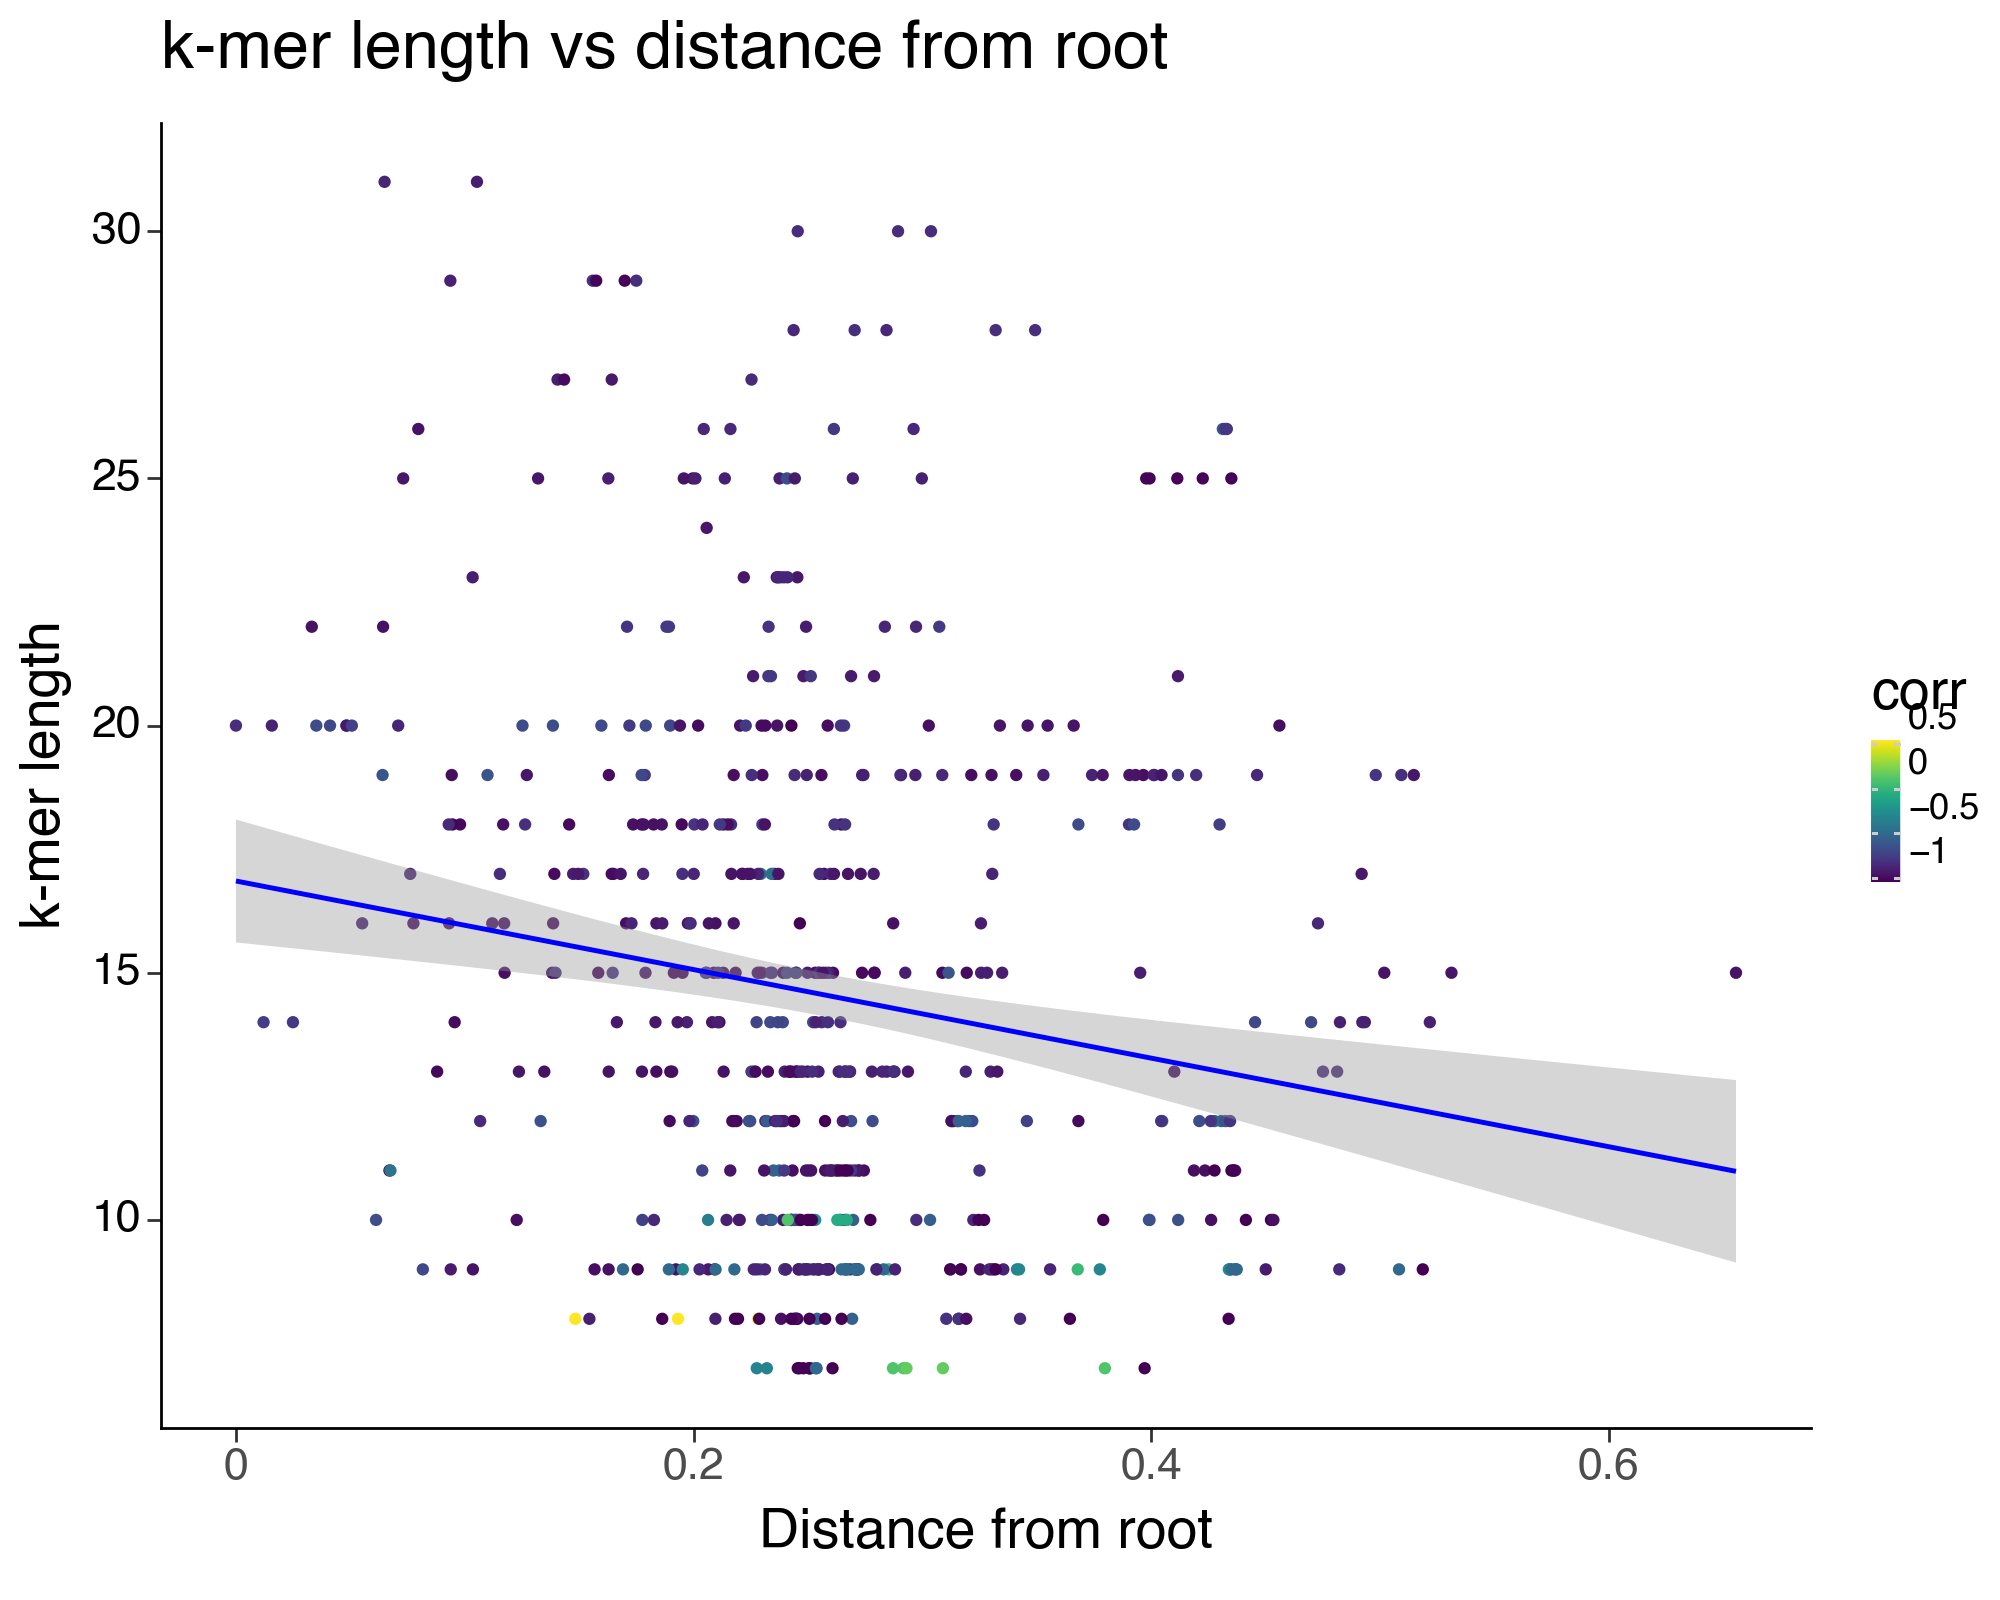

<Figure Size: (1000 x 800)>

In [526]:

(
    ggplot(node_info_df, aes(x='dist_from_root', y='k', color='corr')) +
    geom_point() +
    geom_smooth(method='lm', color='blue') +
    ggtitle("k-mer length vs distance from root") +
    xlab("Distance from root") +
    ylab("k-mer length") +
    theme_tufte_func(base_size=20, rotate=False, figure_size=(10,8)) +
    theme(legend_key_size=7, legend_text=element_text(size=13))
)


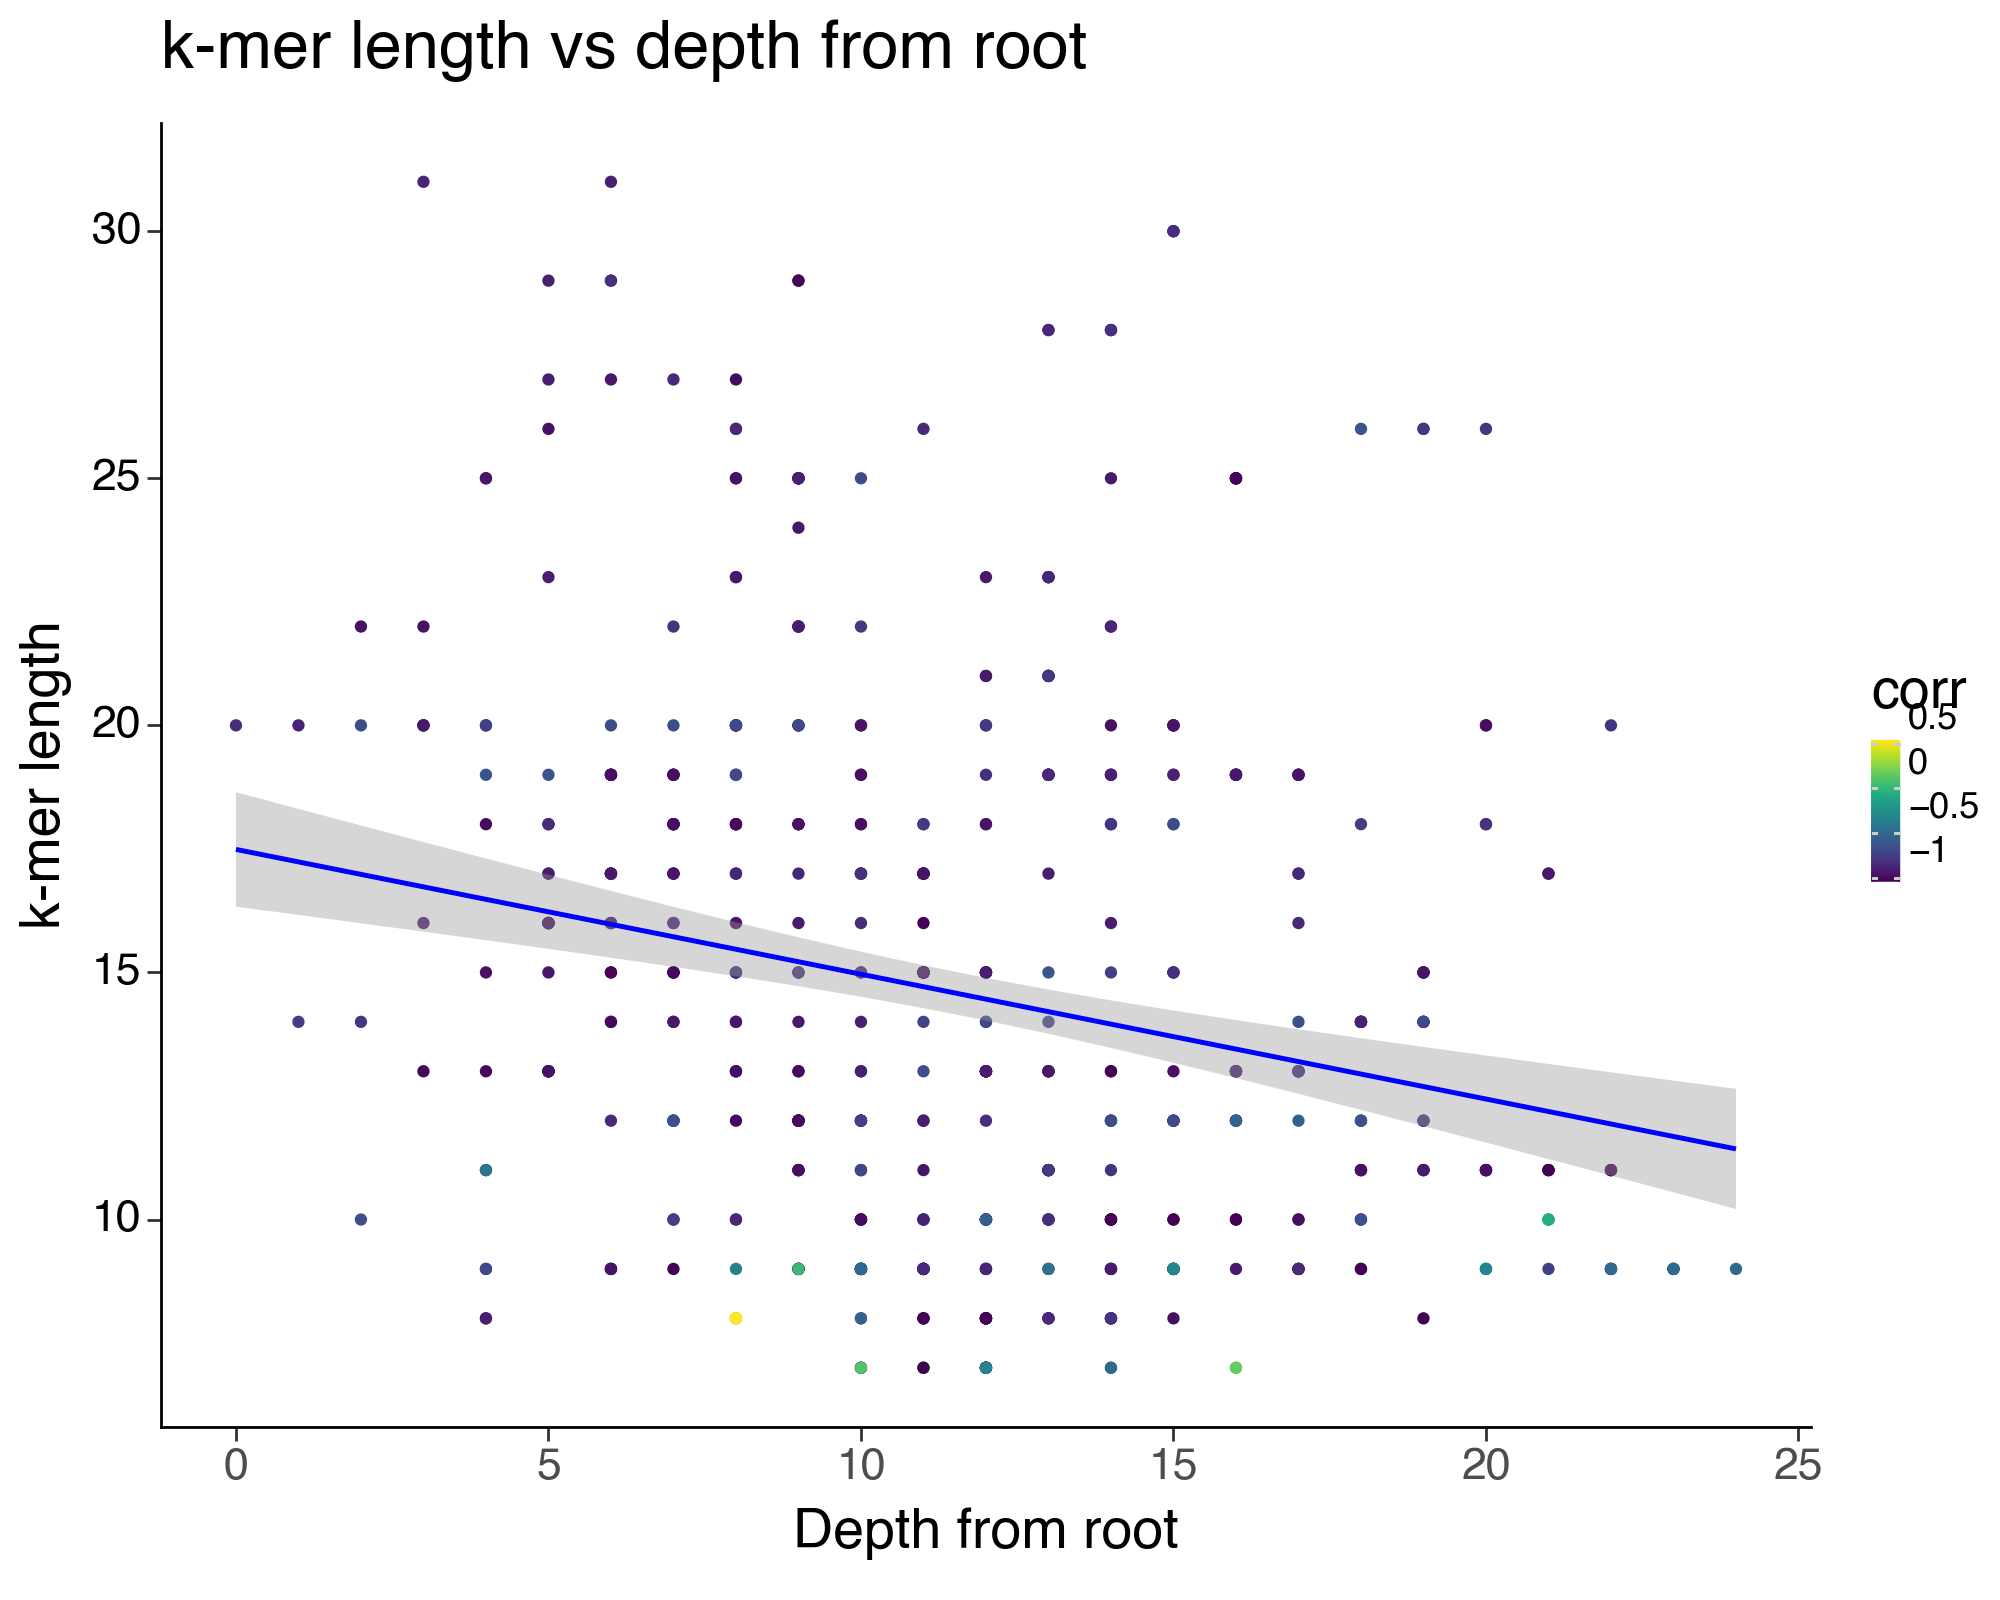

<Figure Size: (1000 x 800)>

In [525]:

(
    ggplot(node_info_df, aes(x='depth_from_root', y='k', color='corr')) +
    geom_point() +
    geom_smooth(method='lm', color='blue') +
    ggtitle("k-mer length vs depth from root") +
    xlab("Depth from root") +
    ylab("k-mer length") +
    theme_tufte_func(base_size=20, rotate=False, figure_size=(10,8)) +
    theme(legend_key_size=7, legend_text=element_text(size=13))
)


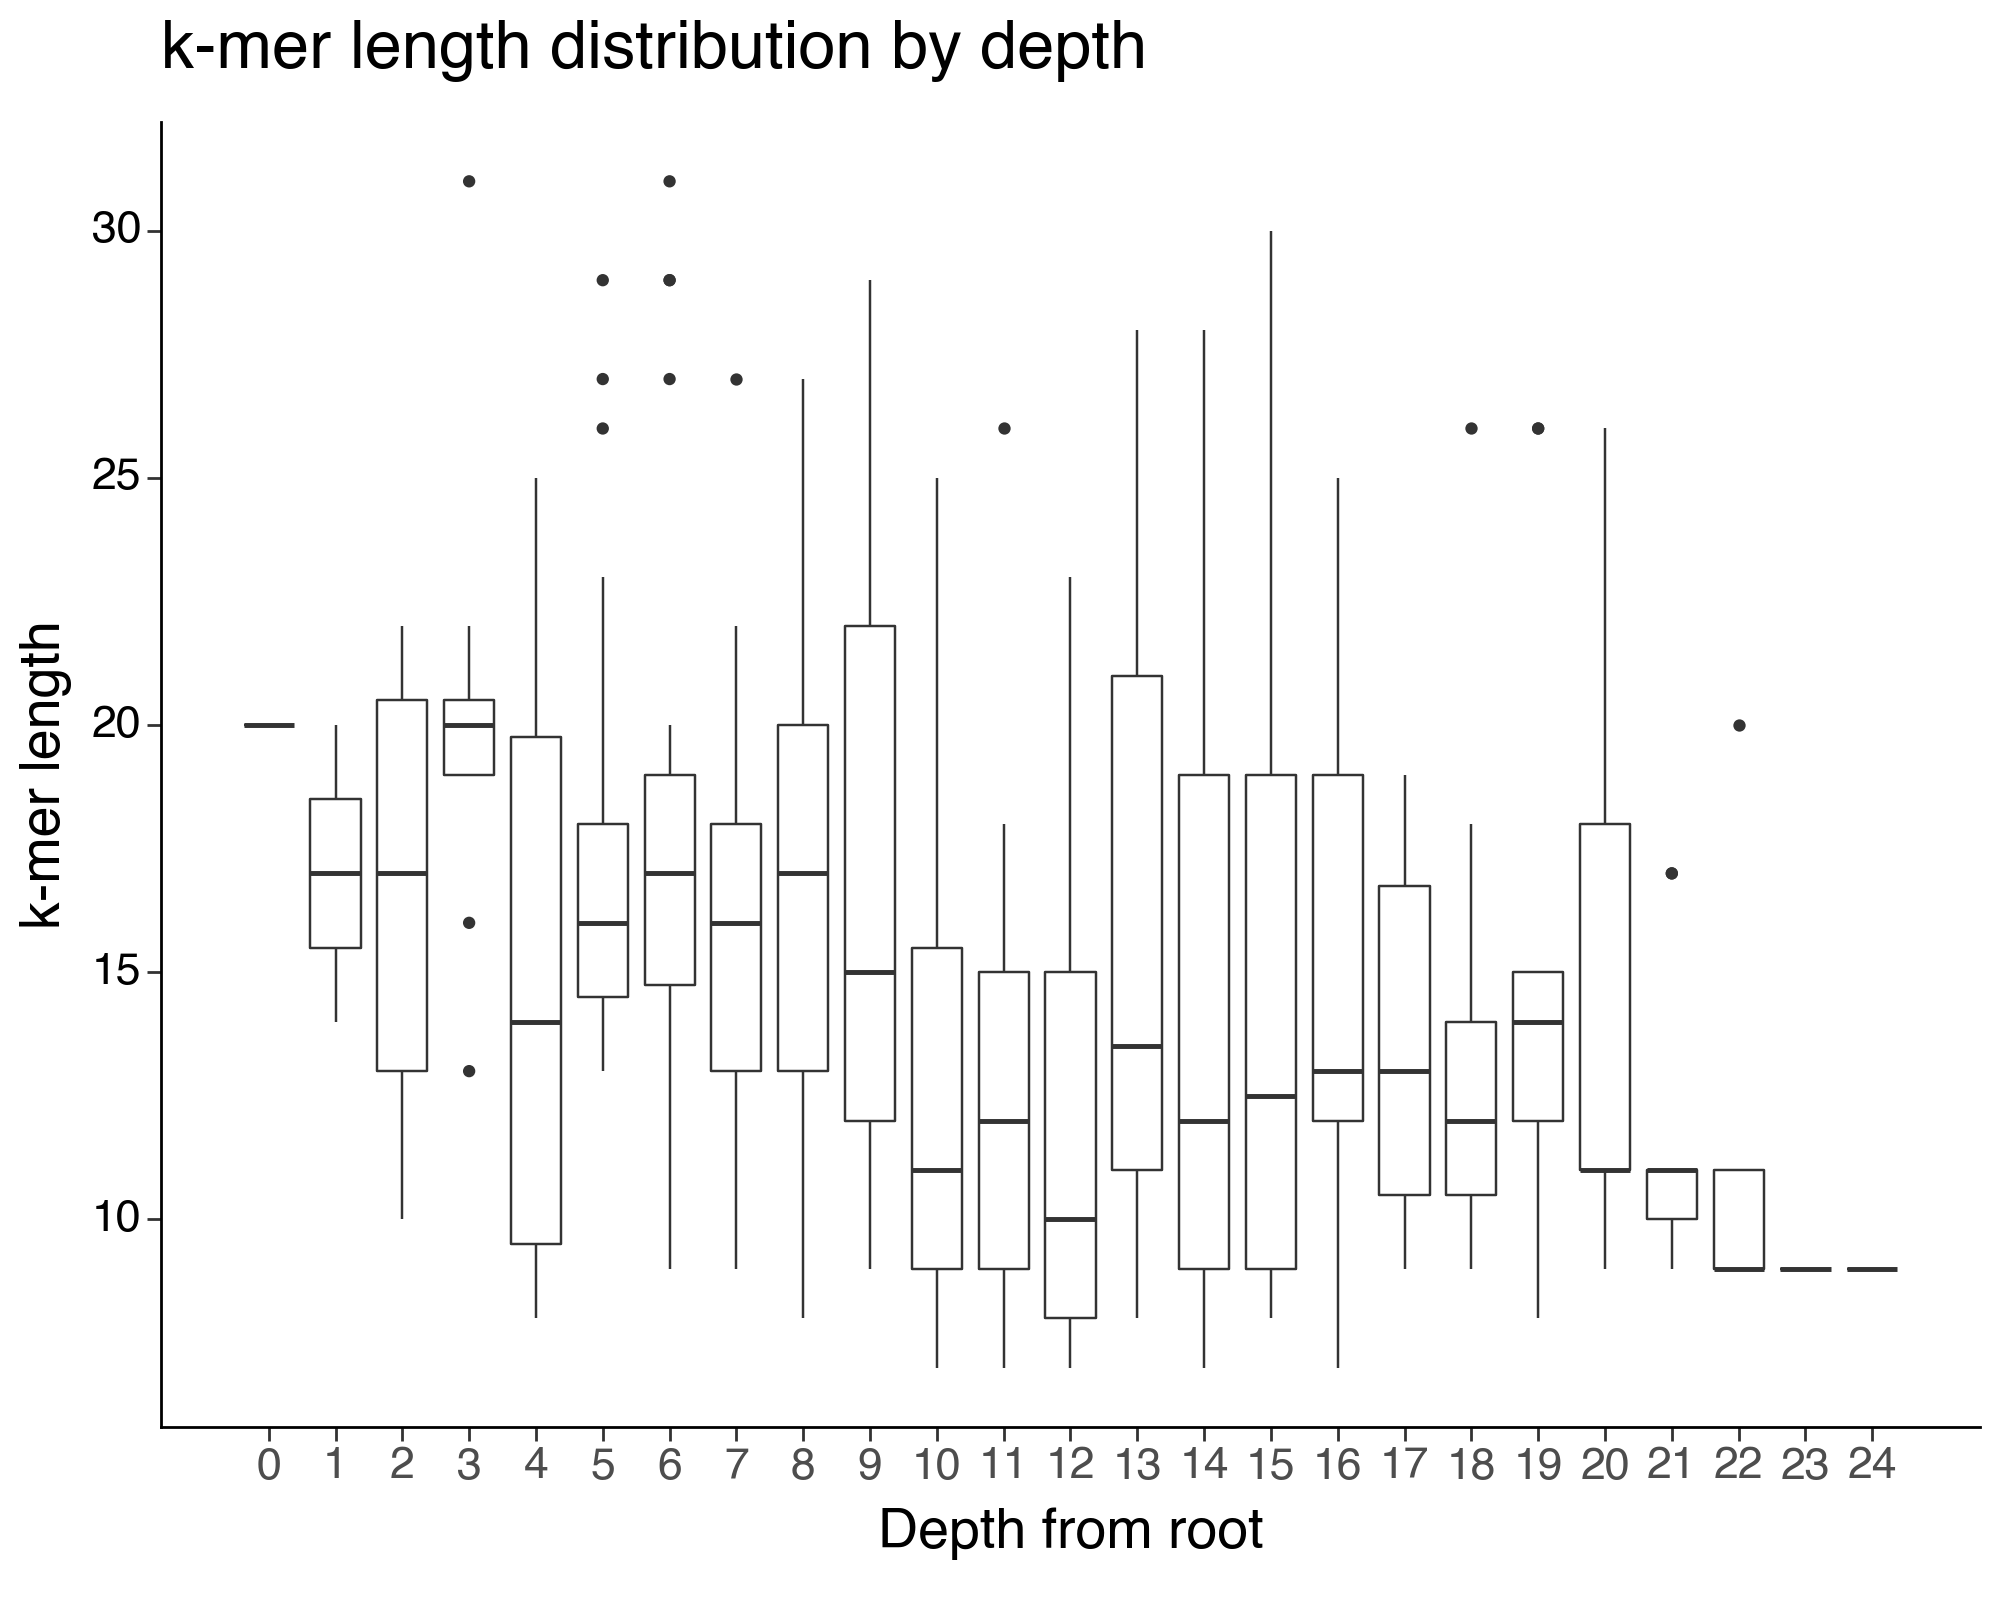

<Figure Size: (1000 x 800)>

In [468]:
(
    ggplot(node_info_df, aes(x='depth_from_root', y='k')) +
    geom_boxplot(aes(group='depth_from_root')) +
    ggtitle("k-mer length distribution by depth") +
    xlab("Depth from root") +
    ylab("k-mer length") +
    scale_x_continuous(breaks=range(int(node_info_df['depth_from_root'].min()),
                                  int(node_info_df['depth_from_root'].max()) + 1)) +
    theme_tufte_func(base_size=20, rotate=False, figure_size=(10,8)) +
    theme(legend_key_size=7, legend_text=element_text(size=13))
)

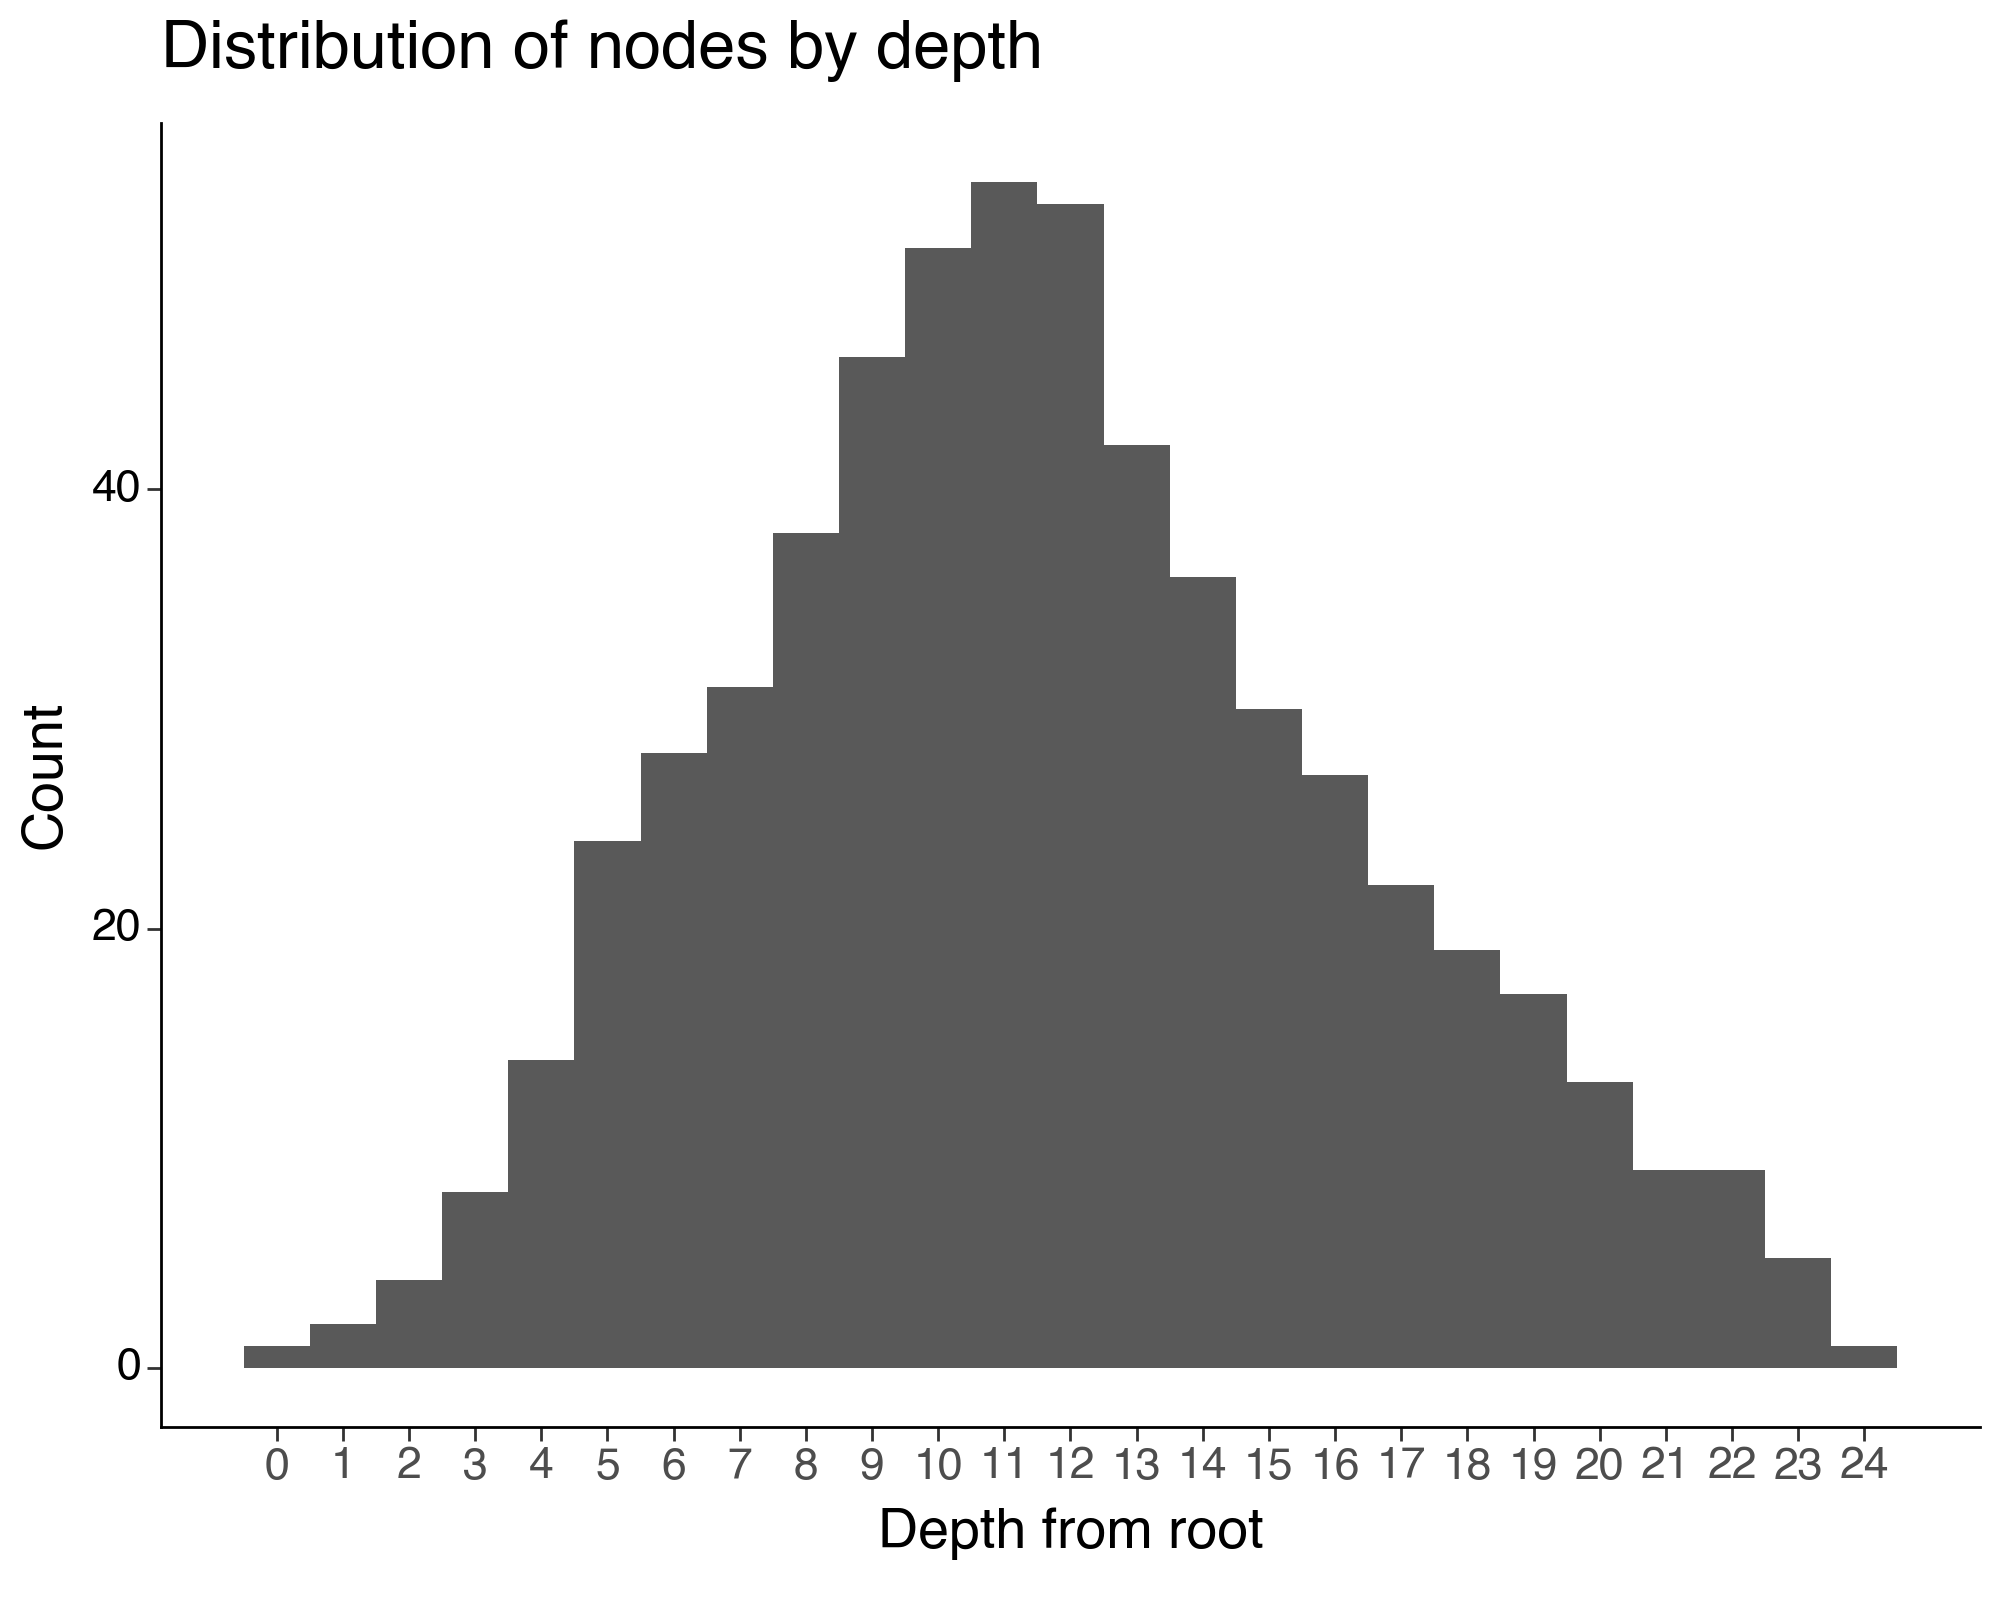

<Figure Size: (1000 x 800)>

In [469]:
(
    ggplot(node_info_df, aes(x='depth_from_root')) +
    geom_histogram(binwidth=1) +
    ggtitle("Distribution of nodes by depth") +
    xlab("Depth from root") +
    ylab("Count") +
    scale_x_continuous(breaks=range(int(node_info_df['depth_from_root'].min()),
                                  int(node_info_df['depth_from_root'].max()) + 1)) +
    theme_tufte_func(base_size=20, rotate=False, figure_size=(10,8)) +
    theme(legend_key_size=7, legend_text=element_text(size=13))
)

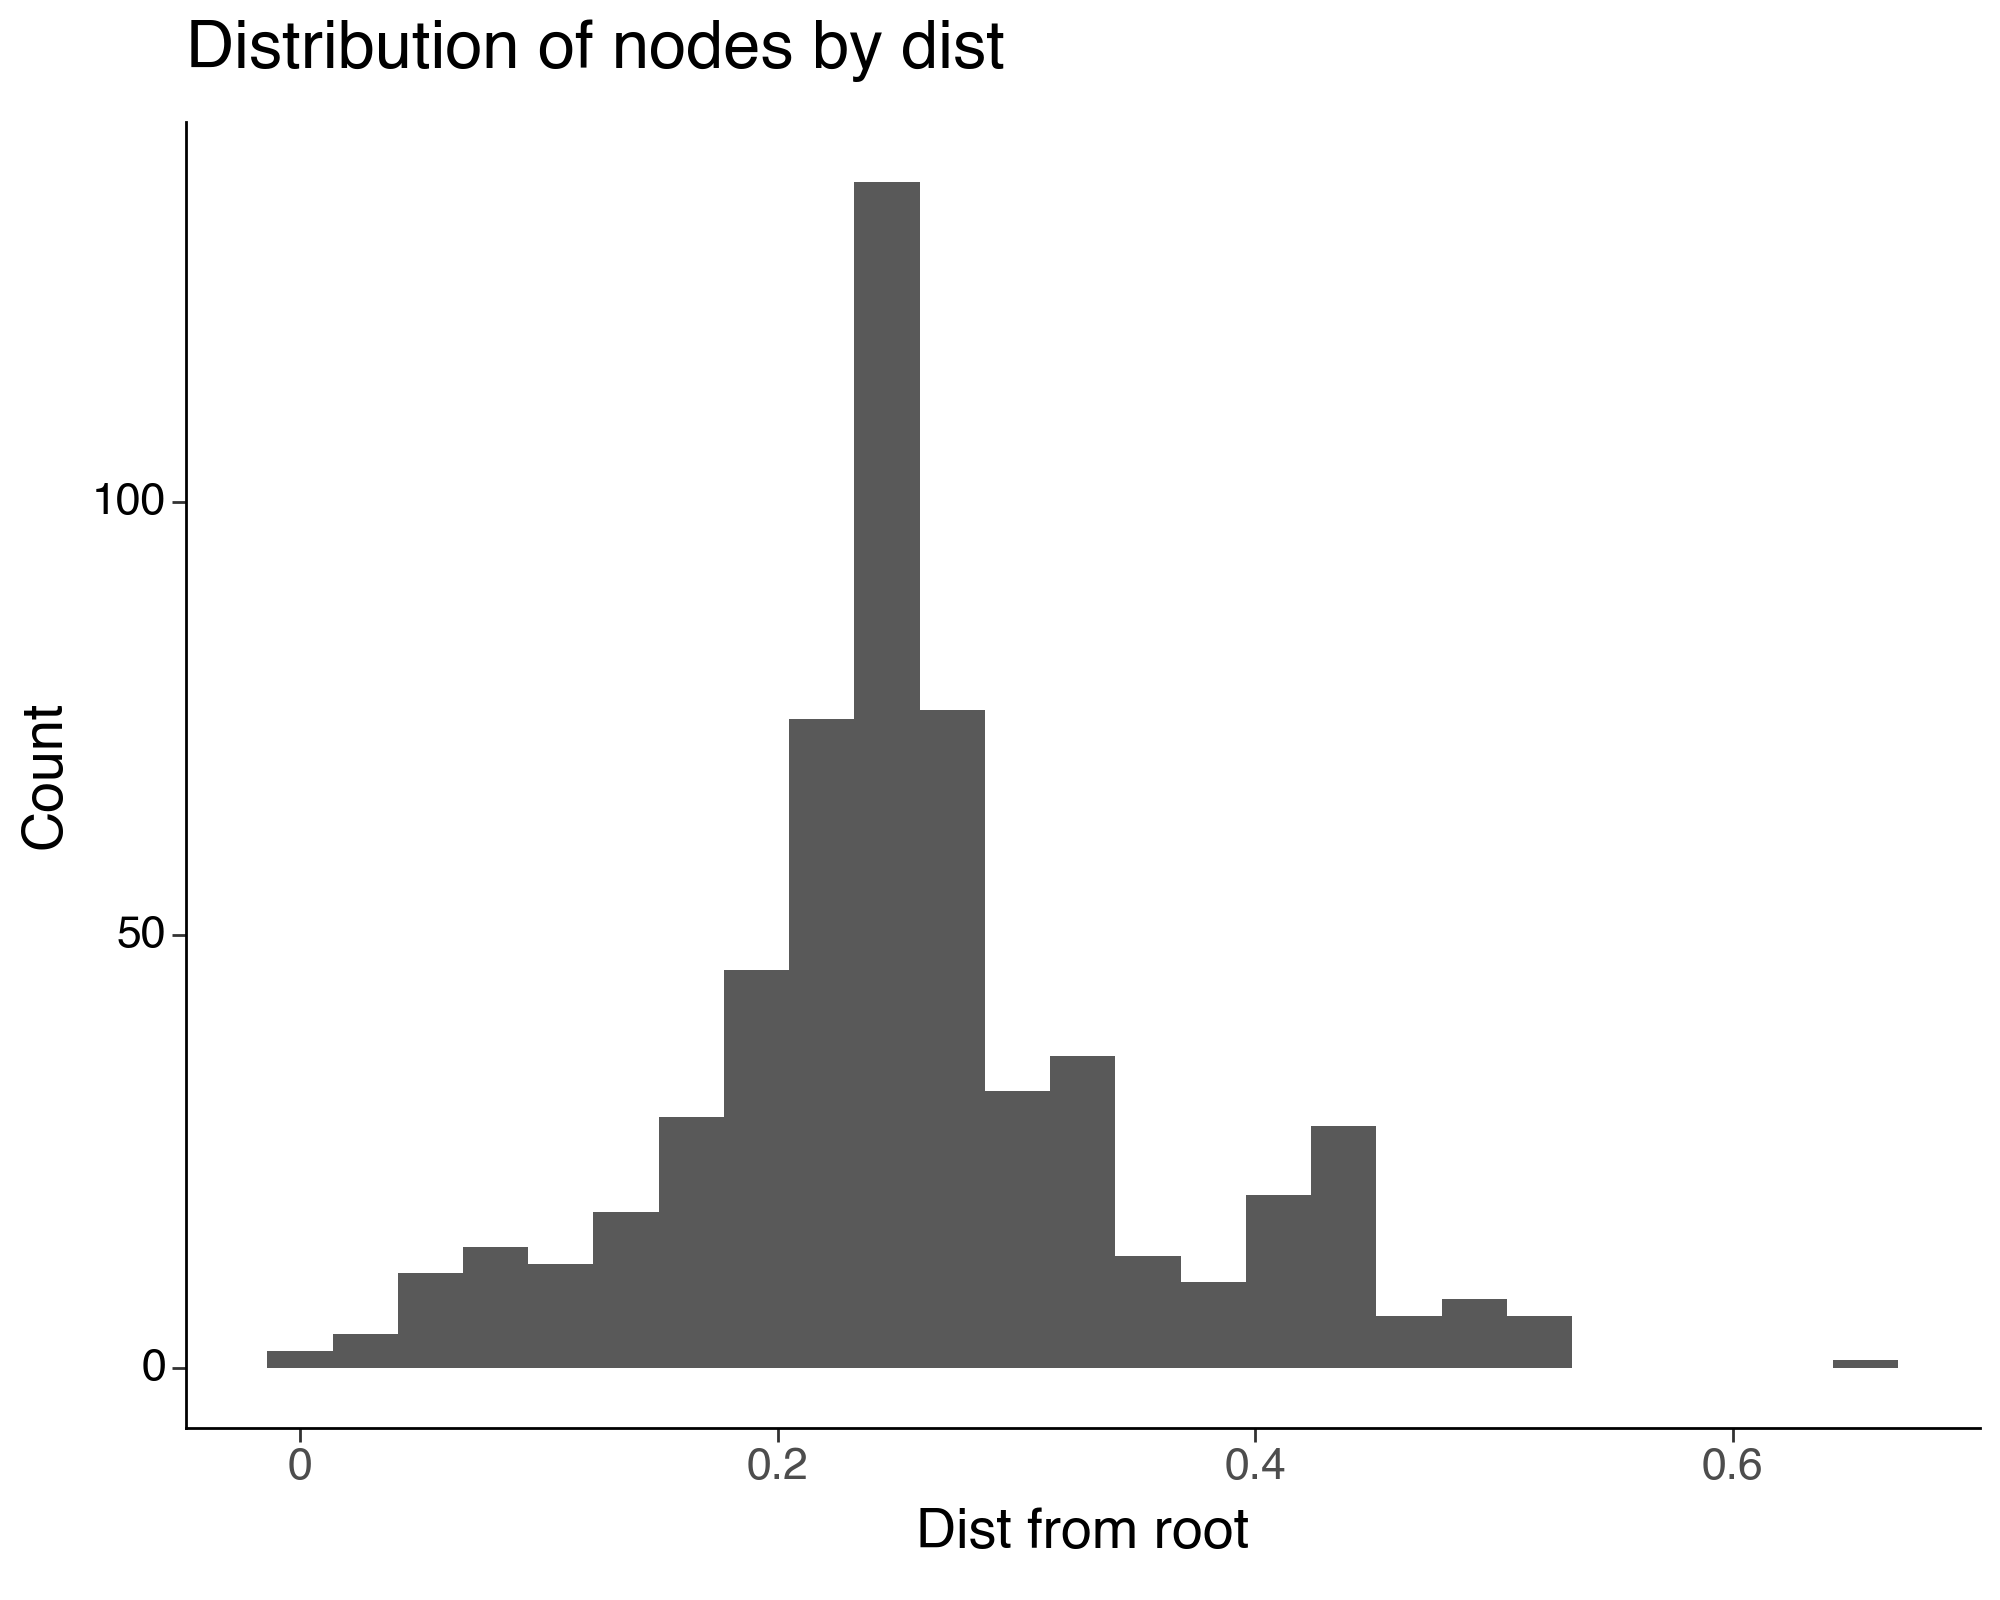

<Figure Size: (1000 x 800)>

In [653]:

(
    ggplot(node_info_df, aes(x='dist_from_root')) +
    geom_histogram(bins=25) +
    ggtitle("Distribution of nodes by dist") +
    xlab("Dist from root") +
    ylab("Count") +
    # scale_x_continuous(breaks=range(int(node_info_df['depth_from_root'].min()),
                                #   int(node_info_df['depth_from_root'].max()) + 1)) +
    theme_tufte_func(base_size=20, rotate=False, figure_size=(10,8)) +
    theme(legend_key_size=7, legend_text=element_text(size=13))
)

# Grouping by path

In [507]:
node_info_path_df = pd.DataFrame(index=node_info_dict.keys(), columns=['path', 'k', 'corr', 'dist_from_root', 'depth_from_root'])

def get_leaf_to_root_paths(tree):
    for leaf in tree.get_leaves():
        path = []
        node = leaf
        while not node.is_root():
            node = node.up  # Get parent node
            path.append(node)
        yield (leaf.name, path)

# Get paths for each leaf
for i, (leaf_name, path) in enumerate(get_leaf_to_root_paths(tree1)):
    for node in path:
        node_info_path_df.loc[f"{node.name}_{i}"] = {
            'path': i,  # Store the path number i
            'k': node_info_df.loc[node.name, 'k'],
            'corr': node_info_df.loc[node.name, 'corr'],
            'dist_from_root': node_info_df.loc[node.name, 'dist_from_root'],
            'depth_from_root': node_info_df.loc[node.name, 'depth_from_root']
        }

node_info_path_df = node_info_path_df[node_info_path_df['path'].notna()] # filter NaNs

node_info_path_df['path'] = node_info_path_df['path'].astype(int)
node_info_path_df['dist_from_root'] = node_info_path_df['dist_from_root'].astype(float)
node_info_path_df['depth_from_root'] = node_info_path_df['depth_from_root'].astype(int)
node_info_path_df['corr'] = node_info_path_df['corr'].astype(float)
node_info_path_df['k'] = node_info_path_df['k'].astype(int)

node_info_path_df

/var/folders/kl/xq32rkjj6t1b1zprtt1lx1sc0000gn/T/ipykernel_38667/270791218.py:24: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.


,path,k,corr,dist_from_root,depth_from_root
internal_node_112_0,0,19,-0.946753,0.255916,8
internal_node_81_0,0,17,-0.953411,0.235339,7
internal_node_53_0,0,17,-0.956727,0.139172,6
internal_node_29_0,0,13,-0.913394,0.123687,5
internal_node_15_0,0,25,-0.910504,0.073106,4
...,...,...,...,...,...
internal_node_28_584,584,11,-0.418182,0.067529,4
internal_node_14_584,584,20,-0.906144,0.048362,3
internal_node_6_584,584,20,-0.654159,0.035125,2
internal_node_2_584,584,20,-0.857503,0.015685,1


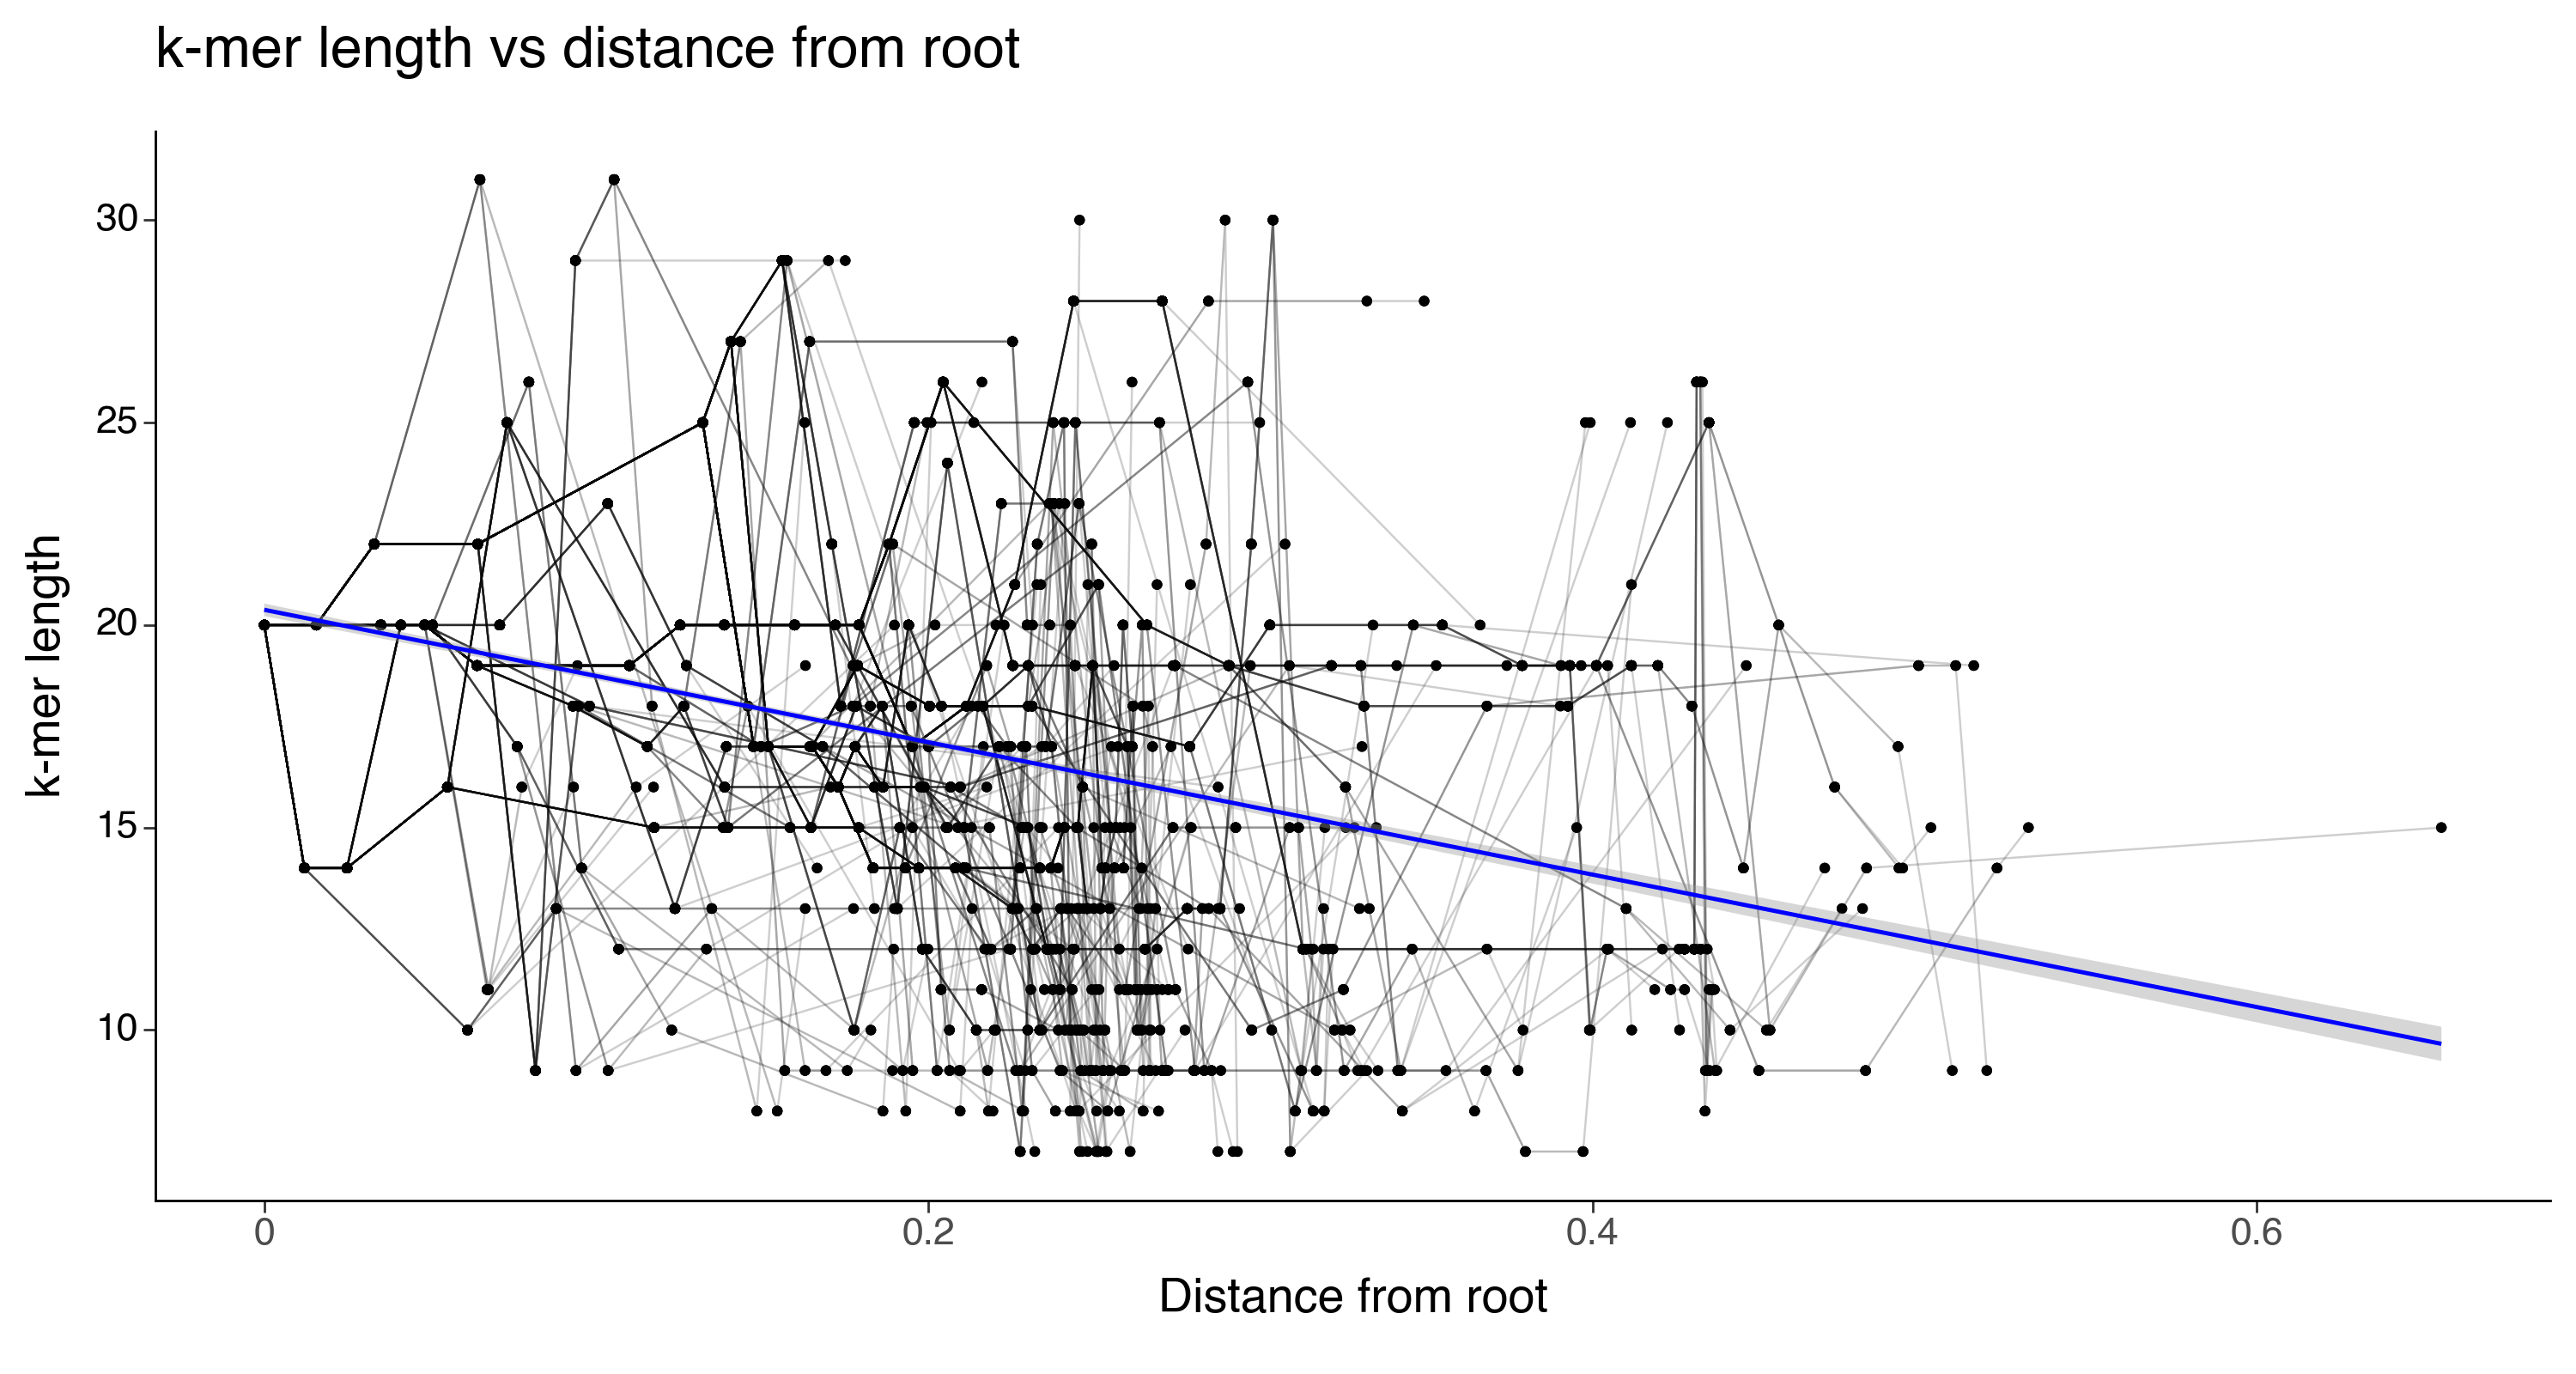

<Figure Size: (1500 x 800)>

In [523]:

(
    # ggplot(node_info_path_df, aes(x='dist_from_root', y='k', color='corr', group='path')) +
    ggplot(node_info_path_df, aes(x='dist_from_root', y='k')) +
    geom_point() +
    geom_line(aes(group='path'), alpha=0.1) +
    geom_smooth(method='lm', color='blue') +
    ggtitle("k-mer length vs distance from root") +
    xlab("Distance from root") +
    ylab("k-mer length") +
    theme_tufte_func(base_size=20, rotate=False, figure_size=(15,8)) +
    theme(legend_key_size=7, legend_text=element_text(size=13))
)


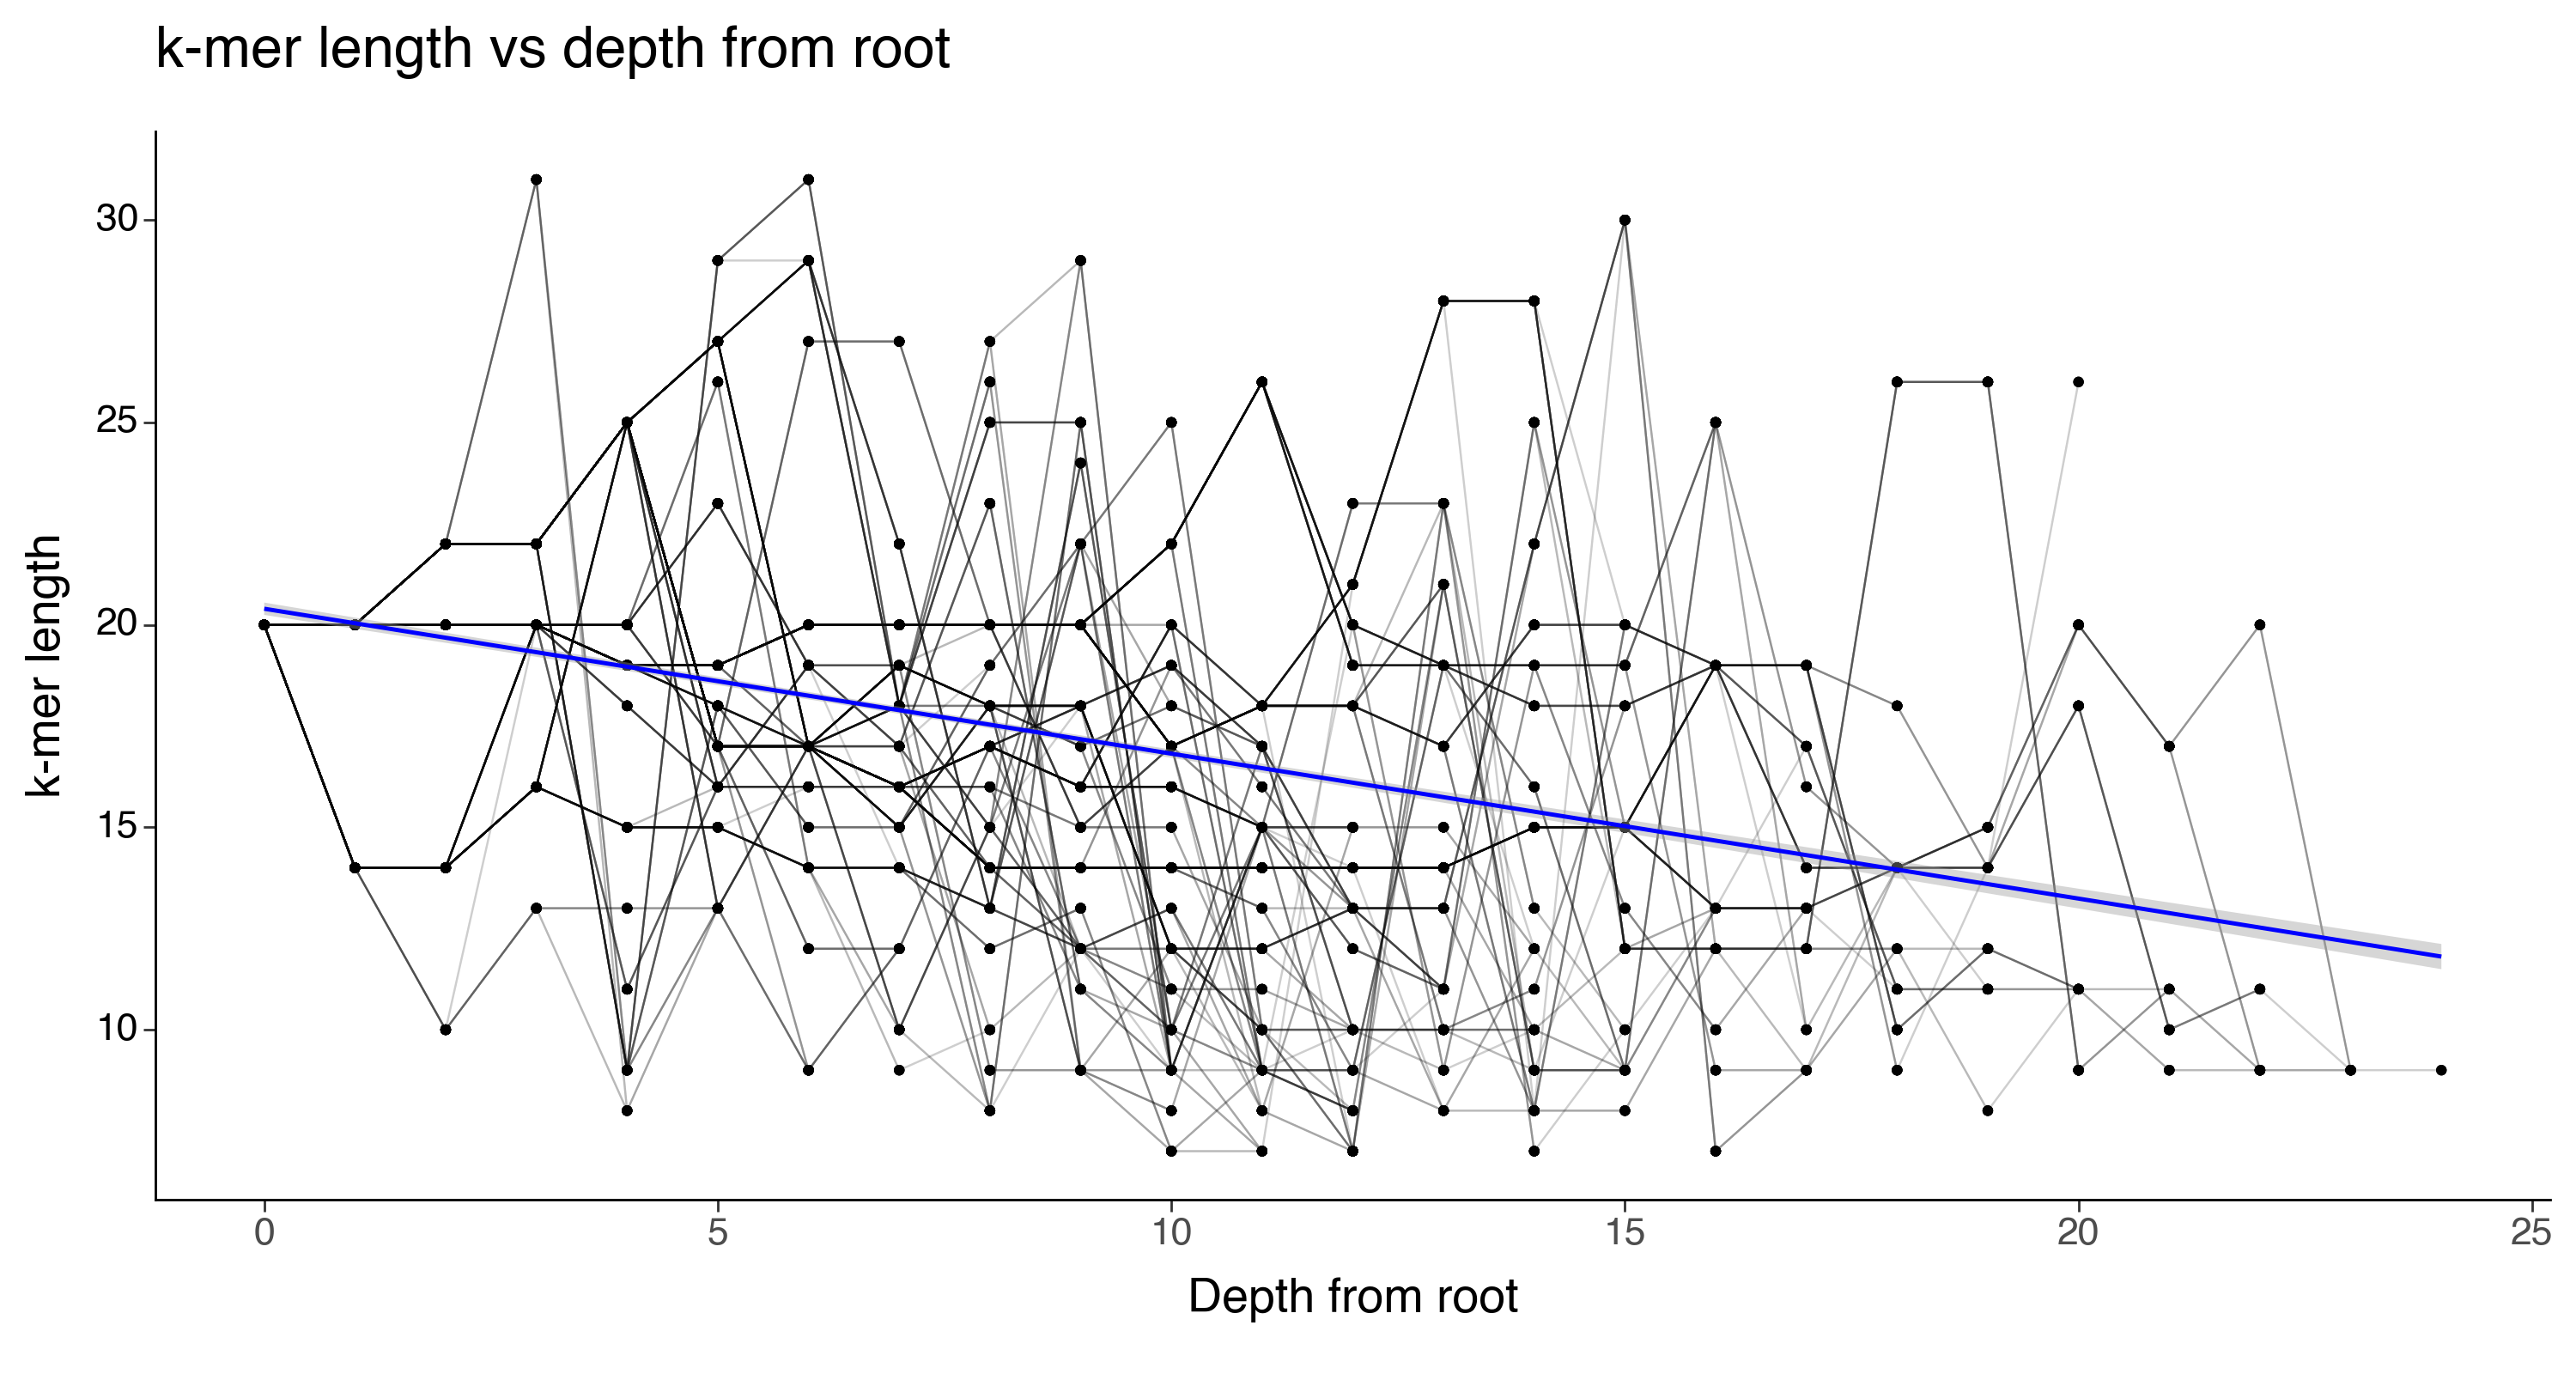

<Figure Size: (1500 x 800)>

In [ ]:

(
    # ggplot(node_info_path_df, aes(x='dist_from_root', y='k', color='corr', group='path')) +
    ggplot(node_info_path_df, aes(x='depth_from_root', y='k')) +
    geom_point() +
    geom_line(aes(group='path'), alpha=0.1) +
    geom_smooth(method='lm', color='blue') +
    ggtitle("k-mer length vs depth from root") +
    xlab("Depth from root") +
    ylab("k-mer length") +
    theme_tufte_func(base_size=20, rotate=False, figure_size=(15,8)) +
    theme(legend_key_size=7, legend_text=element_text(size=13))
)


# Heatmap of avgerage correlation by k-mer length across internal node distances to root

In [631]:
# dict(list(zip(node_info_df.index, node_info_df['dist_from_root'])))
node_to_dist_dict = dict(zip(node_info_df.index, node_info_df['dist_from_root']))
node_to_depth_dict = dict(zip(node_info_df.index, node_info_df['depth_from_root']))

for node_id, depth in node_to_depth_dict.items():
    node_info_dict[node_id]['depth'] = depth
    node_info_dict[node_id]['dist'] = node_to_dist_dict[node_id]


In [637]:
# Create empty lists to store data
nodes = []
ks = list(range(5,33))
corrs = []
depths = []
dists = []

# Extract data from node_info_dict
for node_id, node_data in node_info_dict.items():
    nodes.append(node_id)
    node_corrs = []
    for k in ks:
        if k in node_data and 'corr' in node_data[k]:
            node_corrs.append(node_data[k]['corr'][0])
        else:
            node_corrs.append(None)
    corrs.append(node_corrs)
    depths.append(node_data['depth'])
    dists.append(node_data['dist'])

# Create DataFrame
df = pd.DataFrame(corrs, columns=[k for k in ks], index=nodes)
df['depth'] = depths
df['dist'] = dists

# Calculate distance deciles
l = []
for x in list(set(list(pd.qcut(df['dist'], q=10)))):
    x1, x2 = x.left, x.right
    if x1 < 0:
        x1 = 0
    l.append(  f"{x1} - {x2}" )
df['dist_decile'] = pd.qcut(df['dist'], q=10, labels=sorted(l))

# Melt the dataframe to long format for k values
df_melted = df.melt(id_vars=['dist_decile'],
                    value_vars=[k for k in range(5,33)],
                    var_name='k',
                    value_name='correlation')

df_heatmap = df_melted.groupby(['dist_decile', 'k'])['correlation'].mean().reset_index()

# adjust bounds, clip the opposite direction correlations
df_heatmap['correlation'] = -1 * df_heatmap['correlation']
df_heatmap.loc[df_heatmap['correlation'] < 0, 'correlation'] = np.nan

/var/folders/kl/xq32rkjj6t1b1zprtt1lx1sc0000gn/T/ipykernel_38667/3019250339.py:41: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.


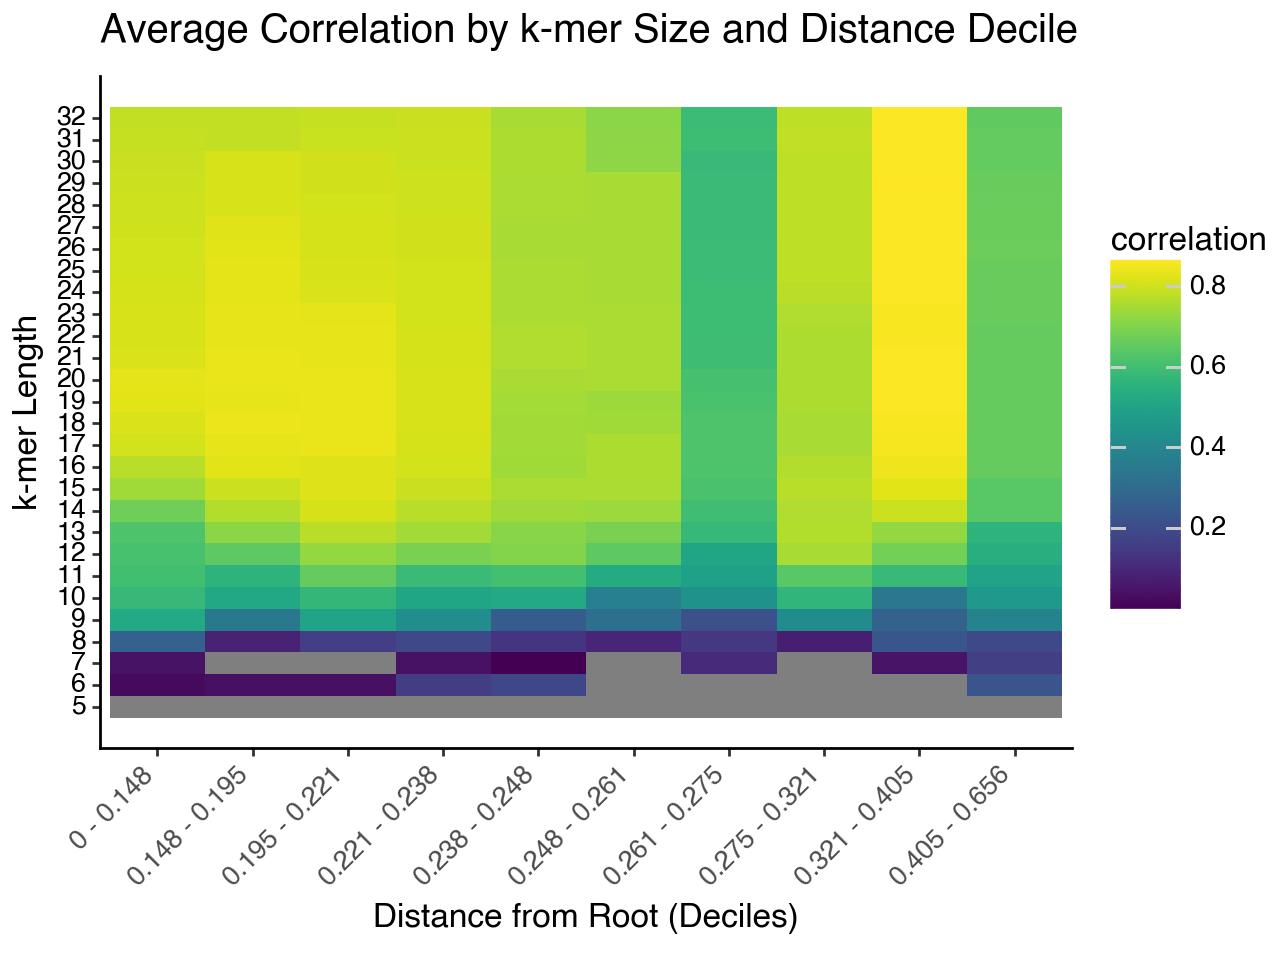

<Figure Size: (640 x 480)>

In [638]:

# Create the heatmap
(ggplot(df_heatmap, aes(x='dist_decile', y='k', fill='correlation')) +
    geom_tile() +
    scale_y_continuous(breaks=range(5,33)) +
    ggtitle("Average Correlation by k-mer Size and Distance Decile") +
    xlab("Distance from Root (Deciles)") +
    ylab("k-mer Length") +
    theme_tufte_func(base_size=12) +
    theme(
        legend_position='right',
        axis_text_x=element_text(angle=45, hjust=1)
    )
)

/var/folders/kl/xq32rkjj6t1b1zprtt1lx1sc0000gn/T/ipykernel_38667/3785058779.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.


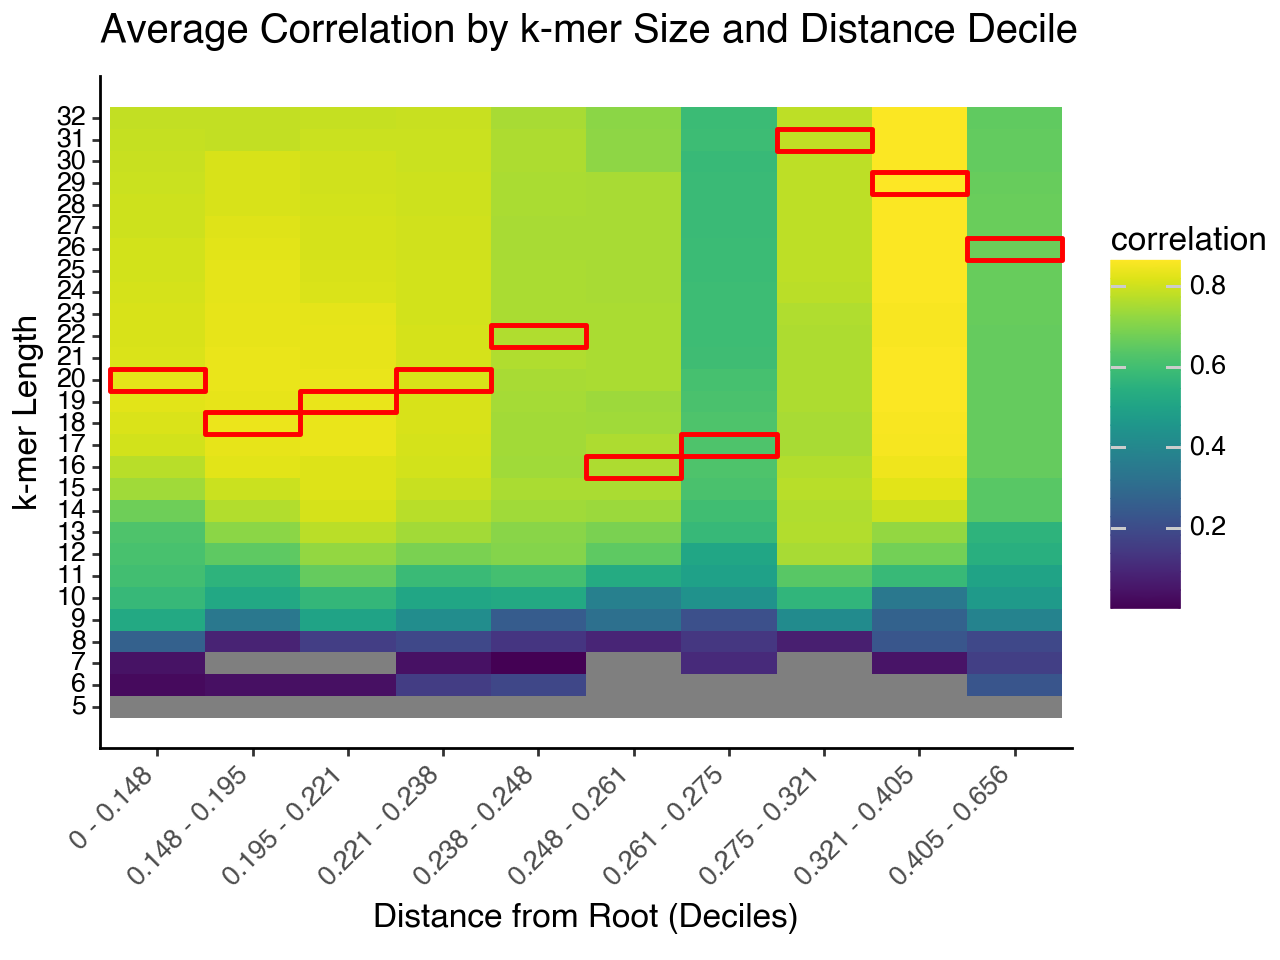

<Figure Size: (640 x 480)>

In [650]:
# Find best correlation per distance decile
best_corr = df_heatmap.groupby('dist_decile')['correlation'].transform('max') == df_heatmap['correlation']

# Create the heatmap
(ggplot(df_heatmap, aes(x='dist_decile', y='k', fill='correlation')) +
    geom_tile() +
    # Add red outline for best correlations
    geom_tile(data=df_heatmap[best_corr],
              mapping=aes(x='dist_decile', y='k'),
              color='red', fill=None, size=1) +
    scale_y_continuous(breaks=range(5,33)) +
    ggtitle("Average Correlation by k-mer Size and Distance Decile") +
    xlab("Distance from Root (Deciles)") +
    ylab("k-mer Length") +
    theme_tufte_func(base_size=12) +
    theme(
        legend_position='right',
        axis_text_x=element_text(angle=45, hjust=1)
    )
)

In [644]:
# df_heatmap
sum(list(df_melted.groupby('dist_decile').size())) / len(list(df_melted.groupby('dist_decile').size()))

/var/folders/kl/xq32rkjj6t1b1zprtt1lx1sc0000gn/T/ipykernel_38667/233485410.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
/var/folders/kl/xq32rkjj6t1b1zprtt1lx1sc0000gn/T/ipykernel_38667/233485410.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.


1635.2

In [649]:
x = df_melted[ df_melted['k'] == 30 ]

# sum(list(df_melted.groupby('dist_decile').size())) / len(list(df_melted.groupby('dist_decile').size()))
sum(list(x.groupby('dist_decile').size())) / len(list(x.groupby('dist_decile').size()))
# list(x.groupby('dist_decile').size())

/var/folders/kl/xq32rkjj6t1b1zprtt1lx1sc0000gn/T/ipykernel_38667/3010330949.py:4: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
/var/folders/kl/xq32rkjj6t1b1zprtt1lx1sc0000gn/T/ipykernel_38667/3010330949.py:4: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.


58.4

# Scratch

In [223]:

for node_name, ks in node_to_k.items():
    w = [100]
    if ks is None:                      # no k values
        color = ['#808081']             # gray '#FFFFFF'
    elif type(ks) == tuple:             # multiple k values
        color1 = k_color[ks[0]]
        color2 = k_color[ks[1]]
        w = [(1 - ks[2])*100, ks[2] * 100]
        color = [color1, color2]       # Red: '#FF0000'
    else:                               # single int k
        color = [k_color[ks]]
    node_to_color[node_name] = (color, w)

node_to_color


{5: '#440154',
 6: '#470e61',
 7: '#481b6d',
 8: '#482878',
 9: '#46337f',
 10: '#423f85',
 11: '#3e4989',
 12: '#3a548c',
 13: '#355e8d',
 14: '#31688e',
 15: '#2d718e',
 16: '#297a8e',
 17: '#26828e',
 18: '#228c8d',
 19: '#1f948c',
 20: '#1f9e89',
 21: '#21a685',
 22: '#29af7f',
 23: '#35b779',
 24: '#46c06f',
 25: '#58c765',
 26: '#6ece58',
 27: '#84d44b',
 28: '#9dd93b',
 29: '#b5de2b',
 30: '#d0e11c',
 31: '#e7e419',
 32: '#fde725'}

In [22]:



node_to_k = {}

for node_name, (node, II) in internal_node_to_II.items():
    local_minima, weight_corr = group_best_corr(II, tree_dict, merged_df)
    print(node_name, local_minima, weight_corr)
    corr, ks = find_best_correlation(node_name, local_minima, weight_corr)
    node_to_k[node_name] = ks


/opt/homebrew/Caskroom/miniconda/base/envs/python/lib/python3.11/site-packages/scipy/stats/_stats_py.py:5445: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.


internal_node_0 [(11, -0.6527521261525094), (20, -0.7925296727478356)] (0.75, -0.8102808267515857)
internal_node_0: -0.8102808267515857; k11, k20, w0.75
internal_node_1 [(14, -0.7262039019097166)] (None, None)
internal_node_1: -0.7262039019097166; k14
internal_node_2 [(12, -0.6720719852736217), (20, -0.8568033720514212)] (0.85, -0.7966639686557521)
internal_node_2: -0.8568033720514212; k20
internal_node_3 [(14, -0.7566666042357508)] (None, None)
internal_node_3: -0.7566666042357508; k14
internal_node_4 [(10, -0.5824675324675326), (14, -0.5822510822510822)] (0.45, -0.6681405378632065)
internal_node_4: -0.6681405378632065; k10, k14, w0.45
internal_node_5 [(10, -0.49607157162058113), (22, -0.9327648423238595)] (0.7, -0.8116976050138671)
internal_node_5: -0.9327648423238595; k22
internal_node_6 [(12, -0.4937870942102737), (20, -0.6400524111705903)] (0.85, -0.7966639686557521)
internal_node_6: -0.7966639686557521; k12, k20, w0.85
internal_node_7 [(16, -0.8679402952178701)] (None, None)
inte

In [51]:
# mapping k to color

node_to_color = {}

for node_name, ks in node_to_k.items():
    w = [100]
    if ks is None:                      # no k values
        color = ['#808081']             # gray '#FFFFFF'
    elif type(ks) == tuple:             # multiple k values
        color1 = k_color[ks[0]]
        color2 = k_color[ks[1]]
        w = [(1 - ks[2])*100, ks[2] * 100]
        color = [color1, color2]       # Red: '#FF0000'
    else:                               # single int k
        color = [k_color[ks]]
    node_to_color[node_name] = (color, w)

node_to_color


{'internal_node_0': (['#3e4989', '#1f9e89'], [25.0, 75.0]),
 'internal_node_1': (['#31688e'], [100]),
 'internal_node_2': (['#1f9e89'], [100]),
 'internal_node_3': (['#31688e'], [100]),
 'internal_node_4': (['#423f85', '#31688e'], [55.00000000000001, 45.0]),
 'internal_node_5': (['#29af7f'], [100]),
 'internal_node_6': (['#3a548c', '#1f9e89'], [15.000000000000002, 85.0]),
 'internal_node_7': (['#297a8e'], [100]),
 'internal_node_8': (['#31688e', '#1f9e89'], [0.0, 100.0]),
 'internal_node_9': (['#808081'], [100]),
 'internal_node_10': (['#355e8d'], [100]),
 'internal_node_11': (['#e7e419'], [100]),
 'internal_node_12': (['#29af7f'], [100]),
 'internal_node_13': (['#3a548c', '#1f9e89'], [15.000000000000002, 85.0]),
 'internal_node_14': (['#1f9e89'], [100]),
 'internal_node_15': (['#58c765'], [100]),
 'internal_node_16': (['#2d718e'], [100]),
 'internal_node_17': (['#1f9e89'], [100]),
 'internal_node_18': (['#46337f', '#1f9e89'], [19.999999999999996, 80.0]),
 'internal_node_19': (['#355e8

# Plot tree, with node colors as best correlation k

In [ ]:

# mapping k to color

node_to_color = {}

for node_name, ks in node_to_k.items():
    w = [100]
    if ks is None:                      # no k values
        color = ['#808081']             # gray '#FFFFFF'
    elif type(ks) == tuple:             # multiple k values
        color1 = k_color[ks[0]]
        color2 = k_color[ks[1]]
        w = [(1 - ks[2])*100, ks[2] * 100]
        color = [color1, color2]       # Red: '#FF0000'
    else:                               # single int k
        color = [k_color[ks]]
    node_to_color[node_name] = (color, w)

node_to_color


In [87]:
# Create custom tree style
ts = TreeStyle()
ts.show_leaf_name = True  # Show leaf names
ts.mode = "r"  # r for rectangular layout; c for circular layout
ts.scale = 2000  # Scale branch lengths
ts.branch_vertical_margin = 10  # Spacing between branches
ts.show_scale = True  # Show scale bar


################################################################################
# Create colorbar
fig, ax = plt.subplots(figsize=(12, 2))
colors = [k_color[k] for k in sorted(k_color.keys())]
bounds = np.arange(len(colors)+1)
cmap = plt.cm.colors.ListedColormap(colors)
norm = plt.cm.colors.BoundaryNorm(bounds, cmap.N)
cb = plt.colorbar(plt.cm.ScalarMappable(norm=norm, cmap=cmap),
                 ax=ax,
                 orientation='horizontal',
                 ticks=bounds[:-1])
cb.set_label('k value')
cb.set_ticklabels(sorted(k_color.keys()))
ax.set_visible(False)

# Convert colorbar to image and add as face
plt.savefig('colorbar.png', bbox_inches='tight', pad_inches=0)
plt.close()
colorbar = faces.ImgFace('colorbar.png')
colorbar.margin_top = 100
colorbar.margin_bottom = 100
ts.legend.add_face(colorbar, column=0)  # Removed aligned=True parameter
ts.legend_position = 4  # 4 means bottom
################################################################################

def layout(node):
    # Create custom node style for each node
    nstyle = NodeStyle()
    nstyle["vt_line_width"] = 2  # Branch line width
    nstyle["hz_line_width"] = 2  # Branch line width

    if node.is_leaf() or node_to_color[node.name][0][0] == '#808081':  # do not plot dot if node is leaf or internal node with None correlation, i.e. too few leaves
    # if node.is_leaf():  # do not plot dot if node is leaf or internal node with None correlation, i.e. too few leaves
        pass
    else:  # Color internal nodes with piechart
        c, w = node_to_color[node.name]
        F = faces.PieChartFace(w,
                              colors=c,
                              width=50, height=50)
        F.border.width = None
        faces.add_face_to_node(F, node, 0, position="branch-right")

    node.set_style(nstyle)

# Set the layout function
ts.layout_fn = layout

# Render tree with custom style
tree1.render("tree1_weight_k_pie.png", tree_style=ts, w=1500)

{'nodes': [[31.725921166098438,
   3007.6259079015676,
   34.11474137286739,
   3010.0147281083364,
   0,
   None],
  [78.98837063399112,
   1061.7159815253444,
   81.37719084076006,
   1064.1048017321134,
   1,
   None],
  [127.18174333646165,
   707.7760506721042,
   129.5705635432306,
   710.1648708788732,
   2,
   None],
  [196.16645159056645,
   328.27148618761066,
   198.55527179733542,
   330.66030639437963,
   3,
   None],
  [250.42957755641623,
   181.89209563660015,
   252.8183977631852,
   184.2809158433691,
   4,
   None],
  [343.68983507473814,
   140.0259219639644,
   346.0786552815071,
   142.41474217073335,
   5,
   None],
  [395.03227001478183,
   96.70989305841178,
   397.4210902215508,
   99.09871326518073,
   6,
   None],
  [542.7406676239677,
   44.56642698253326,
   545.1294878307367,
   46.955247189302206,
   7,
   None],
  [600.1643221643832,
   12.541306085536997,
   602.5531423711521,
   14.930126292305948,
   8,
   None],
  [609.9702857839574,
   5.9720505169

# Plot tree with all local minima k, evenly weighted

In [43]:
# Function, input an II set, sweep correlation, find local minima, find best average the two local minima

def group_best_corr_pie(II, tree_dict, merged_df):

    # Get Correlation for k = [5, 33)
    correlations = []
    for k in range(5, 33):
        corr, pval = get_correlation(II, k, tree_dict, merged_df)
        correlations.append((k, corr))

    # Find local minima
    local_minima = []
    for i, (k, corr) in enumerate(correlations[:-1]):
        prev_corr = correlations[i-1][1]
        next_corr = correlations[i+1][1]
        if corr < prev_corr and corr < next_corr:
            local_minima.append((k, corr))

    return local_minima


In [44]:
node_to_corr_pie = {}
node_to_color_pie = {}

for node_name, (node, II) in internal_node_to_II.items():
    local_minima = group_best_corr_pie(II, tree_dict, merged_df)
    print(node_name, local_minima)
    local_minima_k_list = [k for k, corr in local_minima]
    node_to_corr_pie[node_name] = local_minima_k_list
    node_to_color_pie[node_name] = [k_color[k] for k in local_minima_k_list]

node_to_color_pie

/opt/homebrew/Caskroom/miniconda/base/envs/python/lib/python3.11/site-packages/scipy/stats/_stats_py.py:5445: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.


internal_node_0 [(11, -0.6527521261525094), (20, -0.7925296727478356)]
internal_node_1 [(14, -0.7262039019097166)]
internal_node_2 [(12, -0.6720719852736217), (20, -0.8568033720514212)]
internal_node_3 [(14, -0.7566666042357508)]
internal_node_4 [(10, -0.5824675324675326), (14, -0.5822510822510822)]
internal_node_5 [(10, -0.49607157162058113), (22, -0.9327648423238595)]
internal_node_6 [(12, -0.4937870942102737), (20, -0.6400524111705903)]
internal_node_7 [(16, -0.8679402952178701)]
internal_node_8 [(14, -0.649442364602572), (20, -0.6711380892115749)]
internal_node_9 []
internal_node_10 [(13, -0.9662805662805664), (20, -0.8622908622908624)]
internal_node_11 [(9, -0.5407979407979409), (14, -0.7794079794079793), (31, -0.8169884169884171)]
internal_node_12 [(10, -0.5589183788544512), (22, -0.9296880252067172)]
internal_node_13 [(12, -0.4859292555527025), (20, -0.6443253434981284)]
internal_node_14 [(8, -0.3590250329380764), (10, -0.547167325428195), (20, -0.9006587615283267), (31, -0.8923

{'internal_node_0': ['#b0cae3', '#6c99c6'],
 'internal_node_1': ['#99bada'],
 'internal_node_2': ['#a9c5e0', '#6c99c6'],
 'internal_node_3': ['#99bada'],
 'internal_node_4': ['#b8d0e7', '#99bada'],
 'internal_node_5': ['#b8d0e7', '#5c8ec0'],
 'internal_node_6': ['#a9c5e0', '#6c99c6'],
 'internal_node_7': ['#8aafd3'],
 'internal_node_8': ['#99bada', '#6c99c6'],
 'internal_node_9': [],
 'internal_node_10': ['#a1bfdd', '#6c99c6'],
 'internal_node_11': ['#bfd5ea', '#99bada', '#185ca2'],
 'internal_node_12': ['#b8d0e7', '#5c8ec0'],
 'internal_node_13': ['#a9c5e0', '#6c99c6'],
 'internal_node_14': ['#c7dbed', '#b8d0e7', '#6c99c6', '#185ca2'],
 'internal_node_15': ['#bfd5ea', '#a9c5e0', '#457db6'],
 'internal_node_16': ['#b8d0e7', '#92b4d6'],
 'internal_node_17': ['#a1bfdd', '#6c99c6'],
 'internal_node_18': ['#bfd5ea', '#6c99c6'],
 'internal_node_19': ['#b8d0e7', '#a1bfdd', '#92b4d6'],
 'internal_node_20': ['#c7dbed'],
 'internal_node_21': [],
 'internal_node_22': ['#bfd5ea', '#b0cae3'],
 'in

In [45]:
# For more customized visualization
from ete3 import Tree, TreeStyle, TextFace, NodeStyle, faces

k_color = make_color_dict(5, 32, '#DEEBF7', '#10579F')

# Create custom tree style
ts = TreeStyle()
ts.show_leaf_name = True  # Show leaf names
ts.mode = "r"  # r for rectangular layout; c for circular layout
ts.scale = 2000  # Scale branch lengths
ts.branch_vertical_margin = 10  # Spacing between branches
ts.show_scale = True  # Show scale bar

def layout(node):
    # Create custom node style for each node
    nstyle = NodeStyle()
    nstyle["vt_line_width"] = 2  # Branch line width
    nstyle["hz_line_width"] = 2  # Branch line width

    if node.is_leaf() or len(node_to_corr_pie[node.name]) == 0:  # do not plot dot if node is leaf or internal node with None correlation, i.e. too few leaves
        pass
    else:  # Color internal nodes with piechart
        node_len = len(node_to_corr_pie[node.name])
        F = faces.PieChartFace(node_len * [100 * 1 / node_len],
                              colors=node_to_color_pie[node.name],
                              width=50, height=50)
        F.border.width = None
        faces.add_face_to_node(F, node, 0, position="branch-right")

    node.set_style(nstyle)

# Set the layout function
ts.layout_fn = layout

# Render tree with custom style
tree1.render("tree1_even_weight_k_pie.png", tree_style=ts, w=1500)

{'nodes': [[31.725921166098438,
   3007.6259079015676,
   34.11474137286739,
   3010.0147281083364,
   0,
   None],
  [78.98837063399112,
   1061.7159815253444,
   81.37719084076006,
   1064.1048017321134,
   1,
   None],
  [127.18174333646165,
   707.7760506721042,
   129.5705635432306,
   710.1648708788732,
   2,
   None],
  [196.16645159056645,
   328.27148618761066,
   198.55527179733542,
   330.66030639437963,
   3,
   None],
  [250.42957755641623,
   181.89209563660015,
   252.8183977631852,
   184.2809158433691,
   4,
   None],
  [343.68983507473814,
   140.0259219639644,
   346.0786552815071,
   142.41474217073335,
   5,
   None],
  [395.03227001478183,
   96.70989305841178,
   397.4210902215508,
   99.09871326518073,
   6,
   None],
  [542.7406676239677,
   44.56642698253326,
   545.1294878307367,
   46.955247189302206,
   7,
   None],
  [600.1643221643832,
   12.541306085536997,
   602.5531423711521,
   14.930126292305948,
   8,
   None],
  [609.9702857839574,
   5.9720505169

# Explore nodes with more than 5 local minima

In [28]:
node_to_descendants_more_than_5_local_minima = {}

for node_name, local_minima in node_to_corr_pie.items():
    if len(local_minima) >= 5:
        print(node_name, local_minima)
        # Find the node in the tree, and get all descendants
        for n in tree1.traverse():
            if n.name == node_name:
                node = n
                break
        descendants = [n.name for n in node.get_descendants() if n.is_leaf()]
        all_pairs = list(combinations(descendants, 2))
        node_to_descendants_more_than_5_local_minima[node_name] = all_pairs

internal_node_34 [10, 18, 20, 24, 26]
internal_node_47 [9, 16, 20, 24, 28, 31]
internal_node_134 [13, 16, 21, 28, 31]
internal_node_155 [9, 15, 22, 27, 31]
internal_node_217 [9, 18, 20, 24, 26]
internal_node_272 [18, 20, 24, 26, 30]
internal_node_297 [9, 16, 21, 26, 30]
internal_node_321 [7, 9, 13, 16, 23]
internal_node_324 [18, 20, 24, 26, 30]
internal_node_370 [8, 11, 15, 21, 24, 29]
internal_node_429 [12, 15, 23, 28, 30]
internal_node_461 [12, 15, 18, 20, 23, 28, 30]
internal_node_483 [8, 10, 19, 21, 24]
internal_node_488 [12, 15, 18, 20, 23, 28]
internal_node_510 [12, 15, 18, 23, 28]
internal_node_517 [9, 14, 19, 22, 25]
internal_node_535 [9, 15, 19, 22, 25]


In [29]:
# Create empty dataframe with node names as columns and k values as rows
node_names = list(node_to_descendants_more_than_5_local_minima.keys())
k_values = list(range(5, 32))
corr_df = pd.DataFrame(index=k_values, columns=node_names)

# Calculate correlations for each node's set of pairs
for node_name, pairs in node_to_descendants_more_than_5_local_minima.items():
    mask = merged_df.index.isin([f"{p[0]}_{p[1]}" for p in pairs]) # Create mask for this node's pairs
    for k in k_values: # Calculate correlations for k=5 through k=31
        corr, pval = spearmanr(merged_df.loc[mask, f'k_{k}'],
                           merged_df.loc[mask, 'tree_distance'])
        corr_df.loc[k, node_name] = corr

# Convert corr_df to long format for plotting
corr_df_long = corr_df.reset_index().melt(id_vars=['index'],
                                         var_name='node',
                                         value_name='correlation')

# Convert index to numeric type
corr_df_long['index'] = pd.to_numeric(corr_df_long['index'])
corr_df_long['correlation'] = pd.to_numeric(corr_df_long['correlation'])

/opt/homebrew/Caskroom/miniconda/base/envs/python/lib/python3.11/site-packages/scipy/stats/_stats_py.py:5445: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.


/opt/homebrew/Caskroom/miniconda/base/envs/python/lib/python3.11/site-packages/plotnine/geoms/geom_path.py:98: PlotnineWarning: geom_path: Removed 1 rows containing missing values.


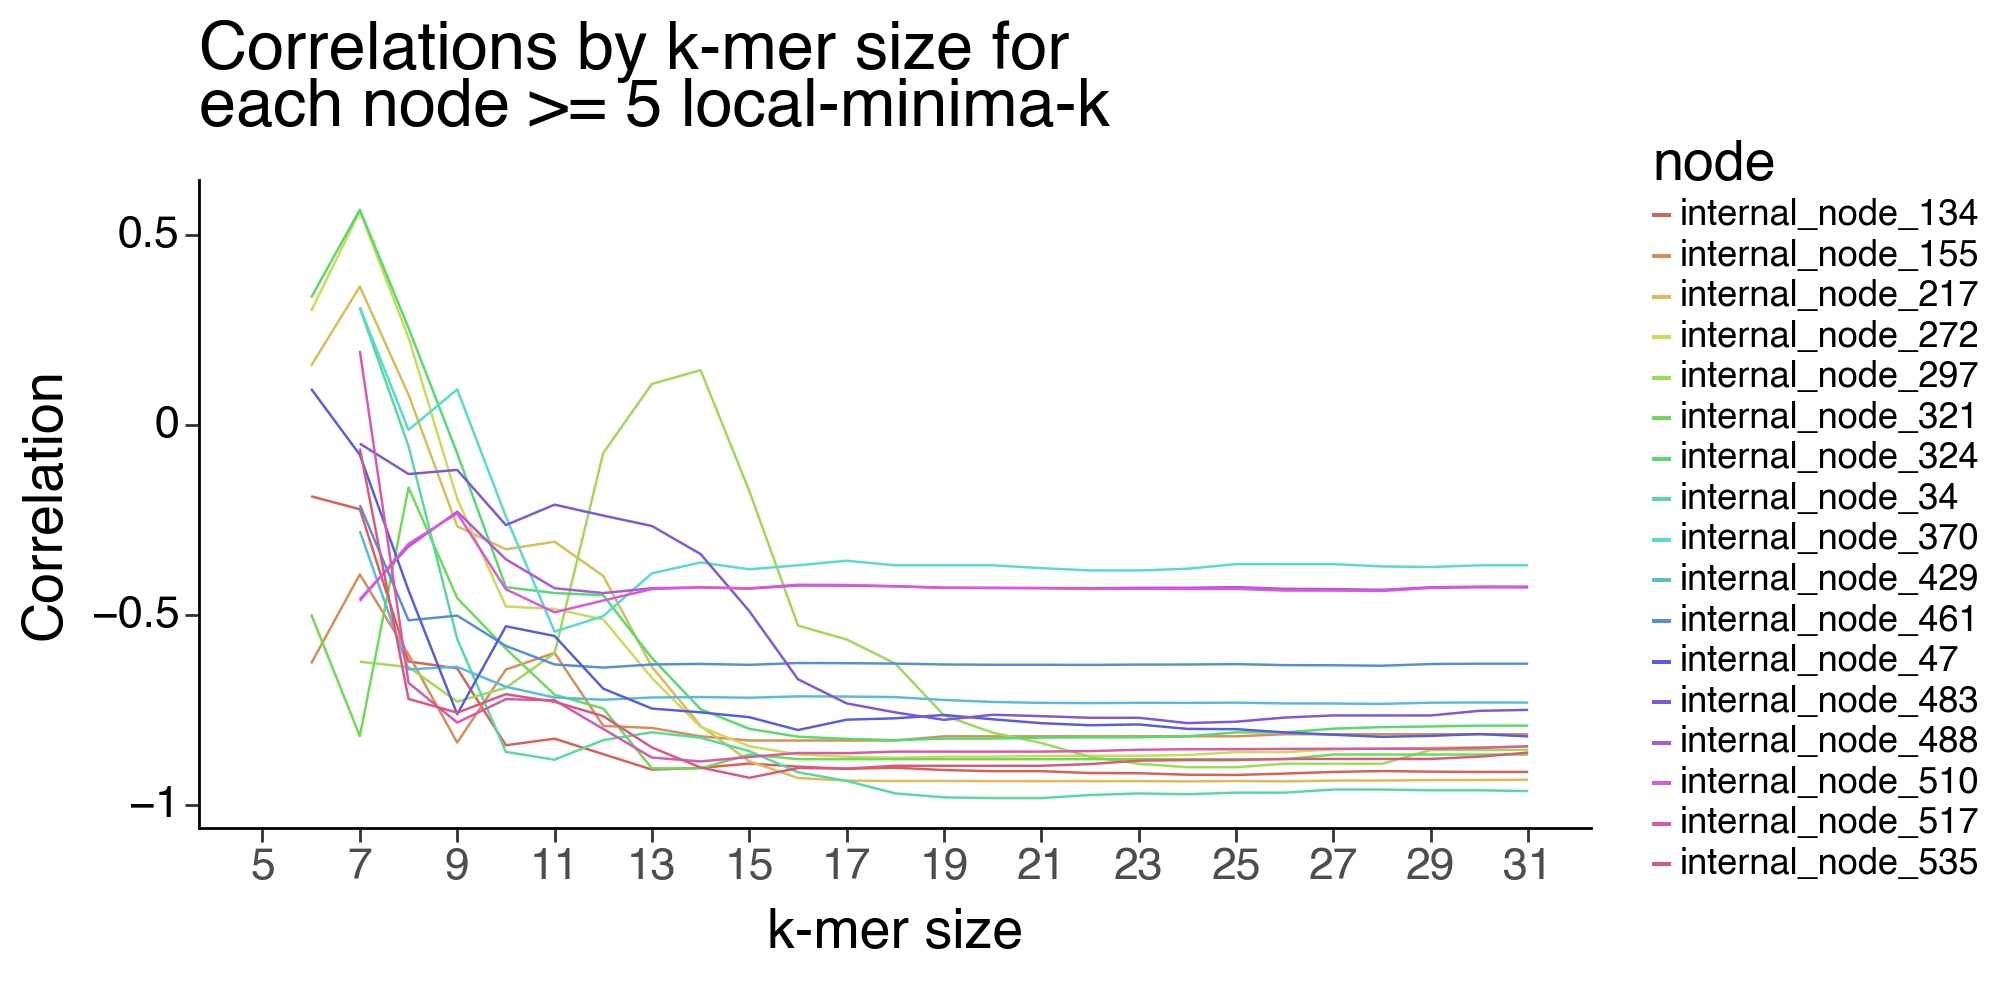

<Figure Size: (1000 x 500)>

In [30]:
# Plot

(
    ggplot(corr_df_long, aes(x='index', y='correlation', color='node')) +
    geom_line() +
    ggtitle("Correlations by k-mer size for\neach node >= 5 local-minima-k") +
    xlab("k-mer size") +
    ylab("Correlation") +
    scale_x_continuous(name="k-mer size", breaks=range(5,32,2)) +
    scale_y_continuous(name="Correlation") +
    theme_tufte_func(base_size=20, rotate=False, figure_size=(10,5)) +
    theme(legend_key_size=7, legend_text=element_text(size=13))
)

# Scratch, archive

In [ ]:
# node_to_corr = {}

# for node_name, (node, II) in internal_node_to_II.items():
#     local_minima, weight_corr = group_best_corr(II, tree_dict, merged_df)
#     print(node_name, local_minima, weight_corr)
#     node_to_corr[node_name] = (local_minima, weight_corr)


# node_to_k = {}

# for node_name, (local_minima, weight_corr) in node_to_corr.items():
#     corr, ks = find_best_correlation(node_name, local_minima, weight_corr)
#     node_to_k[node_name] = ks


In [ ]:
leaf_pair_to_lca = {leaf1: {leaf2: set() for leaf2 in leaf_names} for leaf1 in leaf_names}
leaf_pair_to_lca

In [ ]:
leaf_names =tree1.get_leaf_names()

leaf_pair_to_lca = {leaf1: {leaf2: tree1.get_common_ancestor(leaf1, leaf2) for leaf2 in leaf_names} for leaf1 in leaf_names}
leaf_pair_to_lca

In [ ]:
# given any internal node, get the II set

internal_nodes = [node for node in tree1.traverse() if not node.is_leaf()]
internal_node_to_II = {node: node.get_leaf_names() for node in internal_nodes}
internal_node_to_II



In [ ]:
# Get all internal nodes (non-leaf nodes)
internal_nodes = [node for node in tree1.traverse() if not node.is_leaf()]
print(f"Found {len(internal_nodes)} internal nodes")

for node in internal_nodes:
    node_leaves = node.get_leaf_names()
    leaf_pairs = list(combinations(node_leaves, 2))
    for leaf1, leaf2 in leaf_pairs:
        II = get_II_IO(tree1, leaf1, leaf2)[0]
        leaf_pair_to_II_set[leaf1][leaf2].update(II)
        leaf_pair_to_II_set[leaf2][leaf1].update(II)


print(f"Total pairs counted (with duplicates): {n}")
print(f"Number of unique pairs: {len(unique_pairs)}")


    # print(f"Node with {len(node_leaves)} leaves:")
    # print(node_leaves)

    # You can also print other node properties like:
    # print(f"  Name: {node.name}")
    # print(f"  Distance to root: {node.get_distance(tree1)}")
    # print(f"  Number of children: {len(node.children)}")

In [ ]:
all_leaves = tree1.get_leaves()
leaf1_name = all_leaves[0].name
leaf2_name = all_leaves[100].name

II, IO = get_II_IO(tree1, leaf1_name, leaf2_name)

## Get Correlation for k = [5, 33)
#correlations = []
#for k in range(5, 33):
#    corr, pval = get_correlation(IO, k, tree_dict, merged_df)
#    correlations.append((k, corr))

print(II)

In [ ]:
group_best_corr(II, tree_dict, merged_df)

In [ ]:
# for every LCA, get the IO and II sets
# Get all LCAs and their II/IO sets
lca_sets = {}

# Get all leaves first
all_leaves = tree1.get_leaves()
leaf_names = [leaf.name for leaf in all_leaves]

# For each pair of leaves, get their LCA and compute II/IO sets
for i in range(len(leaf_names)):
    for j in range(i+1, len(leaf_names)):
        leaf1, leaf2 = leaf_names[i], leaf_names[j]
        # Get LCA for this pair
        lca = tree1.get_common_ancestor(leaf1, leaf2)

        # If we haven't processed this LCA yet
        if lca not in lca_sets:
            # Get all leaves under this LCA
            lca_leaves = lca.get_leaves()
            lca_leaf_set = {leaf.name for leaf in lca_leaves}
            all_leaf_set = {leaf.name for leaf in all_leaves}

            # Calculate II and IO sets
            II = set(map(lambda x: tuple(sorted(x)), combinations(lca_leaf_set, 2)))
            # IO = set(map(lambda x: tuple(sorted(x)), combinations(all_leaf_set, 2))) - II

            # Store sets for this LCA
            lca_sets[lca] = {'II': II, 'IO': IO}

# Print summary statistics
print(f"Found {len(lca_sets)} unique LCAs")
for lca, sets in lca_sets.items():
    print(f"LCA with {len(lca.get_leaves())} leaves:")
    print(f"  II set size: {len(sets['II'])}")
    print(f"  IO set size: {len(sets['IO'])}")

In [ ]:
# Get all internal nodes (non-leaf nodes)
internal_nodes = [node for node in tree1.traverse() if not node.is_leaf()]

# Print summary
print(f"Found {len(internal_nodes)} internal nodes")
for node in internal_nodes:
    node_leaves = node.get_leaf_names()
    leaf_pairs = list(combinations(node_leaves, 2))
    for leaf1, leaf2 in leaf_pairs:
        II = get_II_IO(tree1, leaf1, leaf2)[0]
        leaf_pair_to_II_set[leaf1][leaf2].update(II)
        leaf_pair_to_II_set[leaf2][leaf1].update(II)


print(f"Total pairs counted (with duplicates): {n}")
print(f"Number of unique pairs: {len(unique_pairs)}")


    # print(f"Node with {len(node_leaves)} leaves:")
    # print(node_leaves)

    # You can also print other node properties like:
    # print(f"  Name: {node.name}")
    # print(f"  Distance to root: {node.get_distance(tree1)}")
    # print(f"  Number of children: {len(node.children)}")

In [ ]:
# Label each internal node with a unique name
i = 0
for node in tree1.traverse():
    if not node.is_leaf():
        node.name = f"internal_node_{i}"
        i += 1

i

In [ ]:
internal_nodes = [node for node in tree1.traverse() if not node.is_leaf()]
internal_nodes

In [ ]:
# Print summary statistics
print(f"Found {len(lca_sets)} unique LCAs")
for lca, sets in lca_sets.items():
    print(f"LCA with {len(lca.get_leaves())} leaves:")
    print(f"  II set size: {len(sets['II'])}")
    print(f"  IO set size: {len(sets['IO'])}")

In [ ]:
all_names = [leaf.name for leaf in all_leaves]
len(all_names)

In [ ]:
leaf1 = all_names[0]
leaf2 = all_names[100]
leaf3 = all_names[200]

print(leaf1, leaf2, leaf3)

In [ ]:
# lca_sets

lca = tree1.get_common_ancestor(leaf1, leaf2)
len(lca.get_leaves())


In [ ]:
lca = tree1.get_common_ancestor(leaf2, leaf3)
len(lca.get_leaves())

In [ ]:
leaf2, leaf3

In [ ]:

# For each LCA, analyze its II set
for lca, sets in lca_sets.items():
    print(f"\nAnalyzing II set for LCA with {len(lca.get_leaves())} leaves:")
    # print('lca',lca)
    # print('II sets', sets['II'])
    group_best_corr(sets['II'], tree_dict, merged_df)
    if len(lca.get_leaves()) >= 20:
        break

In [ ]:
# Calculate ranks for k_11 and k_20
kX_ranks = merged_df['k_11'].rank()
kY_ranks = merged_df['k_20'].rank()

# Calculate average ranks
avg_ranks = (kX_ranks + kY_ranks) / 2

# Calculate Spearman correlation between average ranks and tree distance
calc_corr(avg_ranks, merged_df['tree_distance'], prnt=True)

In [ ]:
# avg_ms vs tree distance

(
    ggplot(merged_df, aes(x='k_10', y='k_20', color='tree_distance')) +  # dashing_full_k20 index_size
    geom_point(stat="identity", alpha=0.8, size=0.5) +
    ggtitle("Dashing distance: k=20 vs k=10") +
    xlab("k_10") +
    ylab("k_20") +
    theme_tufte_func(base_size=20, rotate=False)
)

In [ ]:
len(merged_df)

In [ ]:
170820

In [ ]:
# labeled bounds from the heatmap are not exact, (rounded)
# dist_low = 0.296
# dist_high = 0.354

# true bounds from the heatmap
dist_low = 0.29643701999999994
dist_high = 0.35377235

c = 0
genome_pairs = []

for g1, g2, dist in l:
    if dist_low <= dist <= dist_high:
        genome_pairs.append((g1, g2))
        print(g1, g2, dist)
        c += 1

assert c == len(genome_pairs)     # these are the correct comparisons, for the bin in the heatmap that we want


In [ ]:
len(genome_pairs)

In [ ]:
merged_df

In [ ]:
merged_df

In [ ]:
bin_3_subset_df = merged_df[merged_df['tree_distance_decile'] == 3]
bin_3_subset_df

In [ ]:

num_bins = 10

# Create deciles based on tree_distance
bin_3_subset_df['tree_distance_decile'] = pd.qcut(bin_3_subset_df['tree_distance'], q=num_bins, labels=False)

# Analyze each decile
results = []
for decile in range(num_bins):
    group_df = bin_3_subset_df[bin_3_subset_df['tree_distance_decile'] == decile]
    best_k, corr, pval = find_best_k_for_group(group_df)

    min_dist = group_df['tree_distance'].min()
    max_dist = group_df['tree_distance'].max()

    results.append({
        'decile': decile,
        'distance_range': f'{min_dist:.3f}-{max_dist:.3f}',
        'best_k': best_k,
        'correlation': corr,
        'p_value': pval,
        'n_samples': len(group_df)
    })

# Display results as DataFrame
results_df = pd.DataFrame(results)
print(results_df.to_string(index=False))

# First, let's create a longer format dataframe for plotting
plot_data = []

# For each decile/group
for decile in range(num_bins):
    group_df = bin_3_subset_df[bin_3_subset_df['tree_distance_decile'] == decile]

    # For each k value
    for k in range(5, 33):
        k_col = f'k_{k}'
        corr, pval = spearmanr(group_df['tree_distance'], group_df[k_col])

        plot_data.append({
            'decile': decile,
            'distance_range': f'{group_df.tree_distance.min():.3f}-{group_df.tree_distance.max():.3f}',
            'k': k,
            'correlation': abs(corr)  # using absolute correlation for visualization
        })

plot_df = pd.DataFrame(plot_data)

# Create the plot
(
    ggplot(plot_df, aes(x='distance_range', y='correlation', color='factor(k)')) +
    geom_line(aes(group='factor(k)')) +  # Add lines connecting points
    geom_point(size=3, alpha=0.7) +
    ggtitle("Correlation Strength by Distance Decile and k-value") +
    xlab("Tree Distance Range") +
    ylab("Correlation") +
    theme_tufte_func(base_size=12, rotate=True) +
    theme(legend_position='right')
)


In [ ]:
# Reshape the data for plotting
plot_df['k'] = plot_df['k'].astype(int)  # convert to int for proper ordering
plot_df['decile'] = plot_df['distance_range']  # use actual distance ranges instead of decile numbers

(
    ggplot(plot_df, aes(x='decile', y='k', fill='correlation')) +
    geom_tile() +
    # scale_fill_gradient(low="#56B1F7", high="#132B43") +  # use blue-red gradient instead of viridis
    scale_y_continuous(breaks=range(5,33)) +  # removed trans='reverse' to have k=5 at bottom
    ggtitle("Correlation Strength by Distance Range and k-value") +
    xlab("Tree Distance Range") +
    ylab("k-value") +
    theme_tufte_func(base_size=12, rotate=False) +
    theme(
        legend_position='right',
        axis_text_x=element_text(angle=45, hjust=1)  # angle the text for better readability
    )
)

In [ ]:
# Reshape the data for plotting
plot_df['k'] = plot_df['k'].astype(int)  # convert to int for proper ordering
plot_df['decile'] = plot_df['distance_range']  # use actual distance ranges instead of decile numbers

# Find best k for each decile
best_k_df = plot_df.loc[plot_df.groupby('decile')['correlation'].idxmax()]
best_k_df['is_best'] = True

# Merge back with original data
plot_df = pd.merge(plot_df, best_k_df[['decile', 'k', 'is_best']],
                  on=['decile', 'k'], how='left')
plot_df['is_best'] = plot_df['is_best'].fillna(False)

(
    ggplot(plot_df, aes(x='decile', y='k', fill='correlation')) +
    geom_tile() +
    # Add red box around best k values
    geom_tile(data=plot_df[plot_df['is_best']],
              mapping=aes(x='decile', y='k'),
              color='red', fill=None, size=1) +
    scale_y_continuous(breaks=range(5,33)) +  # removed trans='reverse' to have k=5 at bottom
    ggtitle("Correlation Strength by Distance Range and k-value") +
    xlab("Tree Distance Range") +
    ylab("k-value") +
    theme_tufte_func(base_size=12, rotate=False) +
    theme(
        legend_position='right',
        axis_text_x=element_text(angle=45, hjust=1)  # angle the text for better readability
    )
)

In [ ]:
ancestors = []

for g1, g2 in genome_pairs:
    g1 = g1.rstrip('.fa')
    g2 = g2.rstrip('.fa')
    ancestors.append(tree1.get_common_ancestor(g1, g2))

ancestors, len(ancestors), len(set(ancestors))

In [ ]:
Counter(ancestors)

In [ ]:
node_id, count = sorted(list(Counter(ancestors).items()), key=lambda x:x[1], reverse=True)[0]
node_id, count

In [ ]:
kid_1, kid_2 = node_id.get_children()
len(kid_1.get_leaves()), len(kid_2.get_leaves())

In [ ]:
# Get all leaves in kid_1
leaves = kid_1.get_leaves()
leaf_names = [leaf.name for leaf in leaves]

# Calculate all pairwise distances within kid_1's leaves
kid1_distances = {}
for i in range(len(leaf_names)):
    for j in range(i+1, len(leaf_names)):
        name1 = leaf_names[i]
        name2 = leaf_names[j]
        # Add .fa extension since dist_tree uses it
        key = (min(name1+'.fa', name2+'.fa'), max(name1+'.fa', name2+'.fa'))
        kid1_distances[key] = dist_tree[key]

print(f"Found {len(kid1_distances)} pairwise distances between {len(leaf_names)} leaves")
# sorted(kid1_distances.values())
min(kid1_distances.values()), max(kid1_distances.values())

In [ ]:
# Get all leaves in kid_2
leaves = kid_2.get_leaves()
leaf_names = [leaf.name for leaf in leaves]

# Calculate all pairwise distances within kid_2's leaves
kid2_distances = {}
for i in range(len(leaf_names)):
    for j in range(i+1, len(leaf_names)):
        name1 = leaf_names[i]
        name2 = leaf_names[j]
        # Add .fa extension since dist_tree uses it
        key = (min(name1+'.fa', name2+'.fa'), max(name1+'.fa', name2+'.fa'))
        kid2_distances[key] = dist_tree[key]

print(f"Found {len(kid2_distances)} pairwise distances between {len(leaf_names)} leaves")
# sorted(kid2_distances.values())
min(kid2_distances.values()), max(kid2_distances.values())

In [ ]:
# true bounds from the heatmap
dist_low = 0.29643701999999994
dist_high = 0.35377235

dist_high - dist_low

In [ ]:
# subtrees
subtree_1_genomes = [kid.name for kid in kid_1.get_leaves()]
subtree_2_genomes = [kid.name for kid in kid_2.get_leaves()]


# Get all pairs within subtree 1
list_1 = list(combinations(subtree_1_genomes, 2))

# Get all pairs within subtree 2
list_2 = list(combinations(subtree_2_genomes, 2))

# Get all pairs between subtree 1 and subtree 2
list_3 = list(product(subtree_1_genomes, subtree_2_genomes))

# Print summary statistics
print(f"Number of pairs within subtree 1: {len(list_1)}")
print(f"Number of pairs within subtree 2: {len(list_2)}")
print(f"Number of pairs between subtrees: {len(list_3)}")

In [ ]:
subtree_1_genomes

In [ ]:

subtree_2_genomes

In [26]:

# Function to find best k for a group

def find_best_k_for_group(group_df):
    ''' Find best for group; group can be of arbitrary size. '''
    best_k = ''
    best_corr = 1  # Initialize to 1 since we want most negative correlation
    best_pval = 0

    for k in range(5, 33):
        k_col = f'k_{k}'
        corr, pval = spearmanr(group_df['tree_distance'], group_df[k_col])
        if corr < best_corr:  # Look for more negative correlation
            best_k = k_col
            best_corr = corr
            best_pval = pval

    return best_k, best_corr, best_pval

In [9]:
def yield_file_lines(path):
    ''' Read file from path line-by-line. '''
    with open(path, 'r') as in_file:
        for line in in_file:
            yield line.strip()

In [ ]:
tree_d_path = '/Users/stephenhwang/Documents/projects/langmead_lab/MEM-ANI/data/cyano/cyanobacteriales_tree_distances.sorted.txt'

names = set()
for x in yield_file_lines(tree_d_path):
    g1, g2, d = x.split('\t')
    names.add(g1)
    names.add(g2)

tree_dict = {_:{_:0 for _ in names} for _ in names}

for x in yield_file_lines(tree_d_path):
    g1, g2, d = x.split('\t')
    d = float(d)
    tree_dict[g1][g2] = d
    tree_dict[g2][g1] = d

len(tree_dict)

In [ ]:
# parse data into dfs

dir_path = '/Users/stephenhwang/Documents/projects/langmead_lab/MEM-ANI/data/cyano/dashing_full_genomes'

# Get list of files in directory
files = [f for f in os.listdir(dir_path) if os.path.isfile(os.path.join(dir_path, f))]

# Create a dictionary to store dataframes
dashing_dfs = {}

# Read each file into a dataframe
for file in files:
    file_path = os.path.join(dir_path, file)
    try:
        # Assuming the files are tab-separated. Adjust sep parameter if needed
        df = pd.read_csv(file_path, sep='\t', header=None)
        dashing_dfs[file] = df
        print(f"Successfully read {file}")
    except Exception as e:
        print(f"Error reading {file}: {str(e)}")

# Print summary of loaded dataframes
print(f"\nLoaded {len(dashing_dfs)} files")
for file, df in dashing_dfs.items():
    print(f"{file}: {df.shape}")


In [ ]:

# Filter for just the distance_k files and sort them by k value
distance_files = sorted([f for f in dashing_dfs.keys() if f.startswith('distance_k')],
                       key=lambda x: int(x.replace('distance_k', '').replace('.txt', '')))

# Create list of pairs and their distances
pairs = []
k_values = {}

# Process first file to get genome names and create pairs
first_df = dashing_dfs[distance_files[0]]
genomes = first_df.iloc[0, 1:].tolist()  # Get genome names from first row

# Clean genome names by removing 'genomes_ncbi/'
genomes = [g.replace('genomes_ncbi/', '') for g in genomes]

# Create all pairs of genomes (upper triangle only)
for i in range(len(genomes)):
    for j in range(i+1, len(genomes)):
        # Sort lexicographically and join with '_'
        pair = '_'.join(sorted([genomes[i], genomes[j]]))
        pairs.append(pair)

# Initialize dataframe with pairs as index
merged_df = pd.DataFrame(index=pairs)

# Add data from each distance file
for file in distance_files:
    k = int(file.replace('distance_k', '').replace('.txt', ''))
    df = dashing_dfs[file]

    # Extract distances for each pair
    distances = []
    for i in range(len(genomes)):
        for j in range(i+1, len(genomes)):
            distances.append(df.iloc[i+1, j+1])

    # Add as new column
    merged_df[f'k_{k}'] = distances

# Clean up the index name
merged_df.index.name = 'genome_pair'


# Add metadat columns to merged_df
genome_pairs = []
genomes_1s = []
genomes_2s = []
tree_distances = []

for index in merged_df.index:
    # Split the genome pair
    genome1 = "_".join(index.split("_", 2)[:2])
    genome2 = "_".join(index.split("_", 2)[2:])

    # Get distance from tree_dict
    distance = tree_dict[genome1][genome2]

    genome_pairs.append(index)
    genomes_1s.append(genome1)
    genomes_2s.append(genome2)
    tree_distances.append(distance)

# Add tree_distance column to merged_df
merged_df['genome_pair'] = genome_pairs
merged_df['genome_1'] = genomes_1s
merged_df['genome_2'] = genomes_2s
merged_df['tree_distance'] = tree_distances

print(f"Final dataframe shape: {merged_df.shape}")
merged_df


In [ ]:
# may have to convert
# Convert all columns except genome identifiers to float
float_cols = [col for col in merged_df.columns if col not in ['genome_pair', 'genome_1', 'genome_2']]
merged_df[float_cols] = merged_df[float_cols].astype(float)
merged_df

In [ ]:
# avg_ms vs tree distance

(
    ggplot(merged_df, aes(x='k_11', y='k_20', color='tree_distance')) +  # dashing_full_k20 index_size
    geom_point(stat="identity", alpha=0.8, size=0.5) +
    ggtitle("Dashing distance: k=20 vs k=11") +
    xlab("k_11") +
    ylab("k_20") +
    theme_tufte_func(base_size=20, rotate=False)
)


In [30]:
def calc_corr(l1, l2, pearson=False, prnt=False):
    if pearson:
        corr, pval = pearsonr(l1, l2)
    else:
        corr, pval = spearmanr(l1, l2)
    if prnt:
        print("Correlation coefficient:", corr)
        print("p-value:", pval)
    return corr, pval

In [ ]:
calc_corr(merged_df['k_11'], merged_df['tree_distance'], prnt=True)

calc_corr(merged_df['k_20'], merged_df['tree_distance'], prnt=True)

In [ ]:
# Calculate ranks for k_11 and k_20
k11_ranks = merged_df['k_11'].rank()
k20_ranks = merged_df['k_20'].rank()

# Store correlations for plotting
k_values = []
correlations = []
single_k_correlations = []

# Calculate correlations using each k value between 12-19 as the middle k
for k in range(5, 33):
    # Get ranks for middle k value
    k_mid_ranks = merged_df[f'k_{k}'].rank()

    # Calculate average ranks across k11, middle k, and k20
    avg_ranks = (k11_ranks + k_mid_ranks + k20_ranks) / 3

    # Calculate correlation for this combination
    corr, pval = calc_corr(avg_ranks, merged_df['tree_distance'], prnt=False)
    print(f"k=11,20,{k}: {corr}, {pval}")

    # Calculate single k correlation
    single_k_corr, _ = calc_corr(k_mid_ranks, merged_df['tree_distance'], prnt=False)

    k_values.append(k)
    correlations.append(corr)
    single_k_correlations.append(single_k_corr)

# Create DataFrame and melt for plotting with legend
plot_df = pd.DataFrame({
    'k_value': k_values,
    'Combined k': correlations,
    'Single k': single_k_correlations
})

plot_df = pd.melt(plot_df,
                  id_vars=['k_value'],
                  value_vars=['Combined k', 'Single k'],
                  var_name='Method',
                  value_name='correlation')

plot_df

In [ ]:
# avg_ms vs tree distance

(
    ggplot(plot_df) +
    geom_point(aes(x='k_value', y='correlation', color='Method'), alpha=0.8) +
    geom_line(aes(x='k_value', y='correlation', color='Method', group='Method'), alpha=0.8) +
    geom_hline(yintercept=-0.79118, linetype='dashed', color='red', alpha=0.8) +
    # ggtitle("Spearman correlation: tree distance and k-mer lengths") +
    ggtitle("") +
    xlab("k value") +
    ylab("Correlation coefficient") +
    theme_tufte_func(base_size=15, rotate=False, figure_size=(7, 5)) +
    scale_x_continuous(breaks=range(5,33,2)) +
    scale_color_manual(values=['#4169E1', '#000000'])  # Royal blue and black colors
    # scale_color_manual(values=['#FFFFFF', '#000000'])  # Royal blue and black colors
)


In [ ]:
plot_df[plot_df['Method'] == 'Combined k']

In [ ]:
np.arange(0, 1.05, 0.05)

In [ ]:

# Calculate ranks for k_11 and k_20
k11_ranks = merged_df['k_11'].rank()
k20_ranks = merged_df['k_20'].rank()

# Create weighted average columns
weighted_columns = {}
for weight in np.arange(0, 1.05, 0.05):
    weight = round(weight, 2)  # Round to avoid floating point issues
    weighted_avg = (1-weight) * k11_ranks + weight * k20_ranks
    corr, _ = calc_corr(weighted_avg, merged_df['tree_distance'], prnt=False)
    weighted_columns[f'w{weight:.2f}'] = corr

# Store correlations for plotting
k_values = []
correlations = []
single_k_correlations = []

# Calculate correlations using each k value between 12-19 as the middle k
for k in range(5, 33):
    # Get ranks for middle k value
    k_mid_ranks = merged_df[f'k_{k}'].rank()

    # Calculate average ranks across k11, middle k, and k20
    avg_ranks = (k11_ranks + k_mid_ranks + k20_ranks) / 3

    # Calculate correlation for this combination
    corr, pval = calc_corr(avg_ranks, merged_df['tree_distance'], prnt=False)
    print(f"k=11,20,{k}: {corr}, {pval}")

    # Calculate single k correlation
    single_k_corr, _ = calc_corr(k_mid_ranks, merged_df['tree_distance'], prnt=False)

    k_values.append(k)
    correlations.append(corr)
    single_k_correlations.append(single_k_corr)

# Create DataFrame with all correlations
plot_df = pd.DataFrame({
    'k_value': k_values,
    'Combined k': correlations,
    'Single k': single_k_correlations,
    **{k: [v]*len(k_values) for k,v in weighted_columns.items()}
})

plot_df = pd.melt(plot_df,
                  id_vars=['k_value'],
                  value_vars=['Combined k', 'Single k'] + list(weighted_columns.keys()),
                  var_name='Method',
                  value_name='correlation')

plot_df


In [ ]:
# Plot correlation vs weights

# Create weight data
weight_data = pd.DataFrame({
    'weight': [float(col.replace('w','')) for col in weighted_columns.keys()],
    'correlation': list(weighted_columns.values())
})

(
    ggplot(weight_data) +
    geom_line(aes(x='weight', y='correlation'), color='#4169E1', alpha=0.8) +
    geom_point(aes(x='weight', y='correlation'), color='#4169E1', alpha=0.8) +
    geom_hline(yintercept=-0.79118, linetype='dashed', color='red', alpha=0.8) +
    ggtitle("") +
    xlab("Weight") +
    ylab("Correlation coefficient") +
    theme_tufte_func(base_size=15, rotate=False, figure_size=(7, 5)) +
    scale_x_continuous(breaks=[0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0])
)


In [ ]:
weight_data


In [ ]:
# single k and combine k of 20 and every other k


# Get k20 ranks
k20_ranks = merged_df['k_20'].rank()

# Store correlations for plotting
k_values = []
correlations = []
single_k_correlations = []

# Calculate correlations for each k value from 5-32
for k in range(5, 33):
    # Get ranks for k value
    k_ranks = merged_df[f'k_{k}'].rank()

    # Calculate single k correlation
    single_k_corr, _ = calc_corr(k_ranks, merged_df['tree_distance'], prnt=False)

    # Calculate average ranks with k20
    avg_ranks = (k_ranks + k20_ranks) / 2

    # Calculate correlation for combined ranks
    corr, _ = calc_corr(avg_ranks, merged_df['tree_distance'], prnt=False)

    k_values.append(k)
    correlations.append(corr)
    single_k_correlations.append(single_k_corr)

# Create DataFrame and melt for plotting with legend
plot_df = pd.DataFrame({
    'k_value': k_values,
    'avg rank k 20 and k': correlations,
    'single k': single_k_correlations
})

plot_df = pd.melt(plot_df,
                  id_vars=['k_value'],
                  value_vars=['avg rank k 20 and k', 'single k'],
                  var_name='Method',
                  value_name='correlation')

plot_df

In [ ]:
# avg_ms vs tree distance

(
    ggplot(plot_df) +
    geom_point(aes(x='k_value', y='correlation', color='Method'), alpha=0.8) +
    geom_line(aes(x='k_value', y='correlation', color='Method', group='Method'), alpha=0.8) +
    geom_hline(yintercept=-0.79118, linetype='dashed', color='red', alpha=0.8) +
    ggtitle("Cyanobacteriales: single k and avg_rank(20, k)") +
    xlab("k value") +
    ylab("Correlation coefficient") +
    theme_tufte_func(base_size=15, rotate=False, figure_size=(7, 5)) +
    scale_x_continuous(breaks=range(5,33,2)) +
    scale_color_manual(values=['#4169E1', '#000000'])  # Royal blue and black colors
)


In [ ]:
# k11, 20: -0.79118
plot_df[plot_df['Method'] == 'avg rank k 20 and k']


In [ ]:
# Calculate ranks for k_11 and k_20
k11_ranks = merged_df['k_21'].rank()
k20_ranks = merged_df['k_20'].rank()

# Calculate average ranks
avg_ranks = (k11_ranks + k20_ranks) / 2

# Calculate Spearman correlation between average ranks and tree distance
calc_corr(avg_ranks, merged_df['tree_distance'], prnt=True)

In [ ]:
# read file

# Read data without headers first
memo_jaccard_df = pd.read_csv('/Users/stephenhwang/Documents/projects/langmead_lab/MEM-ANI/data/cyano/memo_jaccard_k5_k55.txt', sep='\t', header=None)

# Create column names
k_cols = [f'memo_k_{k}' for k in range(5,56)]
col_names = ['genome_1', 'genome_2'] + k_cols

# Assign column names
memo_jaccard_df.columns = col_names

# Add genome pair column with lexicographically ordered genomes
memo_jaccard_df['genome_pair'] = memo_jaccard_df.apply(
    lambda x: '_'.join(sorted([x['genome_1'], x['genome_2']])),
    axis=1
)

# Reset index to make genome_pair a regular column before merging
merged_df_reset = merged_df.reset_index(drop=True)

# Rename k_ columns to dashing_k_ in merged_df_reset
k_columns = [col for col in merged_df_reset.columns if col.startswith('k_')]
rename_dict = {col: f'dashing_{col}' for col in k_columns}
merged_df_reset = merged_df_reset.rename(columns=rename_dict)

# Merge with merged_df based on genome_pair
merged_jaccard_df = pd.merge(merged_df_reset, memo_jaccard_df, on='genome_pair', how='inner')

merged_jaccard_df


In [ ]:
print(list(merged_jaccard_df))

In [ ]:

# Create lists to store correlations
memo_corrs = []
dashing_corrs = []
memo_k_values = list(range(5, 56))
dashing_k_values = list(range(5, 33))

# Calculate correlations for each k
for k in memo_k_values:
    # For memo
    memo_col = f'memo_k_{k}'
    memo_corr = calc_corr(merged_jaccard_df[memo_col], merged_jaccard_df['tree_distance'])[0]
    memo_corrs.append(memo_corr)

for k in dashing_k_values:
    # For dashing
    dashing_col = f'dashing_k_{k}'
    dashing_corr = calc_corr(merged_jaccard_df[dashing_col], merged_jaccard_df['tree_distance'])[0]
    dashing_corrs.append(dashing_corr)


In [ ]:
# Create dataframe for plotting
plot_df = pd.DataFrame({
    'k': memo_k_values + dashing_k_values,
    'correlation': memo_corrs + dashing_corrs,
    'Method': ['MS-based'] * len(memo_k_values) + ['Dashing'] * len(dashing_k_values)
})

# Create plot
(
    ggplot(plot_df) +
    geom_point(aes(x='k', y='correlation', color='Method'), alpha=0.8) +
    geom_line(aes(x='k', y='correlation', color='Method', group='Method'), alpha=0.8) +
    ggtitle("Cyanobacteriales: MS-based and Dashing Jaccard") +
    xlab("k value") +
    ylab("Correlation coefficient") +
    theme_tufte_func(base_size=15, rotate=False, figure_size=(7, 5)) +
    scale_x_continuous(breaks=range(5,56,5)) +
    scale_color_manual(values=['#4169E1', '#000000'])  # Royal blue and black colors
)

In [ ]:
# Calculate ranks for k_11, k_20 and other k values
k11_ranks = merged_jaccard_df['memo_k_11'].rank()
k20_ranks = merged_jaccard_df['memo_k_20'].rank()

# Store correlations for plotting
k_values = []
one_k = []
two_k = []
three_k = []

# Calculate correlations using each k value between 5-55
for k in range(5, 56):
    # Get ranks for k value
    k_mid_ranks = merged_jaccard_df[f'memo_k_{k}'].rank()

    # Calculate average ranks across k11, middle k, and k20
    avg_ranks_three = (k11_ranks + k_mid_ranks + k20_ranks) / 3

    # Calculate average ranks for k20 and current k
    avg_ranks_two = (k20_ranks + k_mid_ranks) / 2

    # Calculate correlation for three k combination
    corr, pval = calc_corr(avg_ranks_three, merged_jaccard_df['tree_distance'], prnt=False)
    print(f"k=11,20,{k}: {corr}, {pval}")

    # Calculate correlation for two k combination
    two_k_corr, _ = calc_corr(avg_ranks_two, merged_jaccard_df['tree_distance'], prnt=False)

    # Calculate single k correlation
    single_k_corr, _ = calc_corr(k_mid_ranks, merged_jaccard_df['tree_distance'], prnt=False)

    k_values.append(k)
    one_k.append(single_k_corr)
    two_k.append(two_k_corr)
    three_k.append(corr)

# Create DataFrame and melt for plotting with legend
plot_df = pd.DataFrame({
    'k_value': k_values,
    'Three k': three_k,
    'Two k': two_k,
    'One k': one_k
})

plot_df = pd.melt(plot_df,
                  id_vars=['k_value'],
                  value_vars=['Three k', 'Two k', 'One k'],
                  var_name='Method',
                  value_name='correlation')


################################################################################
# plot cyano memo-jaccard

(
    ggplot(plot_df) +
    geom_point(aes(x='k_value', y='correlation', color='Method'), alpha=0.8) +
    geom_line(aes(x='k_value', y='correlation', color='Method', group='Method'), alpha=0.8) +
    geom_hline(yintercept=-0.79118, linetype='dashed', color='red', alpha=0.8) +
    ggtitle("Cyanobacteriales, MS-based-Jaccard: 1 to 3- k") +
    xlab("k value") +
    ylab("Correlation coefficient") +
    theme_tufte_func(base_size=15, rotate=False, figure_size=(7, 5)) +
    scale_x_continuous(breaks=range(5,56,5)) +
    scale_color_manual(values=['#000000', '#4169E1', '#008000'],  # Black, Royal blue, Green
                      breaks=['One k', 'Two k', 'Three k'])  # Specify legend order
)

In [ ]:
# Calculate ranks for k_11, k_20 and other k values
k11_ranks = merged_jaccard_df['dashing_k_11'].rank()
k20_ranks = merged_jaccard_df['dashing_k_20'].rank()

# Store correlations for plotting
k_values = []
one_k = []
two_k = []
three_k = []

# Calculate correlations using each k value between 5-32
for k in range(5, 33):
    # Get ranks for k value
    k_mid_ranks = merged_jaccard_df[f'dashing_k_{k}'].rank()

    # Calculate average ranks across k11, middle k, and k20
    avg_ranks_three = (k11_ranks + k_mid_ranks + k20_ranks) / 3

    # Calculate average ranks for k20 and current k
    avg_ranks_two = (k20_ranks + k_mid_ranks) / 2

    # Calculate correlation for three k combination
    corr, pval = calc_corr(avg_ranks_three, merged_jaccard_df['tree_distance'], prnt=False)
    print(f"k=11,20,{k}: {corr}, {pval}")

    # Calculate correlation for two k combination
    two_k_corr, _ = calc_corr(avg_ranks_two, merged_jaccard_df['tree_distance'], prnt=False)

    # Calculate single k correlation
    single_k_corr, _ = calc_corr(k_mid_ranks, merged_jaccard_df['tree_distance'], prnt=False)

    k_values.append(k)
    one_k.append(single_k_corr)
    two_k.append(two_k_corr)
    three_k.append(corr)

# Create DataFrame and melt for plotting with legend
plot_df = pd.DataFrame({
    'k_value': k_values,
    'Three k': three_k,
    'Two k': two_k,
    'One k': one_k
})

plot_df = pd.melt(plot_df,
                  id_vars=['k_value'],
                  value_vars=['Three k', 'Two k', 'One k'],
                  var_name='Method',
                  value_name='correlation')


################################################################################
# plot cyano dashing-jaccard

(
    ggplot(plot_df) +
    geom_point(aes(x='k_value', y='correlation', color='Method'), alpha=0.8) +
    geom_line(aes(x='k_value', y='correlation', color='Method', group='Method'), alpha=0.8) +
    geom_hline(yintercept=-0.79118, linetype='dashed', color='red', alpha=0.8) +
    ggtitle("Cyanobacteriales, Dashing-Jaccard: 1 to 3- k") +
    xlab("k value") +
    ylab("Correlation coefficient") +
    theme_tufte_func(base_size=15, rotate=False, figure_size=(7, 5)) +
    scale_x_continuous(breaks=range(5,33,5)) +
    scale_color_manual(values=['#000000', '#4169E1', '#008000'],  # Black, Royal blue, Green
                      breaks=['One k', 'Two k', 'Three k'])  # Specify legend order
)

In [ ]:
k11_ranks = merged_jaccard_df['memo_k_11'].rank()
k20_ranks = merged_jaccard_df['memo_k_20'].rank()
avg_ranks = (k11_ranks + k20_ranks) / 2
corr, pval = calc_corr(avg_ranks, merged_jaccard_df['tree_distance'], prnt=False)
print(f"Correlation for avg of k=11,20: {corr}, {pval}")


In [ ]:
k11_ranks = merged_jaccard_df['dashing_k_11'].rank()
k20_ranks = merged_jaccard_df['dashing_k_20'].rank()
avg_ranks = (k11_ranks + k20_ranks) / 2
corr, pval = calc_corr(avg_ranks, merged_jaccard_df['tree_distance'], prnt=False)
print(f"Correlation for avg of k=11,20: {corr}, {pval}")


In [ ]:
# Calculate ranks for k_11, k_20 and other k values
k11_ranks = merged_df['k_11'].rank()
k20_ranks = merged_df['k_20'].rank()

# Store correlations for plotting
k_values = []
one_k = []
two_k = []
three_k = []

# Calculate correlations using each k value between 5-32
for k in range(5, 33):
    # Get ranks for k value
    k_mid_ranks = merged_df[f'k_{k}'].rank()

    # Calculate average ranks across k11, middle k, and k20
    avg_ranks_three = (k11_ranks + k_mid_ranks + k20_ranks) / 3

    # Calculate average ranks for k20 and current k
    avg_ranks_two = (k20_ranks + k_mid_ranks) / 2

    # Calculate correlation for three k combination
    corr, pval = calc_corr(avg_ranks_three, merged_df['tree_distance'], prnt=False)
    print(f"k=11,20,{k}: {corr}, {pval}")

    # Calculate correlation for two k combination
    two_k_corr, _ = calc_corr(avg_ranks_two, merged_df['tree_distance'], prnt=False)

    # Calculate single k correlation
    single_k_corr, _ = calc_corr(k_mid_ranks, merged_df['tree_distance'], prnt=False)

    k_values.append(k)
    one_k.append(single_k_corr)
    two_k.append(two_k_corr)
    three_k.append(corr)

# Create DataFrame and melt for plotting with legend
plot_df = pd.DataFrame({
    'k_value': k_values,
    'Three k': three_k,
    'Two k': two_k,
    'One k': one_k
})

# Print best correlations for each method
print(f"\nBest correlations:")
# Find min correlation and corresponding k value for each method
three_k_min = min([(x, k) for k,x in zip(plot_df['k_value'], plot_df['Three k']) if not pd.isna(x)])
two_k_min = min([(x, k) for k,x in zip(plot_df['k_value'], plot_df['Two k']) if not pd.isna(x)])
one_k_min = min([(x, k) for k,x in zip(plot_df['k_value'], plot_df['One k']) if not pd.isna(x)])
print(f"One k: {one_k_min[0]} at k={one_k_min[1]}")
print(f"Two k: {two_k_min[0]} at k={two_k_min[1]}")
print(f"Three k: {three_k_min[0]} at k={three_k_min[1]}")

plot_df = pd.melt(plot_df,
                  id_vars=['k_value'],
                  value_vars=['Three k', 'Two k', 'One k'],
                  var_name='Method',
                  value_name='correlation')


################################################################################
# plot cyano dashing-jaccard

(
    ggplot(plot_df) +
    geom_point(aes(x='k_value', y='correlation', color='Method'), alpha=0.8) +
    geom_line(aes(x='k_value', y='correlation', color='Method', group='Method'), alpha=0.8) +
    geom_hline(yintercept=-0.79118, linetype='dashed', color='red', alpha=0.8) +
    ggtitle("Cyanobacteriales, Dashing-Jaccard: 1 to 3- k") +
    xlab("k value") +
    ylab("Correlation coefficient") +
    theme_tufte_func(base_size=15, rotate=False, figure_size=(7, 5)) +
    scale_x_continuous(breaks=range(5,33,5)) +
    scale_color_manual(values=['#000000', '#4169E1', '#008000'],  # Black, Royal blue, Green
                      breaks=['One k', 'Two k', 'Three k'])  # Specify legend order
)

In [199]:
# Trying the procedure


def find_local_minima(df, low_k, high_k):
    # Store k values and correlations
    k_values = []
    corrs = []

    # Calculate correlations for each k
    for k in range(low_k, high_k + 1):
        k_col = f'k_{k}'
        corr, _ = spearmanr(df['tree_distance'], df[k_col])
        k_values.append(k)
        corrs.append(corr)

    # Find local minima
    local_minima = []
    for i in range(1, len(corrs)-1):
        if corrs[i] < corrs[i-1] and corrs[i] < corrs[i+1]:
            local_minima.append((k_values[i], corrs[i]))

    # Create plot
    plot_df = pd.DataFrame({
        'k': k_values,
        'correlation': corrs
    })

    plot = (
        ggplot(plot_df) +
        geom_point(aes(x='k', y='correlation'), alpha=0.8) +
        geom_line(aes(x='k', y='correlation'), alpha=0.8) +
        ggtitle("Correlation vs k-mer size") +
        xlab("k-mer size") +
        ylab("Correlation coefficient") +
        theme_tufte_func(base_size=15, rotate=False, figure_size=(7, 5)) +
        scale_x_continuous(breaks=range(low_k, high_k+1, 5))
    )
    return local_minima, plot


def plot_weighted_correlations(df, local_minima_k):
    # Check that we have exactly 2 k values
    if len(local_minima_k) != 2:
        raise ValueError("Must provide exactly 2 k values for weighting")

    k1, k2 = local_minima_k[0], local_minima_k[1]

    # Create array of weights from 0 to 1 with step 0.05
    weights = np.arange(0, 1.05, 0.05)

    # Store correlations for each weight
    weighted_corrs = []

    # Calculate weighted correlations
    for w in weights:
        # Get ranks for each k value
        rank1 = df[f'k_{k1}'].rank()
        rank2 = df[f'k_{k2}'].rank()

        # Calculate weighted average of the ranks
        weighted_avg = (1-w) * rank1 + w * rank2

        # Calculate correlation
        corr, _ = spearmanr(df['tree_distance'], weighted_avg)
        weighted_corrs.append(corr)

    # Create dataframe for plotting
    plot_df = pd.DataFrame({
        'weight': weights,
        'correlation': weighted_corrs
    })

    # Create plot
    return (ggplot(plot_df) +
        geom_point(aes(x='weight', y='correlation'), alpha=0.8) +
        geom_line(aes(x='weight', y='correlation'), alpha=0.8) +
        ggtitle(f"Correlation vs Weight (k={k1} and k={k2})") +
        xlab(f"Weight of k={k1}") +
        ylab("Correlation coefficient") +
        theme_tufte_func(base_size=15, rotate=False, figure_size=(7, 5))
    )

In [ ]:
local_minima, plot = find_local_minima(merged_df, 5, 32)

print(local_minima)
plot

In [ ]:
weight_minima, plot = plot_weighted_correlations(merged_df, local_minima)

print(weight_minima)
plot


In [213]:
# Trying the procedure

def find_local_minima(df, low_k, high_k):
    # Store k values and correlations
    k_values = []
    corrs = []

    # Calculate correlations for each k
    for k in range(low_k, high_k + 1):
        k_col = f'k_{k}'
        corr, _ = spearmanr(df['tree_distance'], df[k_col])
        k_values.append(k)
        corrs.append(corr)

    # Find local minima
    local_minima = []
    for i in range(1, len(corrs)-1):
        if corrs[i] < corrs[i-1] and corrs[i] < corrs[i+1]:
            local_minima.append((k_values[i], corrs[i]))

    # Create plot
    plot_df = pd.DataFrame({
        'k': k_values,
        'correlation': corrs
    })

    plot = (
        ggplot(plot_df) +
        geom_point(aes(x='k', y='correlation'), alpha=0.8) +
        geom_line(aes(x='k', y='correlation'), alpha=0.8) +
        ggtitle("Correlation vs k-mer size") +
        xlab("k-mer size") +
        ylab("Correlation coefficient") +
        theme_tufte_func(base_size=15, rotate=False, figure_size=(7, 5)) +
        scale_x_continuous(breaks=range(low_k, high_k+1, 5))
    )
    return local_minima, plot


def plot_weighted_correlations(df, k1, k2):
    # Create array of weights from 0 to 1 with step 0.05
    weights = np.arange(0, 1.05, 0.05)

    # Store correlations for each weight
    weighted_corrs = []

    # Calculate weighted correlations
    for w in weights:
        # Get ranks for each k value
        rank1 = df[f'k_{k1}'].rank()
        rank2 = df[f'k_{k2}'].rank()

        # Calculate weighted average of the ranks
        weighted_avg = (1-w) * rank1 + w * rank2

        # Calculate correlation
        corr, _ = spearmanr(df['tree_distance'], weighted_avg)
        weighted_corrs.append(corr)

    # Find weight that gives most negative correlation
    best_weight = weights[np.argmin(weighted_corrs)]
    best_corr = min(weighted_corrs)

    # Create dataframe for plotting
    plot_df = pd.DataFrame({
        'weight': weights,
        'correlation': weighted_corrs
    })

    # Create plot
    plot = (ggplot(plot_df) +
        geom_point(aes(x='weight', y='correlation'), alpha=0.8) +
        geom_line(aes(x='weight', y='correlation'), alpha=0.8) +
        ggtitle(f"Correlation vs Weight (k={k1} and k={k2})") +
        xlab(f"Weight of k={k1}") +
        ylab("Correlation coefficient") +
        theme_tufte_func(base_size=15, rotate=False, figure_size=(7, 5))
    )

    return best_weight, best_corr, plot

def recursive_optimization(df, low_k=5, high_k=32):
    best_corr = 0
    iteration = 1
    results = []

    while True:
        print(f"\nIteration {iteration}")

        # Find local minima
        local_minima, plot = find_local_minima(df, low_k, high_k)
        print(f"Found {len(local_minima)} local minima")

        if len(local_minima) < 2:
            print("Not enough local minima to continue")
            break

        # Take first two local minima
        k1, corr1 = local_minima[0]
        k2, corr2 = local_minima[1]

        # Find best weight for these k values
        best_weight, curr_corr, plot = plot_weighted_correlations(df, k1, k2)
        print(f"Best correlation: {curr_corr} with weight {best_weight} between k={k1} and k={k2}")

        # If correlation didn't improve, stop
        if curr_corr >= best_corr and iteration > 1:
            print("Correlation did not improve, stopping")
            # Try next pair of local minima
            if len(local_minima) >= 3:
                k1_next, corr1_next = local_minima[1]
                k2_next, corr2_next = local_minima[2]
                next_weight, next_corr, _ = plot_weighted_correlations(df, k1_next, k2_next)
                print(f"Next best correlation would be: {next_corr} with weight {next_weight} between k={k1_next} and k={k2_next}")
            break

        best_corr = curr_corr
        results.append({
            'iteration': iteration,
            'k1': k1,
            'k2': k2,
            'weight': best_weight,
            'correlation': curr_corr
        })

        # Create weighted ranks for next iteration
        rank1 = df[f'k_{k1}'].rank()
        rank2 = df[f'k_{k2}'].rank()
        weighted_ranks = (1-best_weight) * rank1 + best_weight * rank2

        # Add weighted ranks as new column for next iteration
        df[f'weighted_k_{iteration}'] = weighted_ranks

        iteration += 1

    return pd.DataFrame(results)

In [ ]:
# Run recursive optimization with merged_df
results = recursive_optimization(merged_df, low_k=5, high_k=32)
results

In [ ]:
plot_df

In [ ]:

# Create dataframe for plotting
plot_df = pd.DataFrame({
    'k': memo_k_values + dashing_k_values,
    'correlation': memo_corrs + dashing_corrs,
    'Method': ['MS-based'] * len(memo_k_values) + ['Dashing'] * len(dashing_k_values)
})

# Create plot
(
    ggplot(plot_df) +
    geom_point(aes(x='k', y='correlation', color='Method'), alpha=0.8) +
    geom_line(aes(x='k', y='correlation', color='Method', group='Method'), alpha=0.8) +
    ggtitle("Cyanobacteriales: MS-based and Dashing Jaccard") +
    xlab("k value") +
    ylab("Correlation coefficient") +
    theme_tufte_func(base_size=15, rotate=False, figure_size=(7, 5)) +
    scale_x_continuous(breaks=range(5,56,5)) +
    scale_color_manual(values=['#4169E1', '#000000'])  # Royal blue and black colors
)

In [ ]:
# k=20: Correlation coefficient: -0.7925296727478357, p-value: 0.0


In [ ]:
calc_corr(k20_ranks, merged_df['tree_distance'], prnt=True)

In [ ]:
calc_corr(k11_ranks, merged_df['tree_distance'], prnt=True)

In [ ]:
len(merged_df)

In [ ]:
num_bins = 10

# Create deciles based on tree_distance
merged_df['tree_distance_decile'] = pd.qcut(merged_df['tree_distance'], q=num_bins, labels=False)

# Analyze each decile
results = []
for decile in range(num_bins):
    group_df = merged_df[merged_df['tree_distance_decile'] == decile]
    best_k, corr, pval = find_best_k_for_group(group_df)

    min_dist = group_df['tree_distance'].min()
    max_dist = group_df['tree_distance'].max()

    results.append({
        'decile': decile,
        'distance_range': f'{min_dist:.3f}-{max_dist:.3f}',
        'best_k': best_k,
        'correlation': corr,
        'p_value': pval,
        'n_samples': len(group_df)
    })

# Display results as DataFrame
results_df = pd.DataFrame(results)
print(results_df.to_string(index=False))

# First, let's create a longer format dataframe for plotting
plot_data = []

# For each decile/group
for decile in range(num_bins):
    group_df = merged_df[merged_df['tree_distance_decile'] == decile]

    # For each k value
    for k in range(5, 33):
        k_col = f'k_{k}'
        corr, pval = spearmanr(group_df['tree_distance'], group_df[k_col])

        plot_data.append({
            'decile': decile,
            'distance_range': f'{group_df.tree_distance.min():.3f}-{group_df.tree_distance.max():.3f}',
            'k': k,
            'correlation': abs(corr)  # using absolute correlation for visualization
        })

plot_df = pd.DataFrame(plot_data)

# Create the plot
(
    ggplot(plot_df, aes(x='distance_range', y='correlation', color='factor(k)')) +
    geom_line(aes(group='factor(k)')) +  # Add lines connecting points
    geom_point(size=3, alpha=0.7) +
    ggtitle("Correlation by Distance Decile - Cyanobacteriales") +
    xlab("Tree Distance Range") +
    ylab("Correlation") +
    theme_tufte_func(base_size=12, rotate=True) +
    theme(legend_position='right')
)


In [ ]:
# Reshape the data for plotting
plot_df['k'] = plot_df['k'].astype(int)  # convert to int for proper ordering
plot_df['decile'] = plot_df['distance_range']  # use actual distance ranges instead of decile numbers

(
    ggplot(plot_df, aes(x='decile', y='k', fill='correlation')) +
    geom_tile() +
    # scale_fill_gradient(low="#56B1F7", high="#132B43") +  # use blue-red gradient instead of viridis
    scale_y_continuous(breaks=range(5,33)) +  # removed trans='reverse' to have k=5 at bottom
    ggtitle("Correlation by Distance Decile - Cyanobacteriales") +
    xlab("Tree Distance Range") +
    ylab("k-value") +
    theme_tufte_func(base_size=12, rotate=False) +
    theme(
        legend_position='right',
        axis_text_x=element_text(angle=45, hjust=1)  # angle the text for better readability
    )
)

In [ ]:
print(f"Number of pairs within subtree 1: {len(list_1)}")
print(f"Number of pairs within subtree 2: {len(list_2)}")
print(f"Number of pairs between subtrees: {len(list_3)}")

In [ ]:
# Convert lists of tuples into lists of joined genome names to match merged_df format
pairs_1 = ['_'.join(sorted(pair)) for pair in list_1]
pairs_2 = ['_'.join(sorted(pair)) for pair in list_2]
pairs_3 = ['_'.join(sorted(pair)) for pair in list_3]

# Create the three subsetted dataframes
df_1 = merged_df[merged_df['genome_pair'].isin(pairs_1)]
df_2 = merged_df[merged_df['genome_pair'].isin(pairs_2)]
df_3 = merged_df[merged_df['genome_pair'].isin(pairs_3)]

# Print summary statistics to verify
print(f"Original merged_df shape: {merged_df.shape}")
print(f"Subtree 1 pairs df shape: {df_1.shape}")
print(f"Subtree 2 pairs df shape: {df_2.shape}")
print(f"Between subtrees df shape: {df_3.shape}")

In [ ]:
# Create data for plotting
plot_data = []

# For each k value and each dataset
for k in range(5, 33):
    k_col = f'k_{k}'

    # Calculate correlations for each dataset
    corr1, _ = spearmanr(df_1['tree_distance'], df_1[k_col])
    corr2, _ = spearmanr(df_2['tree_distance'], df_2[k_col])
    corr3, _ = spearmanr(df_3['tree_distance'], df_3[k_col])

    # Create labels with number of comparisons and tree sizes
    label1 = f"Within Subtree 1\n(n={len(df_1):,}, size={len(kid_1.get_leaves()):,})"
    label2 = f"Within Subtree 2\n(n={len(df_2):,}, size={len(kid_2.get_leaves()):,})"
    label3 = f"Between Subtrees\n(n={len(df_3):,})"

    # Add data for each subset
    plot_data.extend([
        {'k': k, 'subset': label1, 'correlation': abs(corr1), 'order': 1},
        {'k': k, 'subset': label2, 'correlation': abs(corr2), 'order': 2},
        {'k': k, 'subset': label3, 'correlation': abs(corr3), 'order': 3}
    ])

plot_df = pd.DataFrame(plot_data)

# Create the heatmap
(ggplot(plot_df, aes(x='subset', y='k', fill='correlation')) +
    geom_tile() +
    scale_y_continuous(breaks=range(5,33)) +
    ggtitle("Correlation between k-mer sizes and Tree Distance by Subset") +
    xlab("Genome Pair Type") +
    ylab("k-value") +
    scale_x_discrete(limits=[f"Within Subtree 1\n(n={len(df_1):,}, size={len(kid_1.get_leaves()):,})",
                           f"Within Subtree 2\n(n={len(df_2):,}, size={len(kid_2.get_leaves()):,})",
                           f"Between Subtrees\n(n={len(df_3):,})"]) +
    theme_tufte_func(base_size=12) +
    theme(
        legend_position='right',
        axis_text_x=element_text(angle=45, hjust=1)  # Angle the text for better readability
    )
)

# Just df_3

In [ ]:
node_id = tree1.get_common_ancestor(subtree_2_genomes[0], subtree_2_genomes[-1])
kid_1, kid_2 = node_id.get_children()
len(kid_1.get_leaves()), len(kid_2.get_leaves())


In [ ]:
kid_1.get_leaves()

leaves = kid_1.get_leaves()
leaf_names = [leaf.name for leaf in leaves]

# Calculate all pairwise distances within kid_1's leaves
kid1_distances = {}
for i in range(len(leaf_names)):
    for j in range(i+1, len(leaf_names)):
        name1 = leaf_names[i]
        name2 = leaf_names[j]
        # Add .fa extension since dist_tree uses it
        key = (min(name1+'.fa', name2+'.fa'), max(name1+'.fa', name2+'.fa'))
        kid1_distances[key] = dist_tree[key]

print(f"Found {len(kid1_distances)} pairwise distances between {len(leaf_names)} leaves")
# sorted(kid2_distances.values())
min(kid1_distances.values()), max(kid1_distances.values())


In [ ]:
kid_2.get_leaves()

leaves = kid_2.get_leaves()
leaf_names = [leaf.name for leaf in leaves]

# Calculate all pairwise distances within kid_2's leaves
kid2_distances = {}
for i in range(len(leaf_names)):
    for j in range(i+1, len(leaf_names)):
        name1 = leaf_names[i]
        name2 = leaf_names[j]
        # Add .fa extension since dist_tree uses it
        key = (min(name1+'.fa', name2+'.fa'), max(name1+'.fa', name2+'.fa'))
        kid2_distances[key] = dist_tree[key]

print(f"Found {len(kid2_distances)} pairwise distances between {len(leaf_names)} leaves")
# sorted(kid2_distances.values())
min(kid2_distances.values()), max(kid2_distances.values())


In [ ]:
# subtrees
subtree_1_genomes = [kid.name for kid in kid_1.get_leaves()]
subtree_2_genomes = [kid.name for kid in kid_2.get_leaves()]


# Get all pairs within subtree 1
list_1 = list(combinations(subtree_1_genomes, 2))

# Get all pairs within subtree 2
list_2 = list(combinations(subtree_2_genomes, 2))

# Get all pairs between subtree 1 and subtree 2
list_3 = list(product(subtree_1_genomes, subtree_2_genomes))

# Print summary statistics
print(f"Number of pairs within subtree 1: {len(list_1)}, from n={len(subtree_1_genomes)}")
print(f"Number of pairs within subtree 2: {len(list_2)}, from n={len(subtree_2_genomes)}")
print(f"Number of pairs between subtrees: {len(list_3)}, from n={len(subtree_1_genomes)} and n={len(subtree_2_genomes)}")


In [ ]:
# Convert lists of tuples into lists of joined genome names to match merged_df format
pairs_1 = ['_'.join(sorted(pair)) for pair in list_1]
pairs_2 = ['_'.join(sorted(pair)) for pair in list_2]
pairs_3 = ['_'.join(sorted(pair)) for pair in list_3]

# Create the three subsetted dataframes
df_1 = merged_df[merged_df['genome_pair'].isin(pairs_1)]
df_2 = merged_df[merged_df['genome_pair'].isin(pairs_2)]
df_3 = merged_df[merged_df['genome_pair'].isin(pairs_3)]

# Print summary statistics to verify
print(f"Original merged_df shape: {merged_df.shape}")
print(f"Subtree 1 pairs df shape: {df_1.shape}")
print(f"Subtree 2 pairs df shape: {df_2.shape}")
print(f"Between subtrees df shape: {df_3.shape}")

